# Modelos TVAR y VLSTAR ANUALES con impp_usa, fuentes combinadas **sin cappeo** (1935–2023)

- Datos anuales 1935–2023 de fuentes combinadas, en diferencias logarítmicas: la muestra efectiva es **1936–2023 (88 años)**.
- Variables endógenas (orden de la identificación): `impp_usa`, `E`, `ipc`, `PBIcf` (en la base trimestral la actividad es `pbird`; en la anual de fuentes combinadas, `PBIcf`).
- Datos originales (`df_anual_comb`), sin acotar extremos.
- Gráficos: carpeta `GRAFICOS_TVAR_VLSTAR_Anuales/`, con sufijo `_anual_comb`. Modelos: carpeta `models/` (no se pisan con los trimestrales: el nombre del archivo depende de los datos y de la periodicidad).
- Horizonte: 4 años (h = 0 a 4), igual que las LP anuales.
- Rezagos: con 88 observaciones, **p = 1 (lo eligen todos los criterios) y p = 2 (el Portmanteau del VAR lineal rechaza con p = 1 a 8 rezagos); la principal se elige según el Portmanteau del TVAR**”**..
- **Primera corrida: todos los modelos tienen `load_presaved = FALSE` (hay que estimarlos). Una vez estimados y guardados, cambiar a `TRUE`.**


In [35]:
source("preparar_dataframes.r")       # carga utils.r (makeLogColumns, makeDiffColumns). También crea df_ERPT_Arg trimestral, que acá NO se usa
source("src/sstvars_wrapper_v5.r")
source("src/erpt_historia_v37.R")      # v37: acepta datos anuales
usar_frecuencia("anual")               # textos, etiquetas y horizontes por defecto para datos anuales

carpeta <- "GRAFICOS_TVAR_VLSTAR_Anuales/"
dir.create(carpeta, showWarnings = FALSE)


[1] "Se creó df_trimestral_crudo"
[1] "Se creó df_Arg"
[1] "Se creó df_ERPT_Arg1"
[1] "Se creó df_ERPT_Arg"
>>> sstvars_wrapper v5 cargado (ind_Student con identificación por no normalidad)
>>> erpt_historia v37 cargada (datos trimestrales o anuales; usar_frecuencia("anual") en notebooks anuales)
>>> erpt_historia: frecuencia anual 


In [36]:
# Datos anuales de fuentes combinadas (mismo archivo y misma transformación que la notebook de LP anuales)
url <- "https://github.com/mbarrena/tesis/raw/refs/heads/main/data/Dana%20anual%201935%202025%20Ferreres%20Propatto%20Argentina%20gob%20datos.xlsx"
temp_file <- tempfile(fileext = ".xlsx")
GET(url, write_disk(temp_file, overwrite = TRUE))
df_anual_crudo <- read_excel(temp_file)

vars_anual <- c("impp_usa", "E", "ipc", "PBIcf")
df_anual_comb <- df_anual_crudo |>
  dplyr::select(año, dplyr::all_of(vars_anual)) |>
  as.data.frame()
df_anual_comb <- makeLogColumns(vars_anual, df_anual_comb)
df_anual_comb <- makeDiffColumns(vars_anual, df_anual_comb)     # diferencias logarítmicas (se pierde 1935)
df_anual_comb <- df_anual_comb[df_anual_comb$año <= 2023, ]     # fuera 2024 y 2025
rownames(df_anual_comb) <- NULL

cat("Muestra:", min(df_anual_comb$año), "-", max(df_anual_comb$año), "|", nrow(df_anual_comb), "años\n")
cat("Valores faltantes por variable (tienen que ser 0):\n")
print(colSums(is.na(df_anual_comb[, vars_anual])))


Response [https://raw.githubusercontent.com/mbarrena/tesis/refs/heads/main/data/Dana%20anual%201935%202025%20Ferreres%20Propatto%20Argentina%20gob%20datos.xlsx]
  Date: 2026-11-10 13:57
  Status: 200
  Content-Type: application/octet-stream
  Size: 17.4 kB
<ON DISK>  /var/folders/59/6k0yx0n916gg1mdb04zs42rm0000gn/T//Rtmpi8AUiN/file34f76dc953a.xlsxNULL

Muestra: 1936 - 2023 | 88 años
Valores faltantes por variable (tienen que ser 0):
impp_usa        E      ipc    PBIcf 
       0        0        0        0 


In [37]:
str(df_anual_comb)
head(df_anual_comb)
tail(df_anual_comb)


'data.frame':	88 obs. of  5 variables:
 $ año     : num  1936 1937 1938 1939 1940 ...
 $ impp_usa: num  0.069 0.1113 -0.1018 0.0128 0.0679 ...
 $ E       : num  -0.05612 -0.07682 0.16235 0.10011 0.00926 ...
 $ ipc     : num  0.08128 0.02608 -0.00665 0.01558 0.02217 ...
 $ PBIcf   : num  0.0289 0.0656 0.0251 0.0338 0.0151 ...


,año,impp_usa,E,ipc,PBIcf
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1936,0.06899287,-0.05611931,0.081277791,0.02891922
2,1937,0.11131677,-0.07681862,0.026078127,0.06558705
3,1938,-0.10183802,0.16235219,-0.006652343,0.02510059
4,1939,0.01278245,0.10011143,0.015582707,0.03383174
5,1940,0.06791976,0.00926456,0.022172162,0.01511549
6,1941,0.06434072,-0.03080969,0.026120888,0.04844005


,año,impp_usa,E,ipc,PBIcf
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83,2018,0.03081877,0.5592724,0.2947363,-0.02724333
84,2019,-0.01279785,0.5182421,0.4288450,-0.01625626
85,2020,-0.02528036,0.3747696,0.3507632,-0.10429937
86,2021,0.08475612,0.2911252,0.3948043,0.09947116
87,2022,0.08130752,0.3322109,0.5448256,0.04837574
88,2023,-0.03146037,0.8648941,0.8479640,-0.01537345


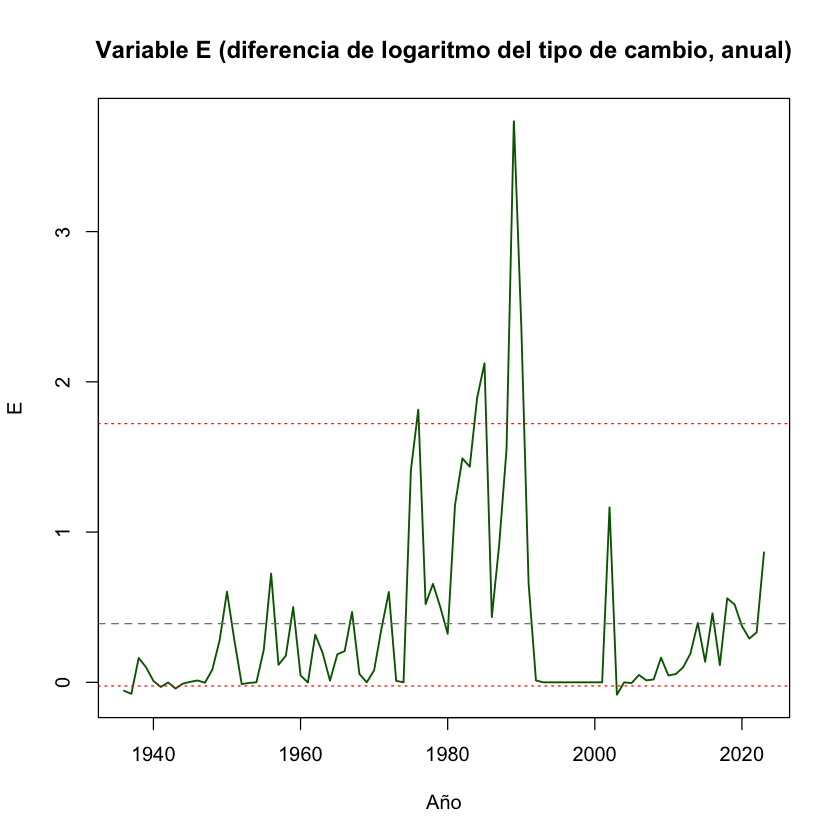

In [38]:
plot(df_anual_comb$año, df_anual_comb$E, type = "l", col = "darkgreen", lwd = 1.5,
     main = "Variable E (diferencia de logaritmo del tipo de cambio, anual)",
     xlab = "Año", ylab = "E")
abline(h = mean(df_anual_comb$E, na.rm = TRUE), col = "grey50", lty = 2)
abline(h = quantile(df_anual_comb$E, c(0.05, 0.95), na.rm = TRUE), col = "red", lty = 3)


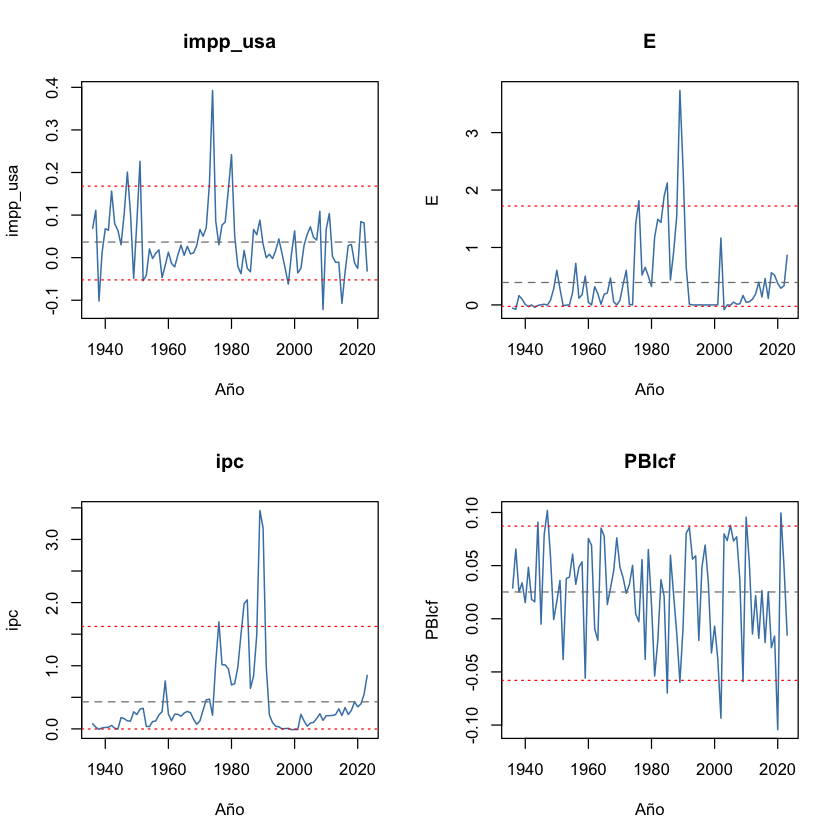

In [39]:
par(mfrow = c(2, 2))
for (v in c("impp_usa", "E", "ipc", "PBIcf")) {
  serie <- df_anual_comb[[v]]
  plot(df_anual_comb$año, serie, type = "l", col = "steelblue", lwd = 1.2,
       main = v, xlab = "Año", ylab = v)
  abline(h = mean(serie, na.rm = TRUE), col = "grey50", lty = 2)
  abline(h = quantile(serie, c(0.05, 0.95), na.rm = TRUE), col = "red", lty = 3)
}
par(mfrow = c(1, 1))


In [40]:
# SIN CAPPEO: se usan los datos originales (df_anual_comb), incluidos los valores extremos
vars_modelo <- c("impp_usa", "E", "ipc", "PBIcf")

cat("Desvíos estándar (datos sin cappear):\n")
print(sapply(df_anual_comb[, vars_modelo], sd, na.rm = TRUE))

# Los 5 años más extremos de E e ipc
for (v in c("E", "ipc")) {
  o <- order(abs(df_anual_comb[[v]]), decreasing = TRUE)[1:5]
  cat("\nAños más extremos de", v, ":\n")
  print(data.frame(año = df_anual_comb$año[o], valor = round(df_anual_comb[[v]][o], 3)), row.names = FALSE)
}


Desvíos estándar (datos sin cappear):


  impp_usa          E        ipc      PBIcf 
0.07653640 0.64353427 0.62510191 0.04611195 

Años más extremos de E :
  año valor
 1989 3.734
 1990 2.378
 1985 2.123
 1984 1.892
 1976 1.814

Años más extremos de ipc :
  año valor
 1989 3.459
 1990 3.184
 1985 2.044
 1984 1.983
 1976 1.694


## Selección de rezagos con criterios de información (VAR lineal)

Antes de estimar los modelos no lineales: criterios AIC, HQ, SC (= BIC) y FPE para un VAR lineal con las mismas cuatro variables, de 1 a 4 rezagos (con 88 años, más rezagos dejan muy pocos grados de libertad), todos sobre la misma muestra. Además, el test de Portmanteau ajustado de los residuos del VAR lineal para cada número de rezagos (orientativo, con 6 y 8 rezagos del test).


In [7]:
if (!requireNamespace("vars", quietly = TRUE)) install.packages("vars")
library(vars)

vars_modelo <- c("impp_usa", "E", "ipc", "PBIcf")
Y <- na.omit(df_anual_comb[, vars_modelo])
cat("Observaciones:", nrow(Y), "\n\n")

sel <- VARselect(Y, lag.max = 4, type = "const")
cat("Rezagos elegidos por cada criterio (SC = BIC):\n")
print(sel$selection)
cat("\nValores de los criterios (menor = mejor):\n")
print(round(sel$criteria, 4))

# Portmanteau ajustado de los residuos del VAR lineal, para cada p (orientativo).
# El test necesita más rezagos que el VAR: si no, queda NA.
p_port <- function(v, L) if (L > v$p) round(unname(serial.test(v, lags.pt = L, type = "PT.adjusted")$serial$p.value), 3) else NA
port_lineal <- do.call(rbind, lapply(1:4, function(p) {
  v <- VAR(Y, p = p, type = "const")
  data.frame(rezagos = p,
             p_autocorr_6 = p_port(v, 6), p_autocorr_8 = p_port(v, 8))
}))
cat("\nPortmanteau ajustado, VAR lineal (p-valor; < 0.05 = autocorrelación):\n")
print(port_lineal, row.names = FALSE)


Loading required package: MASS


Attaching package: ‘MASS’


The following object is masked from ‘package:plotly’:

    select


Loading required package: strucchange

Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric


Loading required package: sandwich

Loading required package: urca

Loading required package: lmtest



Observaciones: 88 

Rezagos elegidos por cada criterio (SC = BIC):
AIC(n)  HQ(n)  SC(n) FPE(n) 
     1      1      1      1 

Valores de los criterios (menor = mejor):
              1        2        3        4
AIC(n) -16.6785 -16.5206 -16.5275 -16.3668
HQ(n)  -16.4458 -16.1019 -15.9226 -15.5758
SC(n)  -16.0997 -15.4789 -15.0227 -14.3990
FPE(n)   0.0000   0.0000   0.0000   0.0000

Portmanteau ajustado, VAR lineal (p-valor; < 0.05 = autocorrelación):
 rezagos p_autocorr_6 p_autocorr_8
       1        0.053        0.019
       2        0.108        0.089
       3        0.406        0.413
       4        0.205        0.239


## TVAR p = 1 (especificación principal)

Se cargó exitosamente modelos preguardados  threshold_tvar_1_2_500_827bf0b1f3f7e97b528e8b2c99ed1601.rds  de la carpeta models

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , 4 , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


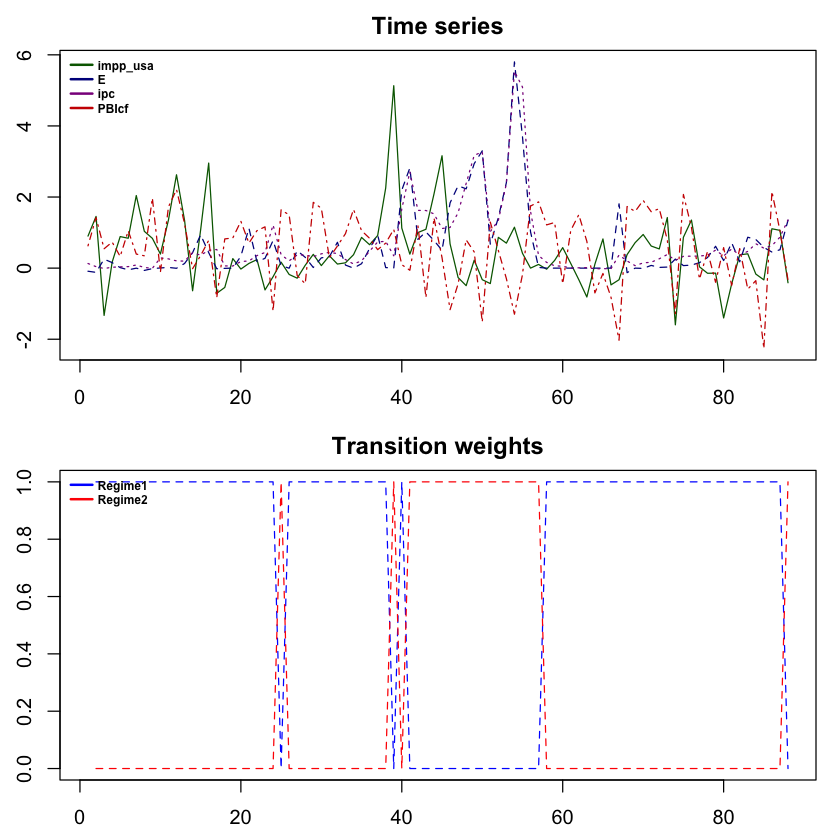

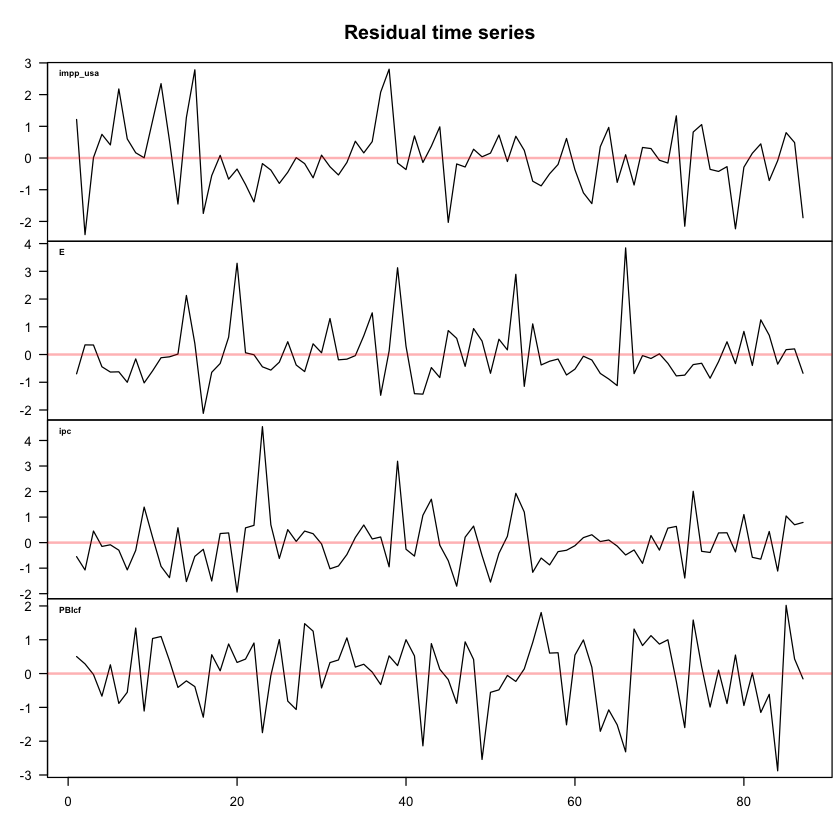

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



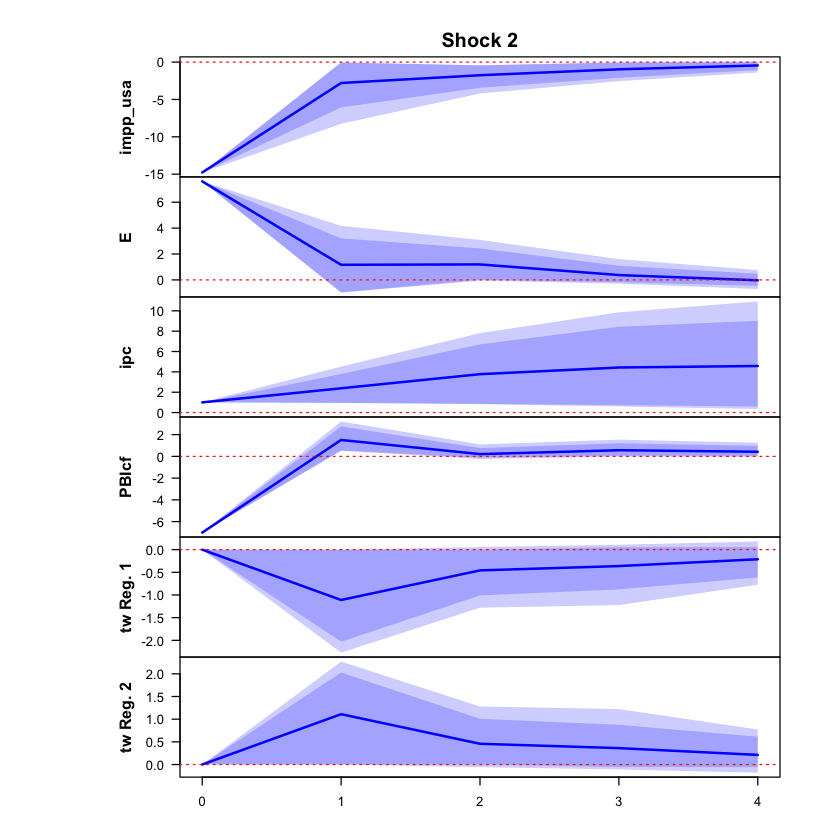

 >>> Linear IRF ( 1  shock units)


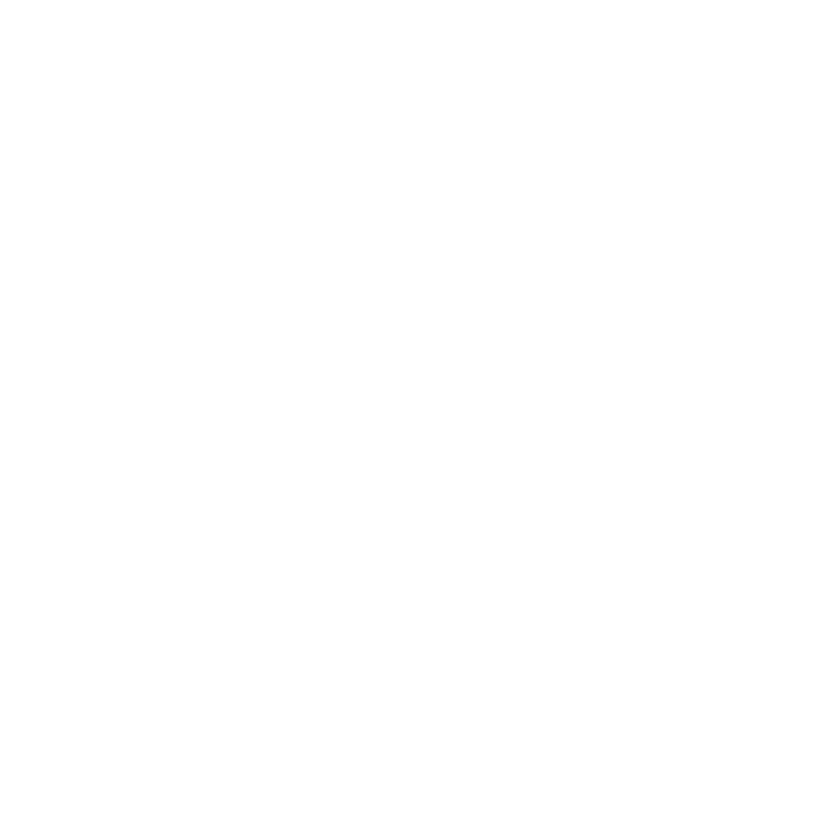

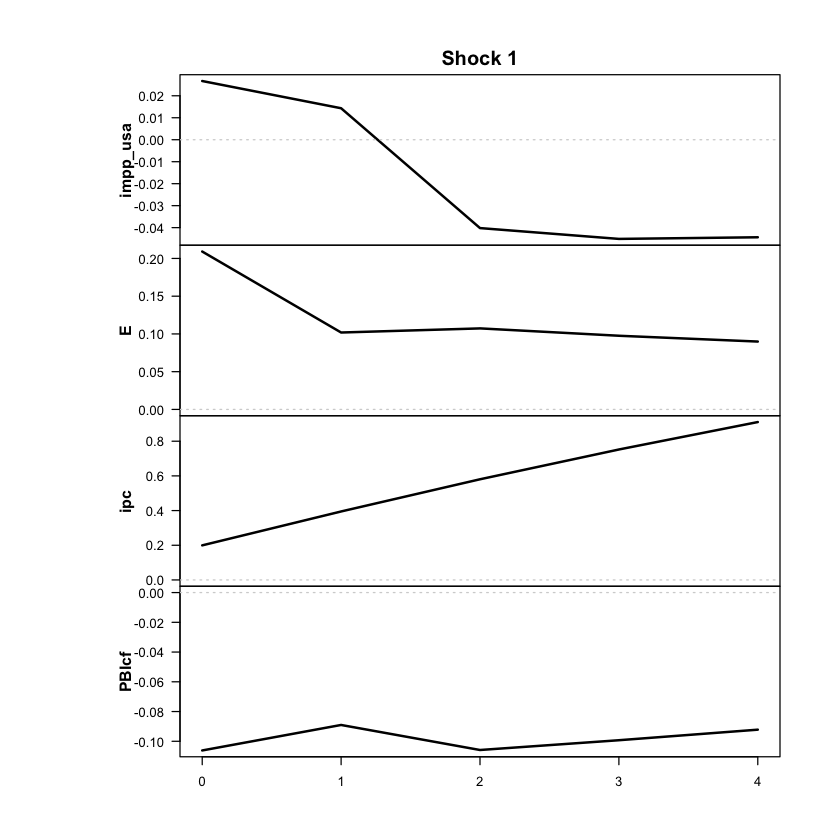

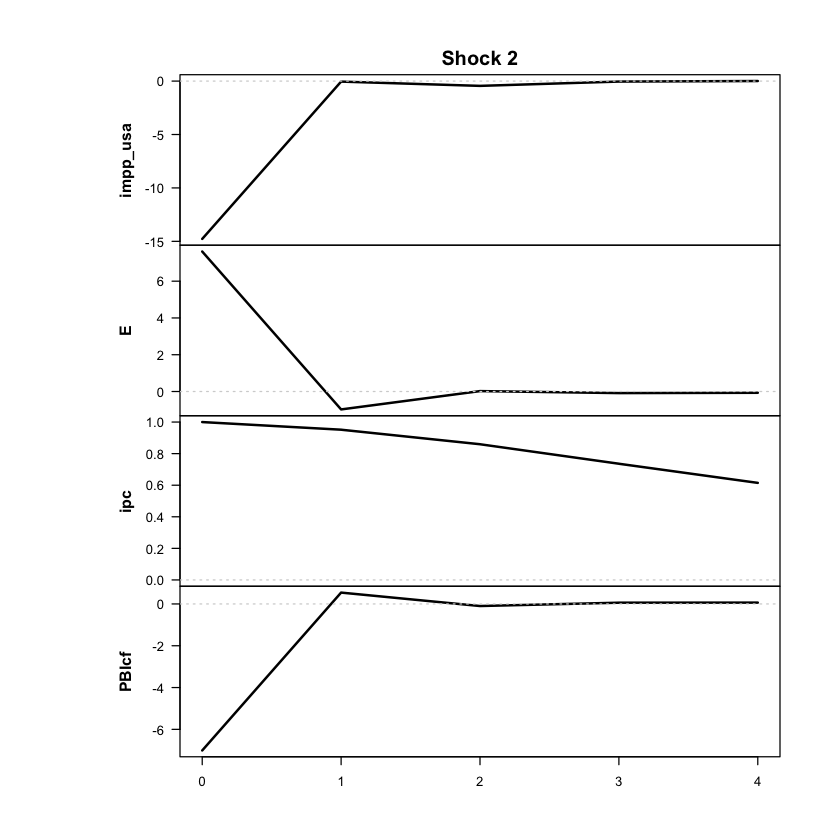

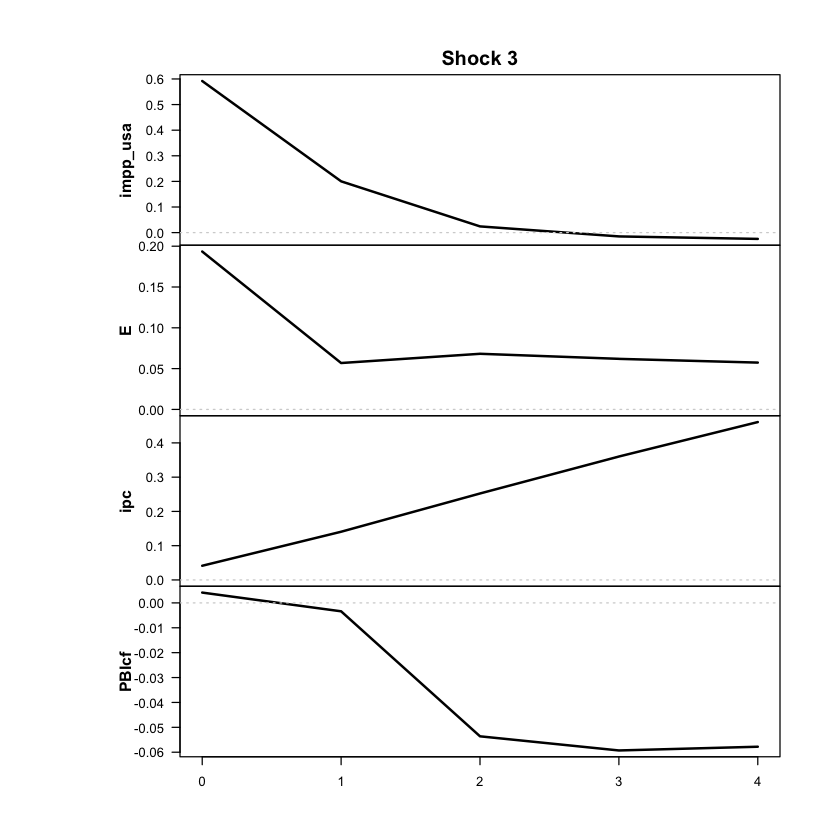

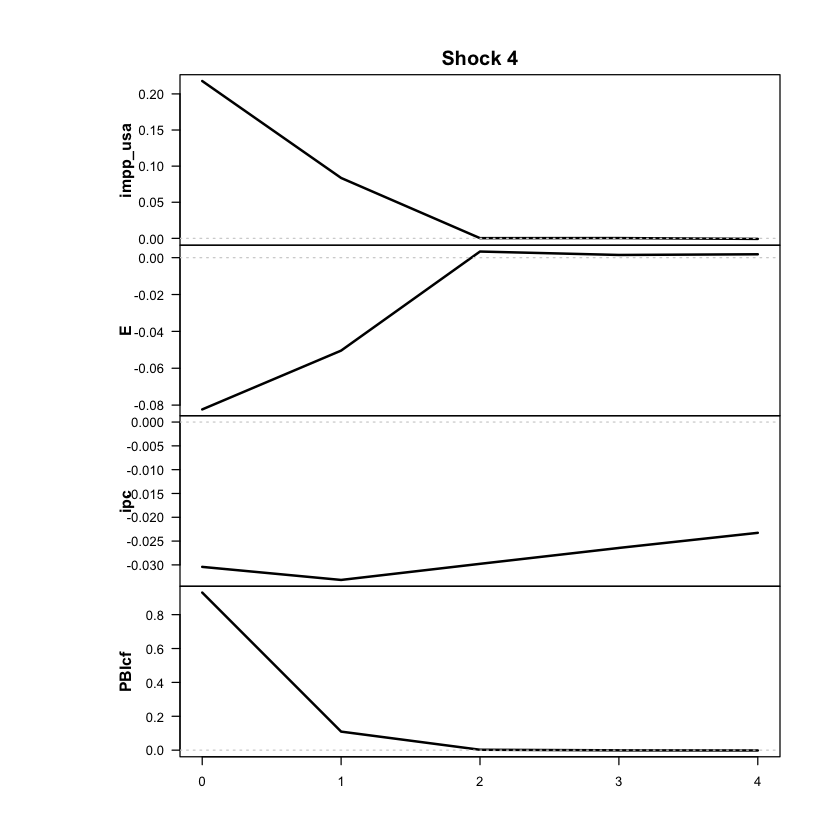

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



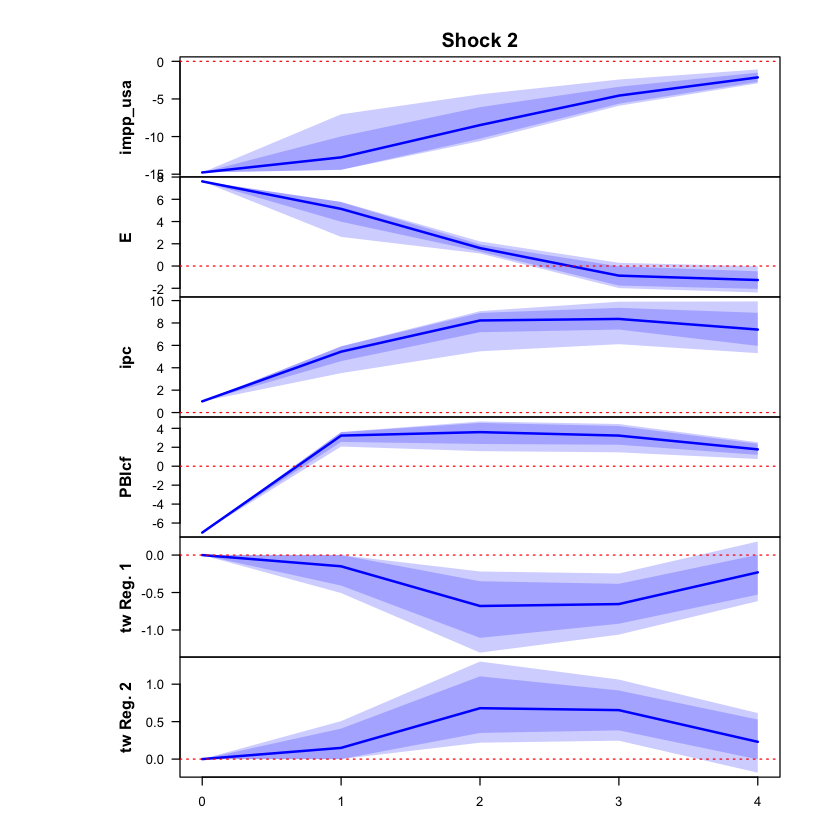

 >>> Linear IRF ( 1  shock units)


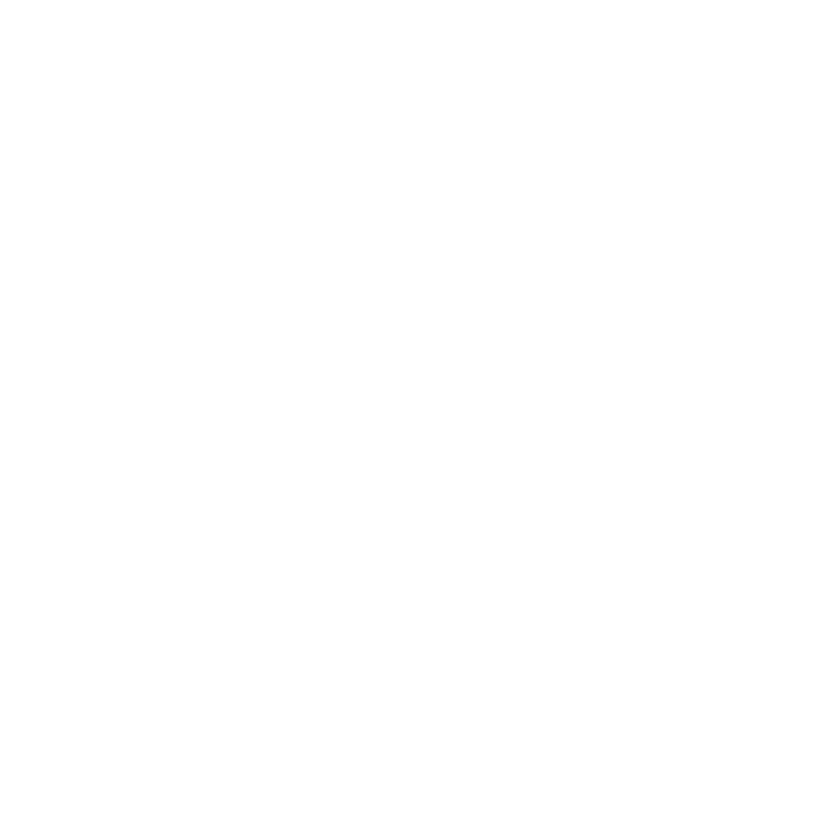

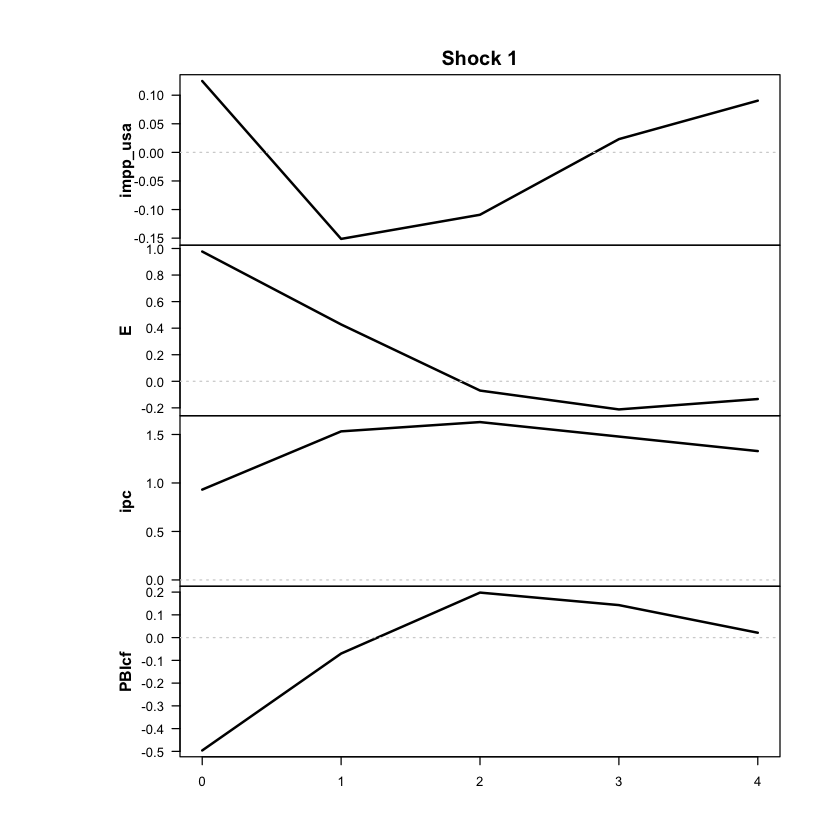

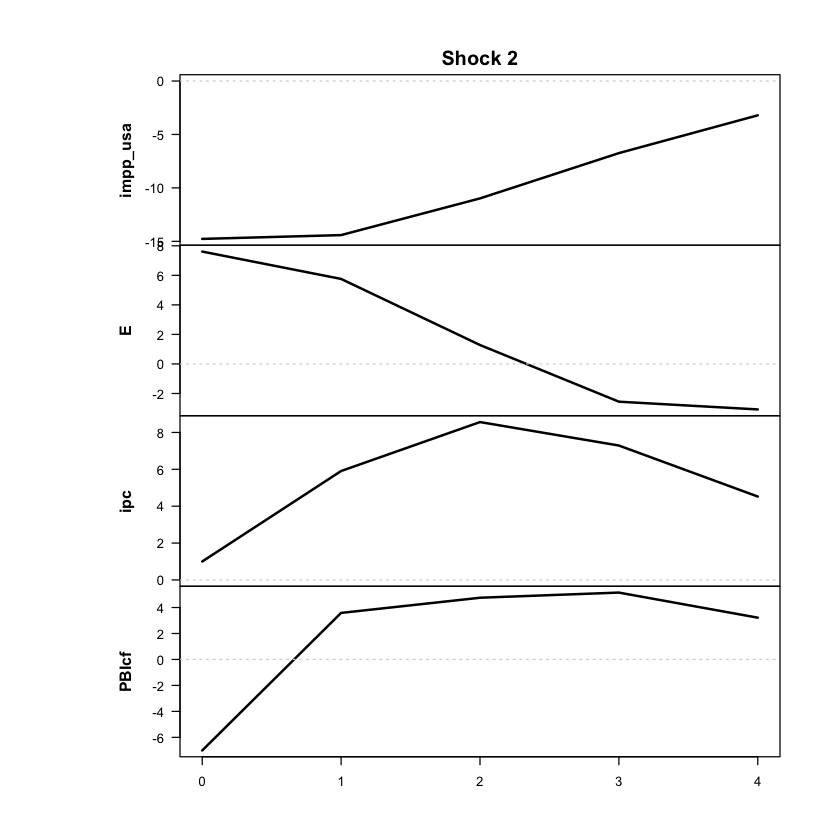

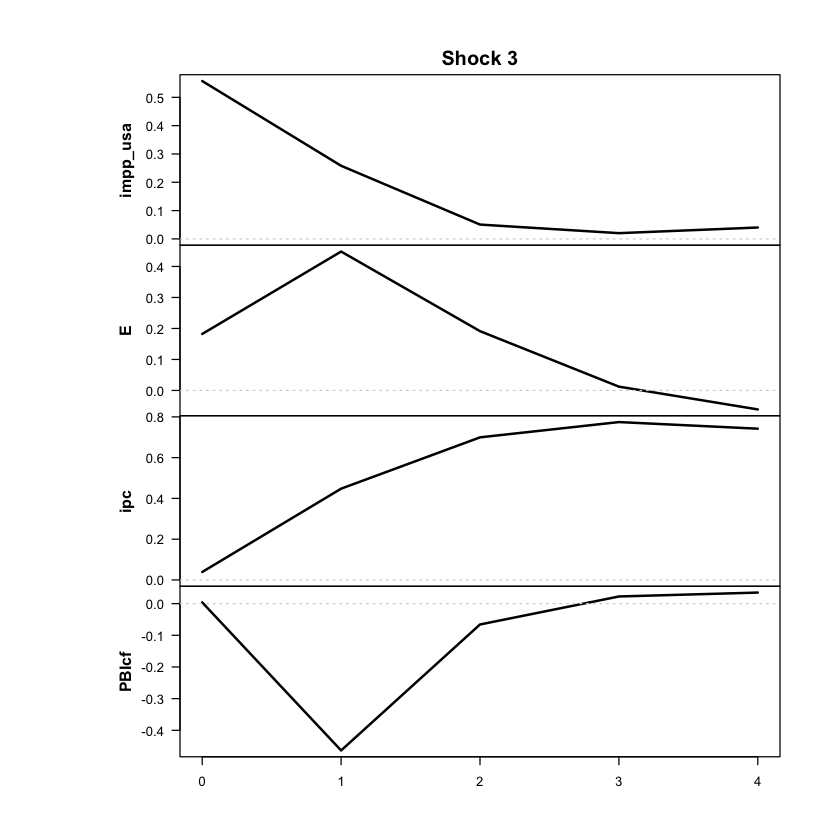

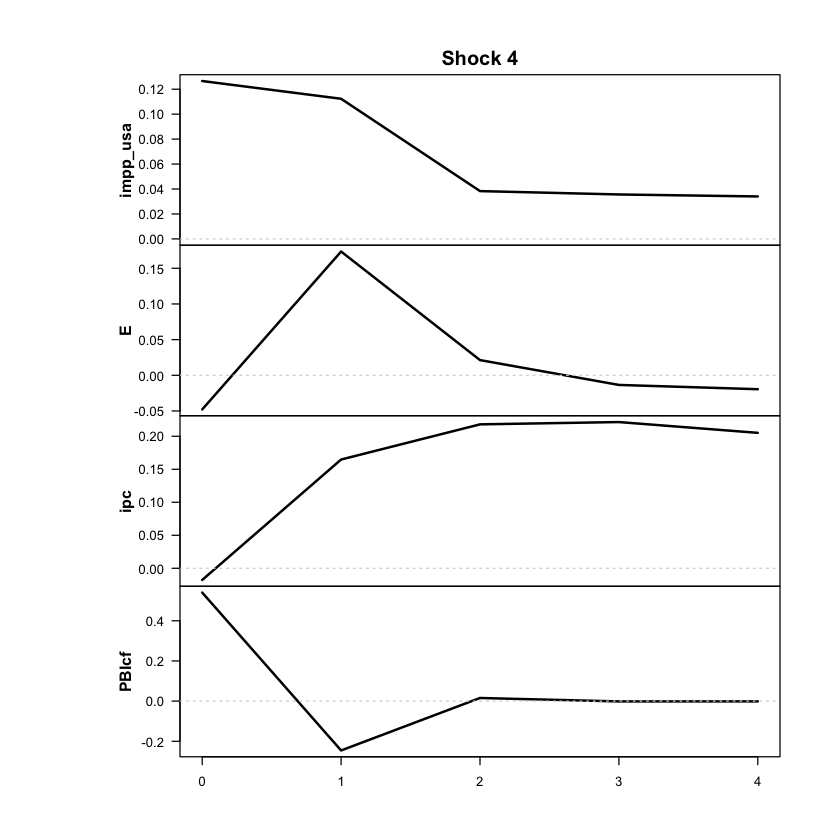

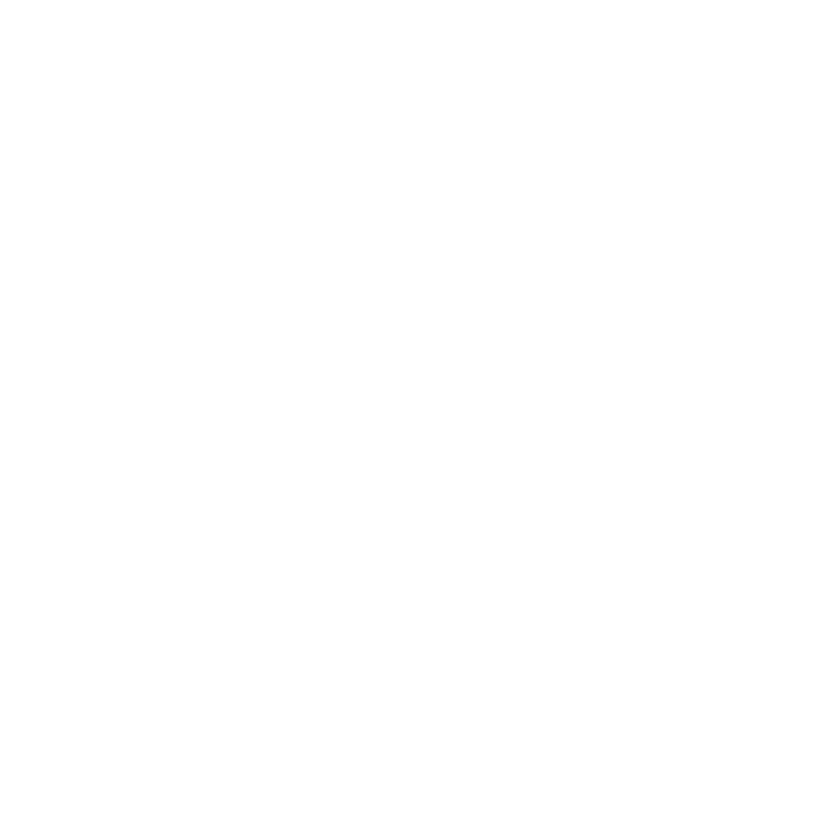

In [41]:
res <- run_threshold_tvar(
  data = df_anual_comb,
  endog = c("impp_usa","E","ipc","PBIcf"),
  periodicity = 'anual', # 'trimestral' o 'anual' o mensual
  feature_lag = 1,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIcf")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = TRUE   # primera corrida: estimar. Después de guardado, cambiar a TRUE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [42]:
ic_tvar_p1 <- criterios_info(res, "TVAR p=1")
print(ic_tvar_p1)
saveRDS(ic_tvar_p1, "ic_tvar_p1_anual_comb.rds")

    modelo regimenes parametros  loglik   AIC  HQ   BIC
1 TVAR p=1         2         61 -233.71 589.4 650 739.8


In [43]:
resumen_modelo(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"))

Modelo: threshold | regímenes: 2 | rezagos: 1 | errores: Gaussian 
Umbrales: 59.3% anual 
Años por régimen (régimen de mayor peso): régimen 1 = 67 | régimen 2 = 20 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      3.01      6.01
E            19.41    208.42
ipc          21.25    244.10
PBIcf         2.88      1.43


In [44]:
identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "PBIcf"))
# Debe sugerir el shock 2 (= posición de E). Si sugiere otro, avisar antes de seguir.

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0020 -0.0405  0.0453  0.0167
  E         0.1346  0.1756  0.1245 -0.0530
  ipc       0.1246  0.0224  0.0259 -0.0190
  PBIcf    -0.0049 -0.0116  0.0002  0.0429

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.68    0.42    0.31    0.09 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.926   0.128   0.208   0.359 

>>> Shock sugerido como cambiario: 1 (confirmalo: debe mover mucho a E y poco a ipc )


In [45]:
print_passthrough(res, endog = c("impp_usa","E","ipc","PBIcf"))

+++++++++ RÉGIMEN  1 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0       0.1276
1         1       0.3045
2         2       0.4815
3         3       0.5653
4         4       0.5844

>>> IRF lineal normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
1         0       0.1276
2         1       0.1214
3         2       0.1097
4         3       0.0939
5         4       0.0784

+++++++++ RÉGIMEN  2 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0       0.1276
1         1       0.6938
2         2       1.0495
3         3       1.0671
4         4       0.9458

>>> IRF lineal normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
1         0       0.1276
2         1       0.7539
3         2       1.0928
4         3       0.9304
5         4       0.5773



### ERPT y gráficos — TVAR p = 1

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 19.2%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIcf
         0 0.1276 -0.0660
         1 0.3098 -0.0519
         2 0.4906 -0.0501
         3 0.5741 -0.0448
         4 0.5940 -0.0409

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIcf
         0 0.1276 -0.0660
         1 0.6841 -0.0361
         2 1.0359 -0.0037
         3 1.0630  0.0254
         4 0.9533  0.0416


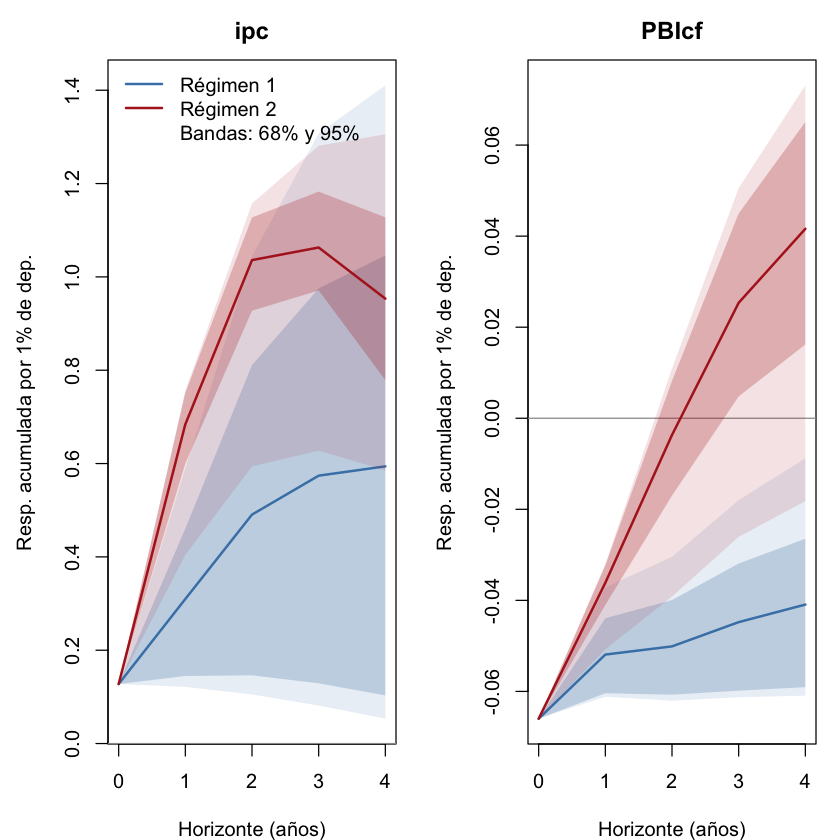


+++ Régimen 1 - IRF lineal acumulada por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIcf
         0 0.1276 -0.0660
         1 0.1214 -0.0609
         2 0.1097 -0.0618
         3 0.0939 -0.0612
         4 0.0784 -0.0606

+++ Régimen 2 - IRF lineal acumulada por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIcf
         0 0.1276 -0.0660
         1 0.7539 -0.0322
         2 1.0928  0.0125
         3 0.9304  0.0610
         4 0.5773  0.0913


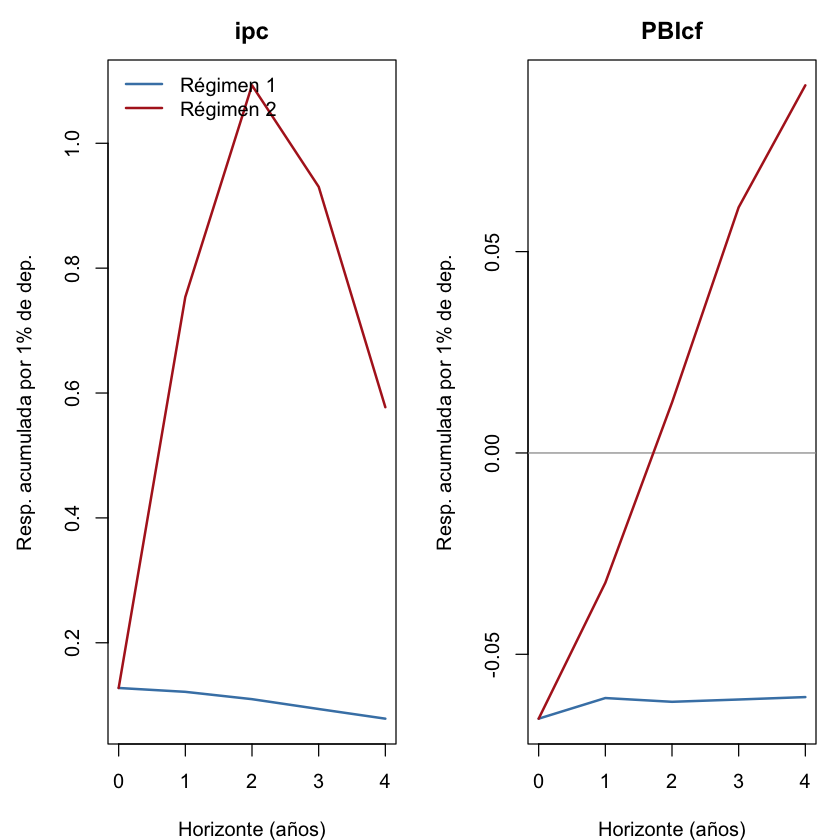

In [46]:
girf_impp_usa_tvar_p1 <- graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                        archivo = paste0(carpeta, "girf_original_impp_usa_tvar_p1_anual_comb"))
irf_impp_usa_tvar_p1  <- graficar_irf_original(res, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                       archivo = paste0(carpeta, "irf_original_impp_usa_tvar_p1_anual_comb"))

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 19.2%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte      E    ipc   PBIcf
         0 1.0000 0.1276 -0.0660
         1 1.1604 0.3098 -0.0519
         2 1.3194 0.4906 -0.0501
         3 1.3665 0.5741 -0.0448
         4 1.3636 0.5940 -0.0409

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte      E    ipc   PBIcf
         0 1.0000 0.1276 -0.0660
         1 1.6614 0.6841 -0.0361
         2 1.8726 1.0359 -0.0037
         3 1.7732 1.0630  0.0254
         4 1.6193 0.9533  0.0416


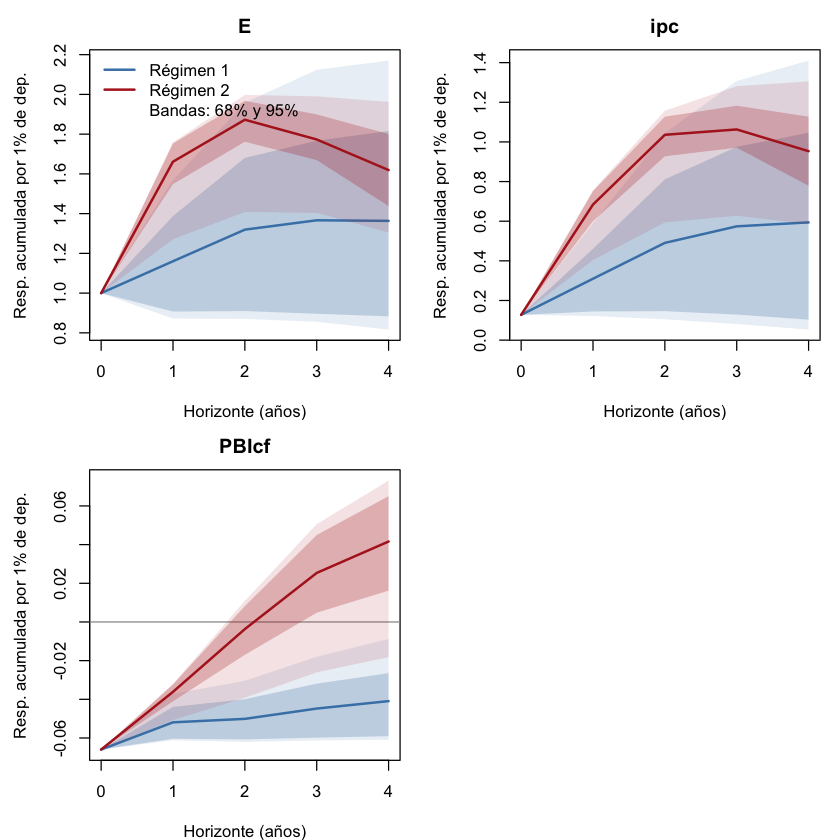

In [47]:
graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                       variables = c("E", "ipc", "PBIcf"),
                       archivo = paste0(carpeta, "girf_original_impp_usa_tvar_p1_con_E_anual_comb"))

In [48]:
out_impp_usa_tvar_p1 <- erpt_historia(res, data = df_anual_comb,
                             endog = c("impp_usa", "E", "ipc", "PBIcf"))

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 19.2%.

Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...



Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 67 | régimen 2 = 20 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9714

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.1276            0.1276
2         1            0.2019            0.6607
3         2            0.2553            0.9922
4         3            0.2652            1.0166
5         4            0.2449            0.9037

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.1276           0.1276
2         1           0.1716           0.7065
3         2           0.1819           1.0612
4         3           0.1655           1.0570
5         4           0.1365           0.9072


In [49]:
out_impp_usa_tvar_p1_acum <- erpt_historia(res, data = df_anual_comb,
                                  endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                  definicion = "acumulado")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 19.2%.

Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 67 | régimen 2 = 20 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9714

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.1276            0.1276
2         1            0.1923            0.4026
3         2            0.2171            0.5392
4         3            0.2168            0.5837
5         4            0.1972            0.5705

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.1276           0.1276
2         1           0.1826           0.4171
3         2           0.1911           0.5631
4         3           0.1786           0.6050
5         4           0.1511           0.5782


HTML widgets cannot be represented in plain text (need html)

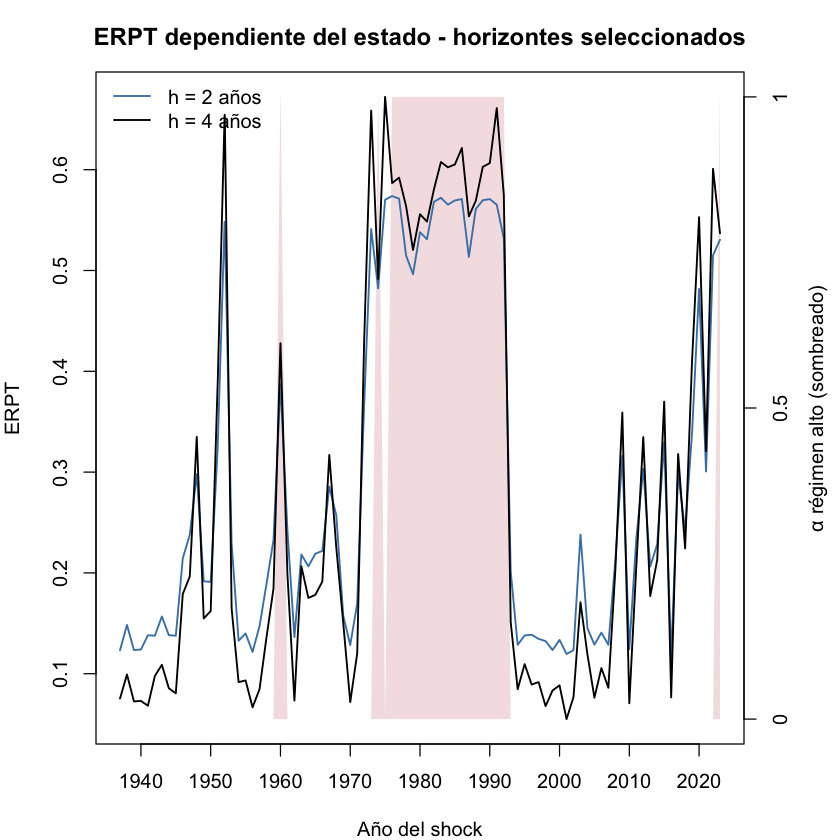

In [50]:
graficar_erpt(out_impp_usa_tvar_p1_acum, archivo = paste0(carpeta, "erpt_impp_usa_tvar_p1_acum_anual_comb"))

In [26]:
#Lo comento porque es feo, es de puntos (para bajar el tamaño de la notebook)
#graficar_erpt_regimen_3d(out_impp_usa_tvar_p1_acum,
                         #archivo = paste0(carpeta, "erpt_regimen_3d_impp_usa_tvar_p1_acum_anual_comb"))

In [ ]:
#Lo comento porque es feo, es de rayas verticales (para bajar el tamaño de la notebook)
#graficar_erpt_regimen_red(out_impp_usa_tvar_p1_acum, h = 4,
                          #archivo = paste0(carpeta, "erpt_red_impp_usa_tvar_p1_acum_h4_anual_comb"))

Promedio de ERPT por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_original reg_alto_original
         4             0.197             0.571


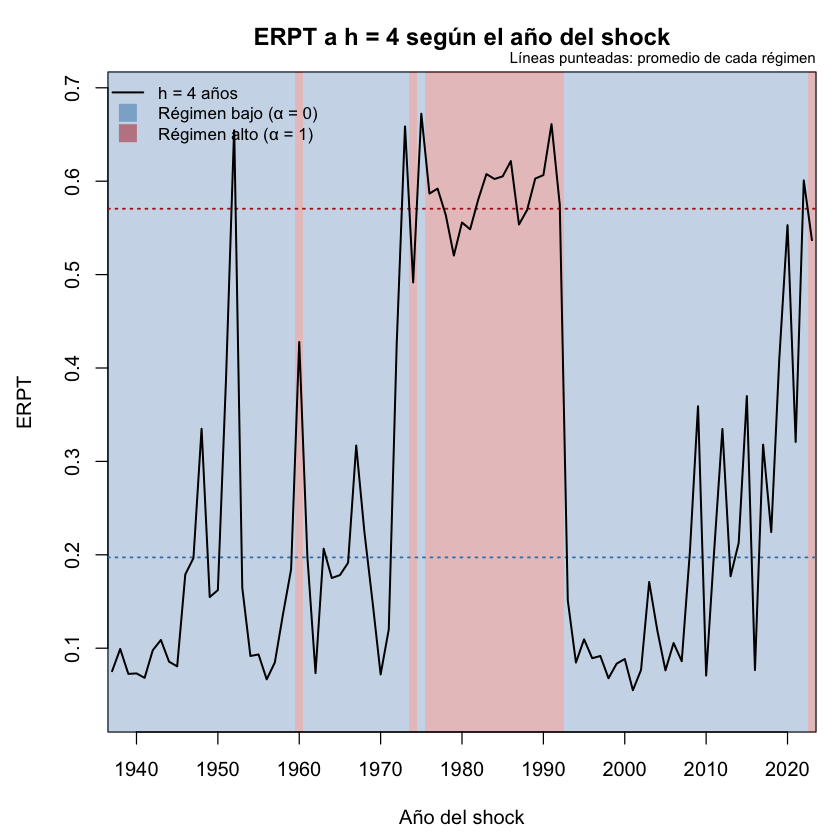

In [51]:
graficar_erpt_2d_bandas(out_impp_usa_tvar_p1_acum, horizontes = 4,
                        archivo = paste0(carpeta, "erpt_2d_bandas_impp_usa_tvar_p1_acum_anual_comb"))

HTML widgets cannot be represented in plain text (need html)

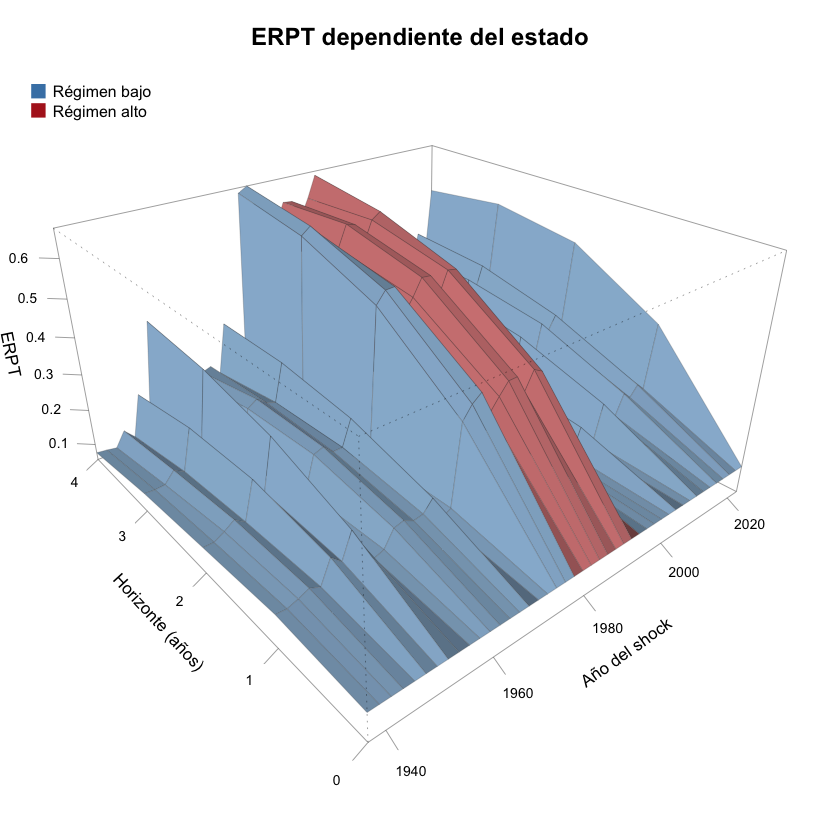

In [52]:
graficar_erpt_manta(out_impp_usa_tvar_p1_acum, cada = 2,
                    archivo = paste0(carpeta, "erpt_manta_impp_usa_tvar_p1_acum_c2_anual_comb"))

In [15]:
#Lo comenté porque es muy parecido al anterior, así achico la notebook
#graficar_erpt_manta(out_impp_usa_tvar_p1_acum, archivo = paste0(carpeta, "erpt_manta_impp_usa_tvar_p1_acum_c1_anual_comb"))

In [ ]:
#Lo comenté para achicar la notebook, total es muy parecido a los anteriores.
#graficar_erpt_manta(out_impp_usa_tvar_p1_acum, cada = 2, theta = -25, phi = 30,
                    #archivo = paste0(carpeta, "erpt_manta_impp_usa_tvar_p1_acum_c2_theta25_anual_comb"))

El gif a continuación es muy, muy claro. USAR esta versión

In [53]:
guardar_gif_erpt_h(out_impp_usa_tvar_p1_acum, h = 4,
                   archivo = paste0(carpeta, "gif_erpt_h4_impp_usa_tvar_p1_acum_anual_comb"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_erpt_h4_impp_usa_tvar_p1_acum_anual_comb.gif



In [54]:
guardar_gif_erpt_h(out_impp_usa_tvar_p1_acum, h = 4,
                   marcas = c(1975, 1989, 2002, 2018),
                   archivo = paste0(carpeta, "gif_erpt_h4_marcas_impp_usa_tvar_p1_acum_anual_comb"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_erpt_h4_marcas_impp_usa_tvar_p1_acum_anual_comb.gif



GIF 3d modo "construir"

In [55]:
guardar_gif_manta(out_impp_usa_tvar_p1_acum, modo = "construir",
                  archivo = paste0(carpeta, "gif_manta_construir_impp_usa_tvar_p1_acum_anual_comb"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_manta_construir_impp_usa_tvar_p1_acum_anual_comb.gif



In [56]:
guardar_gif_manta(out_impp_usa_tvar_p1_acum, modo = "construir",
                  marcas = c(1975, 1989, 2002, 2018),
                  archivo = paste0(carpeta, "gif_manta_construir_marcas_impp_usa_tvar_p1_acum_anual_comb"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_manta_construir_marcas_impp_usa_tvar_p1_acum_anual_comb.gif



GIF 3d modo "rotar"

In [57]:
guardar_gif_manta(out_impp_usa_tvar_p1_acum, modo = "rotar",
                  archivo = paste0(carpeta, "gif_manta_rotar_impp_usa_tvar_p1_acum_anual_comb"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_manta_rotar_impp_usa_tvar_p1_acum_anual_comb.gif



In [58]:
guardar_gif_manta(out_impp_usa_tvar_p1_acum, modo = "rotar",
                  marcas = c(1975, 1989, 2002, 2018),
                  archivo = paste0(carpeta, "gif_manta_rotar_marcas_impp_usa_tvar_p1_acum_anual_comb"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_manta_rotar_marcas_impp_usa_tvar_p1_acum_anual_comb.gif



In [59]:
graficar_slider(out_impp_usa_tvar_p1_acum, archivo = paste0(carpeta, "slider_impp_usa_tvar_p1_acum_anual_comb"))

HTML widgets cannot be represented in plain text (need html)

 horizonte   1987   1988   1989   1990
         0 0.1276 0.1276 0.1276 0.1276
         1 0.3819 0.4200 0.4269 0.4293
         2 0.5135 0.5610 0.5697 0.5708
         3 0.5606 0.5989 0.6155 0.6165
         4 0.5537 0.5692 0.6028 0.6065


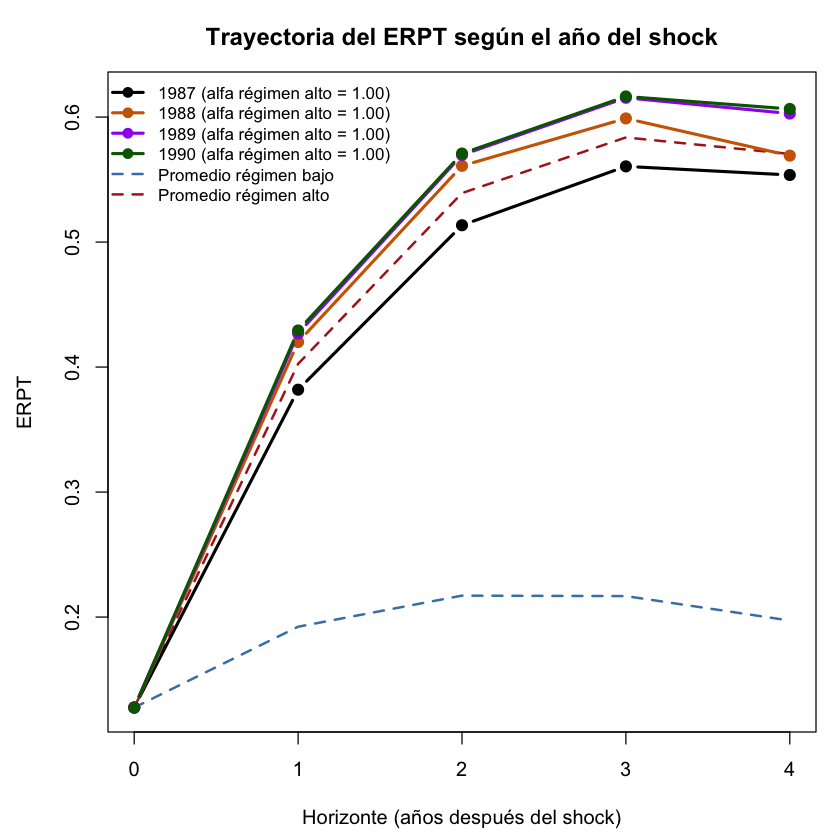

In [60]:
graficar_trayectorias(out_impp_usa_tvar_p1_acum,
                      trimestres = c(1987, 1988, 1989, 1990),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_acum_1987_1988_1989_1990_anual_comb"))

 horizonte   1973   1974   1975   1976
         0 0.1276 0.1276 0.1276 0.1276
         1 0.3778 0.3598 0.4097 0.4277
         2 0.5411 0.4823 0.5702 0.5739
         3 0.6221 0.5182 0.6407 0.6164
         4 0.6586 0.4916 0.6722 0.5867


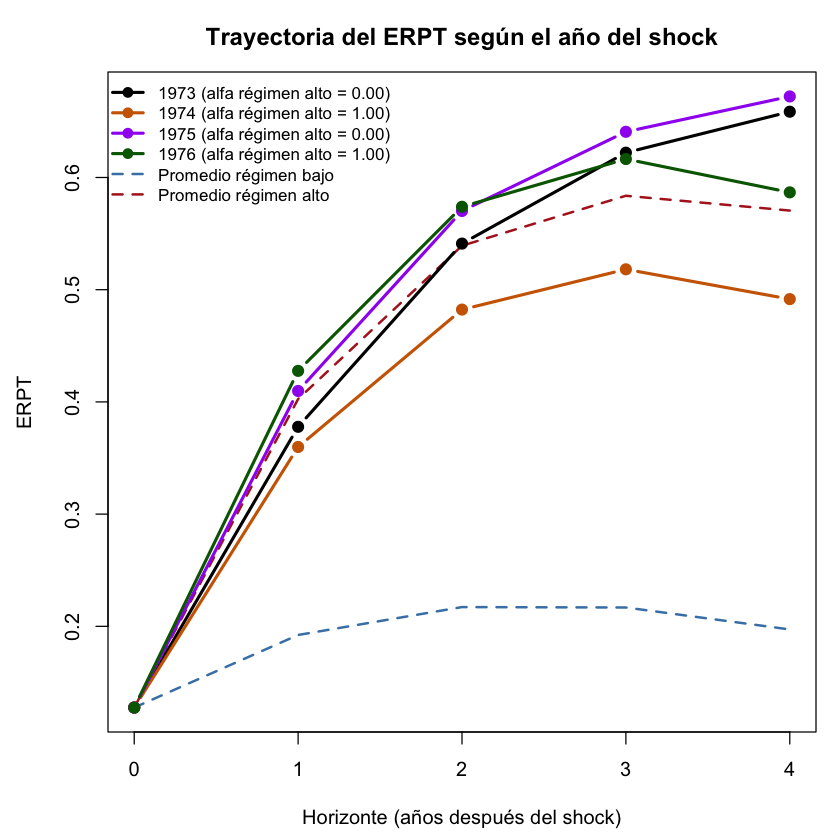

In [61]:
graficar_trayectorias(out_impp_usa_tvar_p1_acum,
                      trimestres = c(1973, 1974, 1975, 1976),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_acum_1973_1974_1975_1976_anual_comb"))

 horizonte   1989   1990   1991   1992
         0 0.1276 0.1276 0.1276 0.1276
         1 0.4269 0.4293 0.4141 0.3963
         2 0.5697 0.5708 0.5653 0.5322
         3 0.6155 0.6165 0.6317 0.5823
         4 0.6028 0.6065 0.6611 0.5760


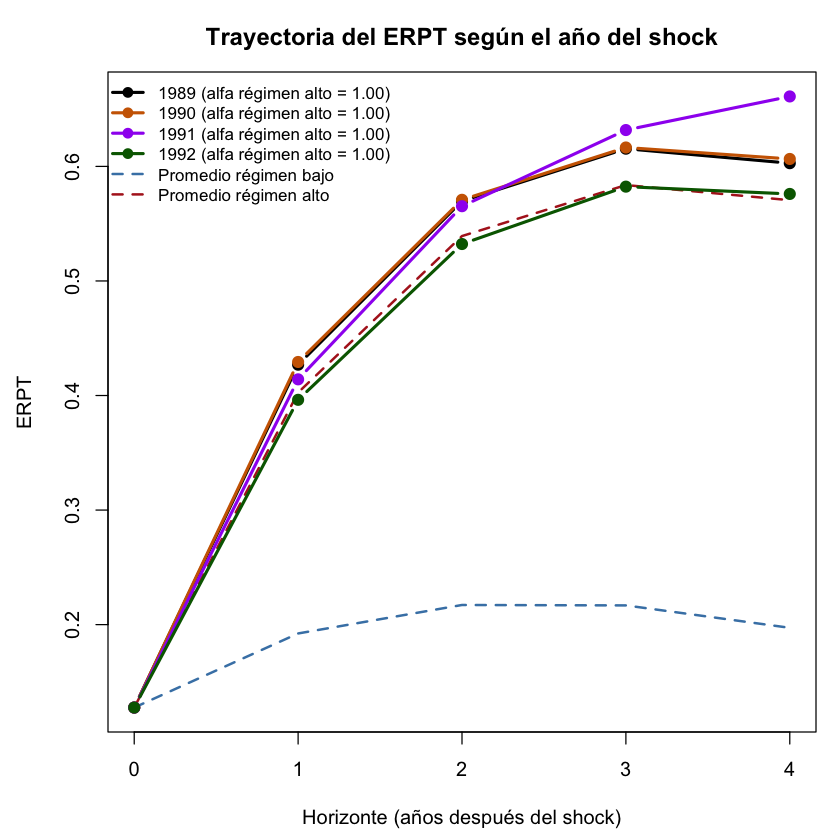

In [62]:
graficar_trayectorias(out_impp_usa_tvar_p1_acum,
                      trimestres = c(1989, 1990, 1991, 1992),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_acum_1989_1990_1991_1992_anual_comb"))

 horizonte   2001   2002   2003   2004
         0 0.1276 0.1276 0.1276 0.1276
         1 0.1410 0.1397 0.2075 0.1517
         2 0.1196 0.1234 0.2380 0.1451
         3 0.0910 0.0997 0.2256 0.1338
         4 0.0550 0.0767 0.1709 0.1190


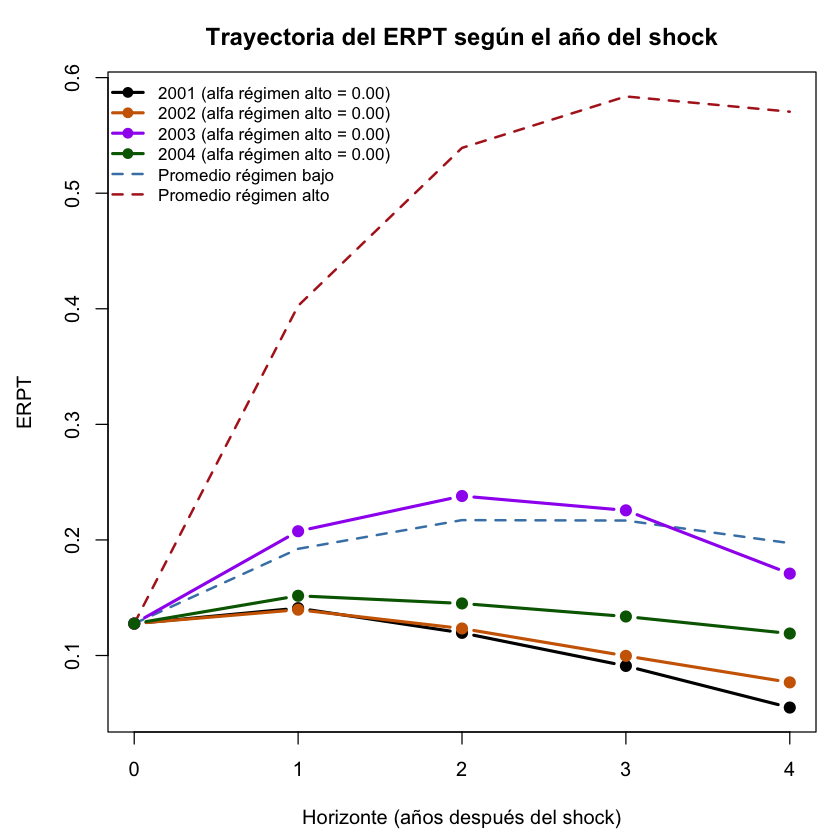

In [63]:
graficar_trayectorias(out_impp_usa_tvar_p1_acum,
                      trimestres = c(2001, 2002, 2003, 2004),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_acum_2001_2002_2003_2004_anual_comb"))

 horizonte   2016   2017   2018   2019
         0 0.1276 0.1276 0.1276 0.1276
         1 0.1360 0.2216 0.2028 0.2480
         2 0.1157 0.2985 0.2422 0.3394
         3 0.1018 0.3230 0.2495 0.3934
         4 0.0766 0.3179 0.2243 0.4113


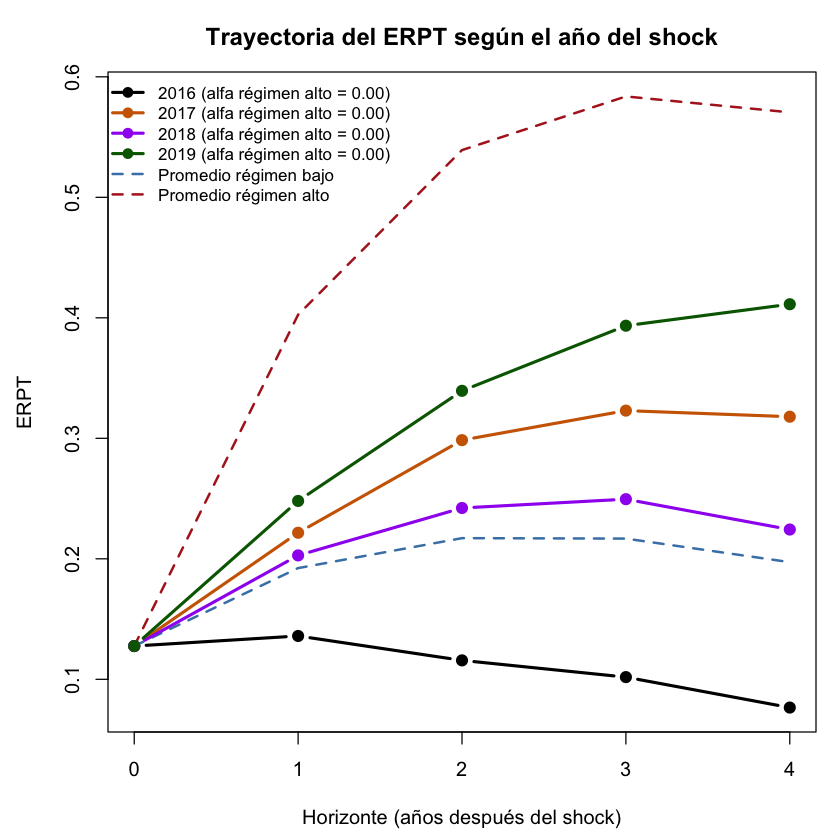

In [64]:
graficar_trayectorias(out_impp_usa_tvar_p1_acum,
                      trimestres = c(2016, 2017, 2018, 2019),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_acum_2016_2017_2018_2019_anual_comb"))

 horizonte   1950   1983   1988   2002
         0 0.1276 0.1276 0.1276 0.1276
         1 0.1814 0.4270 0.4200 0.1397
         2 0.1911 0.5721 0.5610 0.1234
         3 0.1795 0.6222 0.5989 0.0997
         4 0.1622 0.6076 0.5692 0.0767


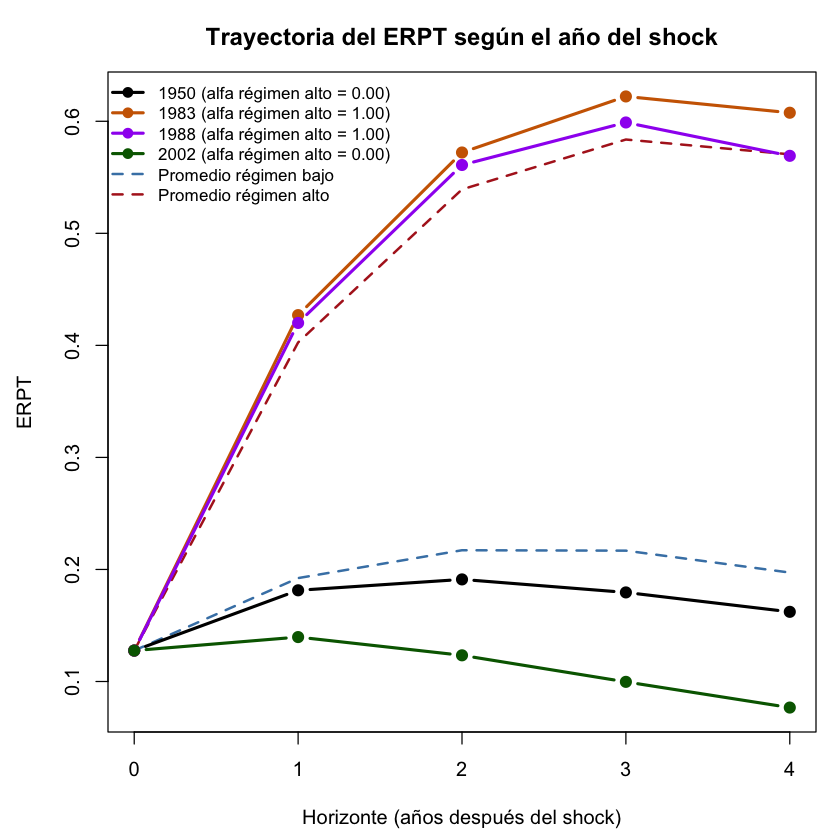

In [65]:
graficar_trayectorias(out_impp_usa_tvar_p1_acum,
                      trimestres = c(1950, 1983, 1988, 2002),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_acum_1950_1983_1988_2002_anual_comb"))

In [66]:
guardar_gif(out_impp_usa_tvar_p1_acum, archivo = paste0(carpeta, "gif_impp_usa_tvar_p1_acum_anual_comb"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_impp_usa_tvar_p1_acum_anual_comb.gif



In [67]:
guardar_gif(out_impp_usa_tvar_p1_acum, archivo = paste0(carpeta, "gif_impp_usa_tvar_p1_acum_lento_anual_comb"),
            segundos_por_cuadro = 0.5, cada = 2)

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_impp_usa_tvar_p1_acum_lento_anual_comb.gif



  horizonte reg_bajo_original reg_alto_original
1         0            0.1276            0.1276
2         1            0.0647            0.2750
3         2            0.0249            0.1366
4         3           -0.0004            0.0445
5         4           -0.0196           -0.0132


HTML widgets cannot be represented in plain text (need html)

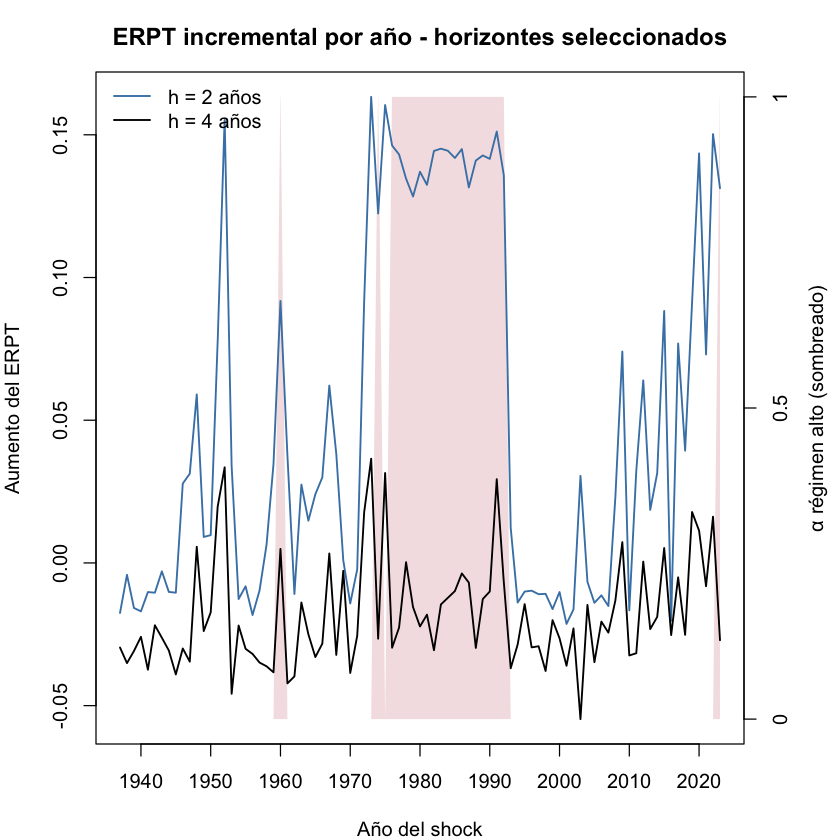

In [68]:
inc_impp_usa_tvar_p1_acum <- erpt_incremental(out_impp_usa_tvar_p1_acum)
graficar_erpt(inc_impp_usa_tvar_p1_acum, archivo = paste0(carpeta, "erpt_impp_usa_tvar_p1_acum_incremental_anual_comb"),
              titulo = "ERPT incremental por año", eje_z = "Aumento del ERPT")

HTML widgets cannot be represented in plain text (need html)

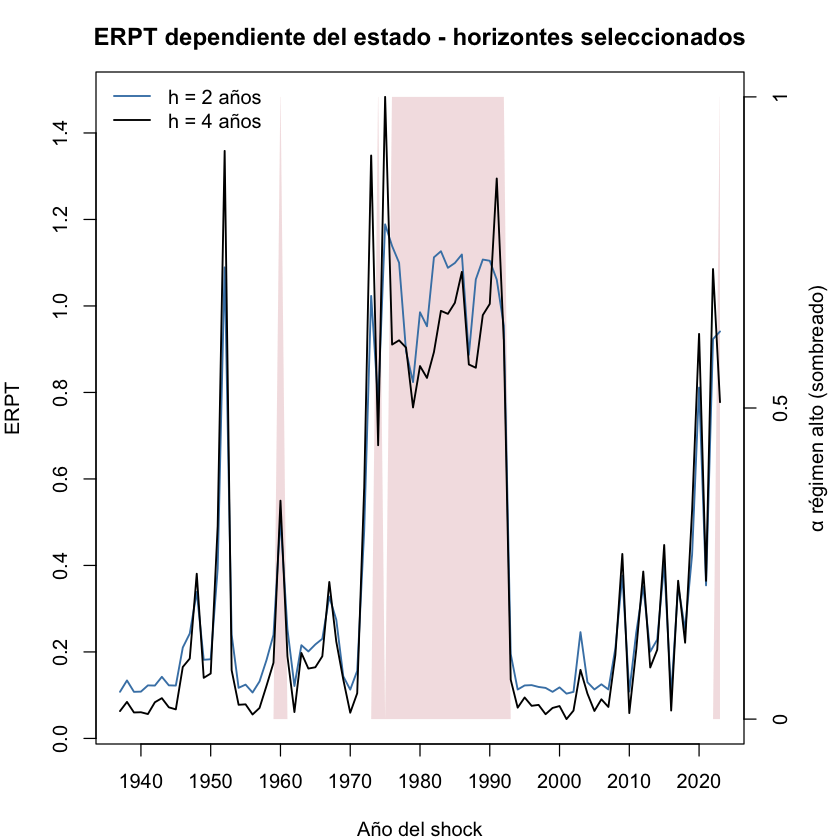

In [69]:
graficar_erpt(out_impp_usa_tvar_p1, archivo = paste0(carpeta, "erpt_impp_usa_tvar_p1_anual_comb"))

In [70]:
graficar_slider(out_impp_usa_tvar_p1, archivo = paste0(carpeta, "slider_impp_usa_tvar_p1_anual_comb"))

HTML widgets cannot be represented in plain text (need html)

 horizonte   1975   2014
         0 0.1276 0.1276
         1 0.6928 0.1895
         2 1.1887 0.2285
         3 1.3999 0.2292
         4 1.4834 0.2049


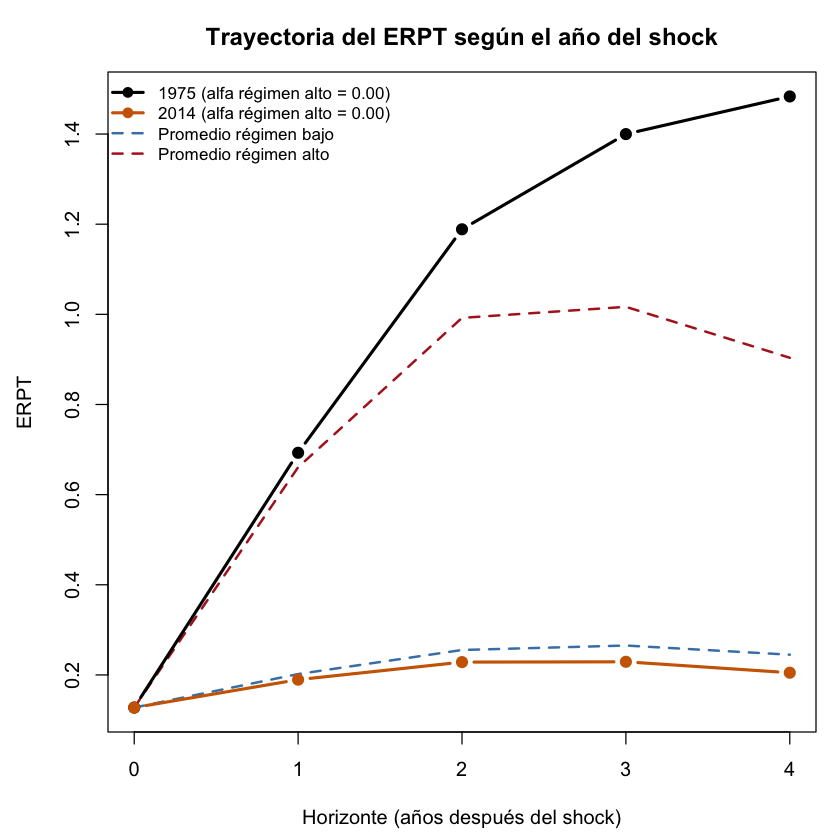

In [71]:
graficar_trayectorias(out_impp_usa_tvar_p1,
                      trimestres = c(1975, 2014),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_1975_2014_anual_comb"))

 horizonte   1995   1985   2021
         0 0.1276 0.1276 0.1276
         1 0.1309 0.7473 0.2460
         2 0.1225 1.0994 0.3540
         3 0.1084 1.1206 0.3882
         4 0.0947 1.0073 0.3645


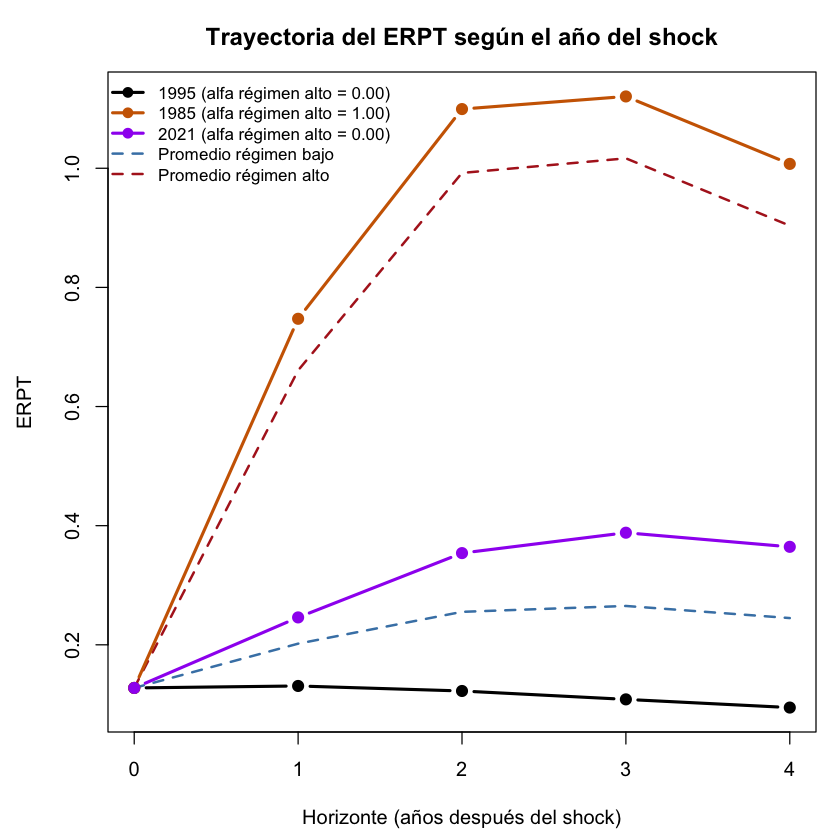

In [72]:
graficar_trayectorias(out_impp_usa_tvar_p1,
                      trimestres = c(1995, 1985, 2021),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_1995_1985_2021_anual_comb"))

In [73]:
guardar_gif(out_impp_usa_tvar_p1, archivo = paste0(carpeta, "gif_impp_usa_tvar_p1_anual_comb"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_impp_usa_tvar_p1_anual_comb.gif



  horizonte reg_bajo_original reg_alto_original
1         0            0.1276            0.1276
2         1            0.0743            0.5331
3         2            0.0534            0.3315
4         3            0.0099            0.0245
5         4           -0.0203           -0.1130


HTML widgets cannot be represented in plain text (need html)

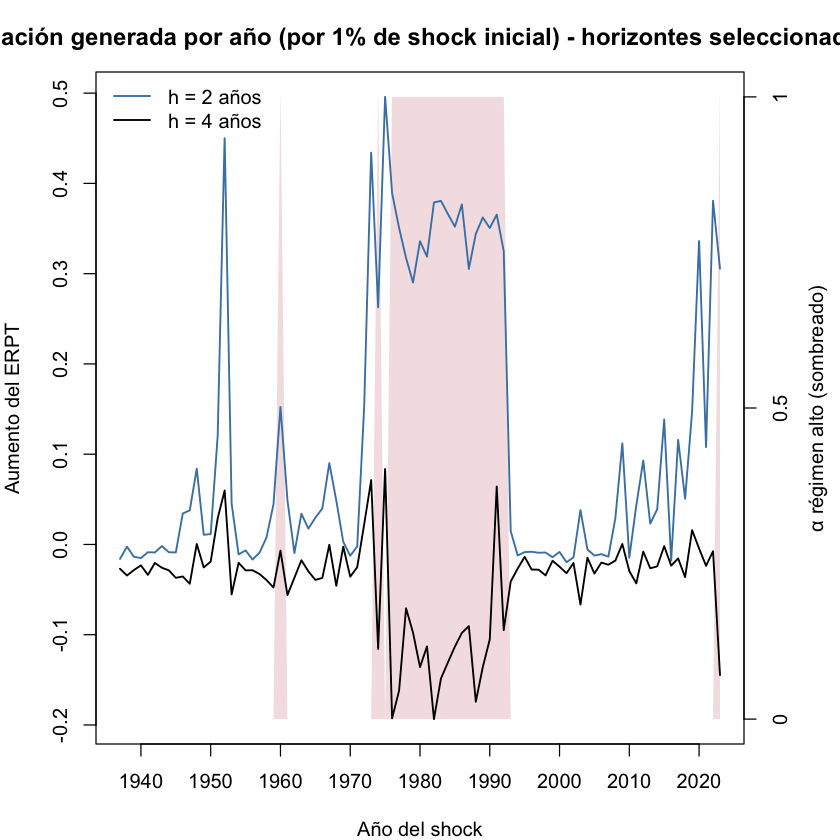

In [74]:
inc_impp_usa_tvar_p1 <- erpt_incremental(out_impp_usa_tvar_p1)
graficar_erpt(inc_impp_usa_tvar_p1, archivo = paste0(carpeta, "erpt_impp_usa_tvar_p1_incremental_anual_comb"),
              titulo = "Inflación generada por año (por 1% de shock inicial)",
              eje_z = "Aumento del ERPT")

Umbrales (inflación anual de t-1): 59.3% anual 
Años por régimen: régimen 1 = 67 | régimen 2 = 20 


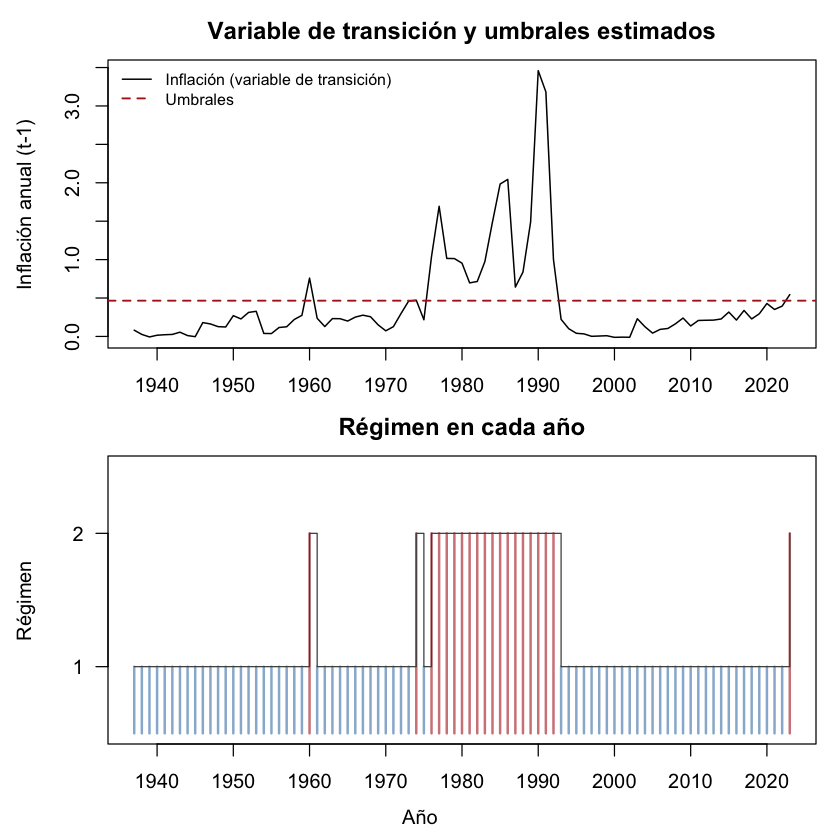

In [75]:
graficar_transicion(res, data = df_anual_comb,
                    endog = c("impp_usa", "E", "ipc", "PBIcf"),
                    archivo = paste0(carpeta, "transicion_impp_usa_tvar_p1_anual_comb"))

In [76]:
exists("out_impp_usa_tvar_p1"); exists("out_impp_usa_tvar_p1_acum")

[1] TRUE

[1] TRUE

In [77]:
pers_p1 <- out_impp_usa_tvar_p1$erpt / out_impp_usa_tvar_p1_acum$erpt
bajo_p1 <- .normalizar_out(out_impp_usa_tvar_p1)$regimen == 1
round(apply(pers_p1[, bajo_p1], 1, median), 2)   # mediana del régimen bajo, h = 0 a 4

0    1    2    3    4 
1.00 0.94 0.96 0.94 0.91

## TVAR p = 2 (robustez)

Se cargó exitosamente modelos preguardados  threshold_tvar_2_2_500_0d7ab9eb6aa8686499dabe3ee8ffe043.rds  de la carpeta models

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , 4 , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


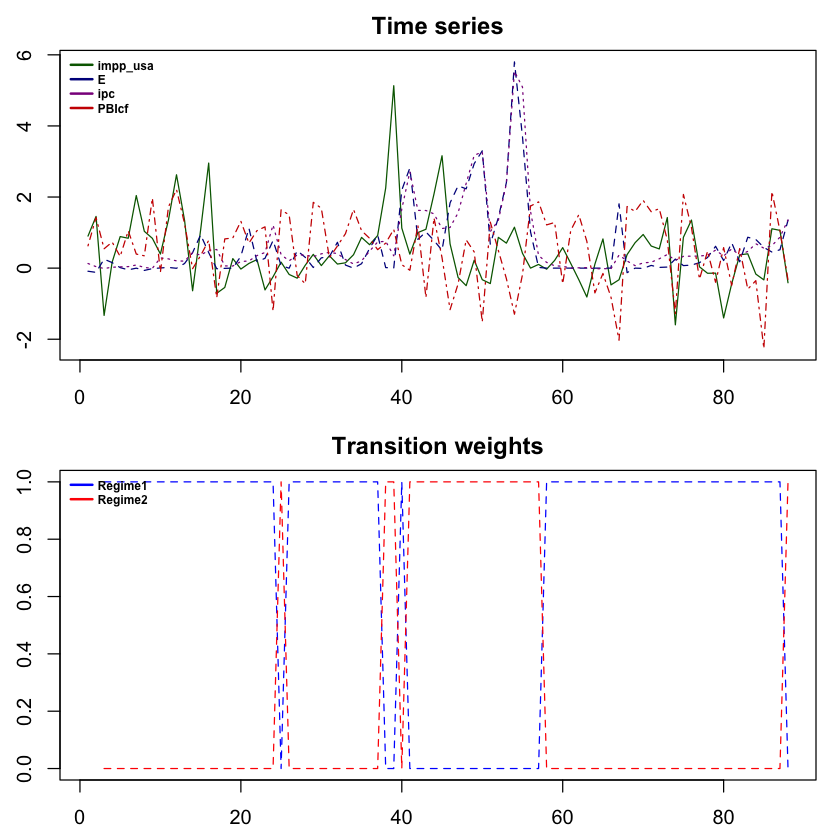

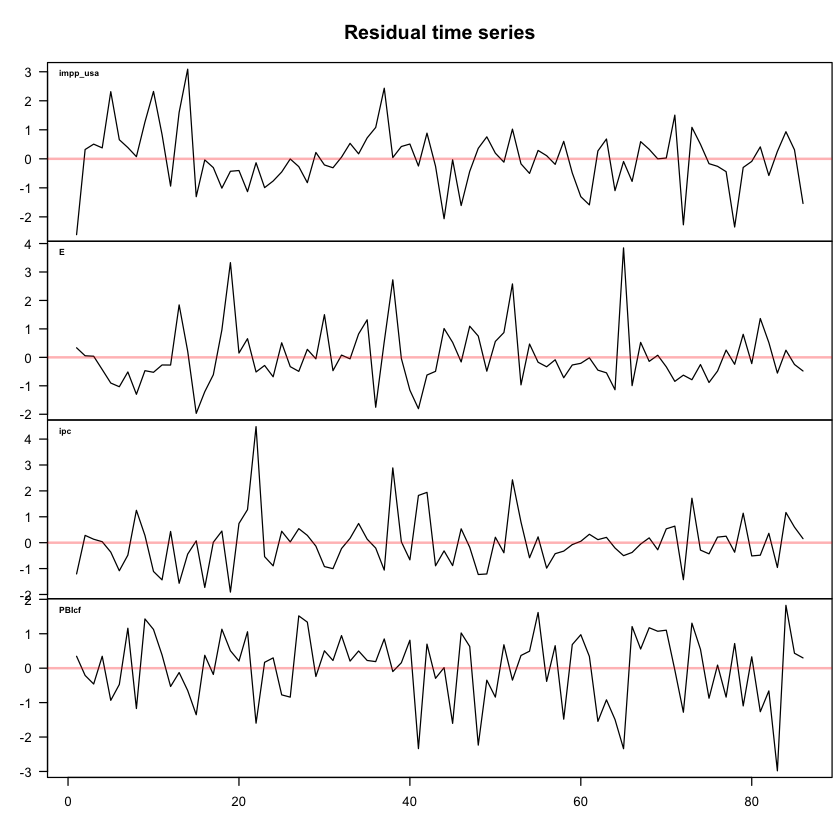

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



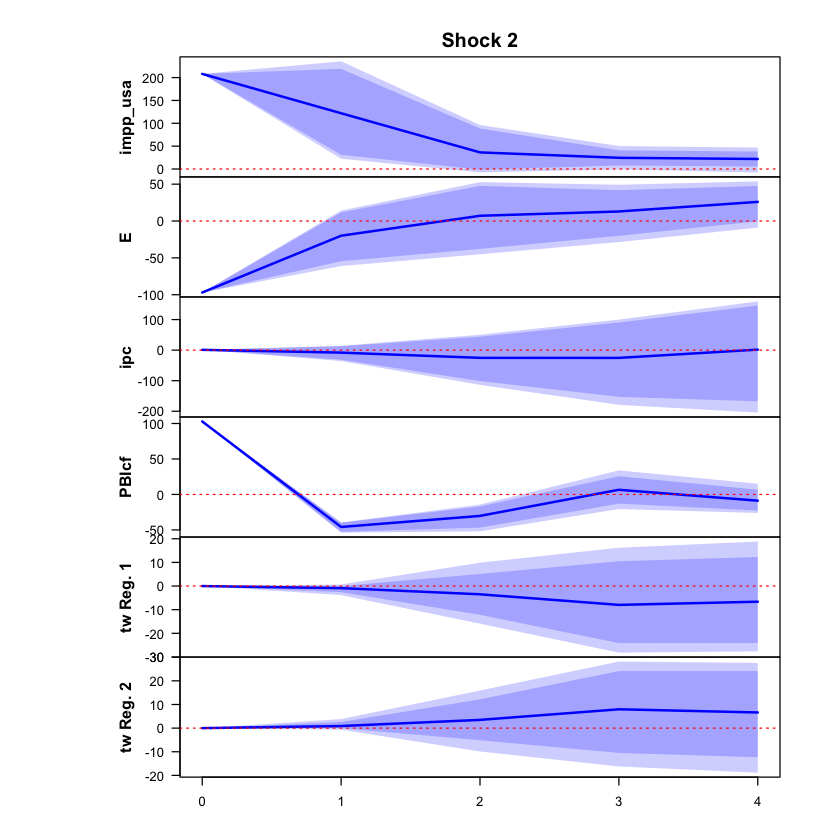

 >>> Linear IRF ( 1  shock units)


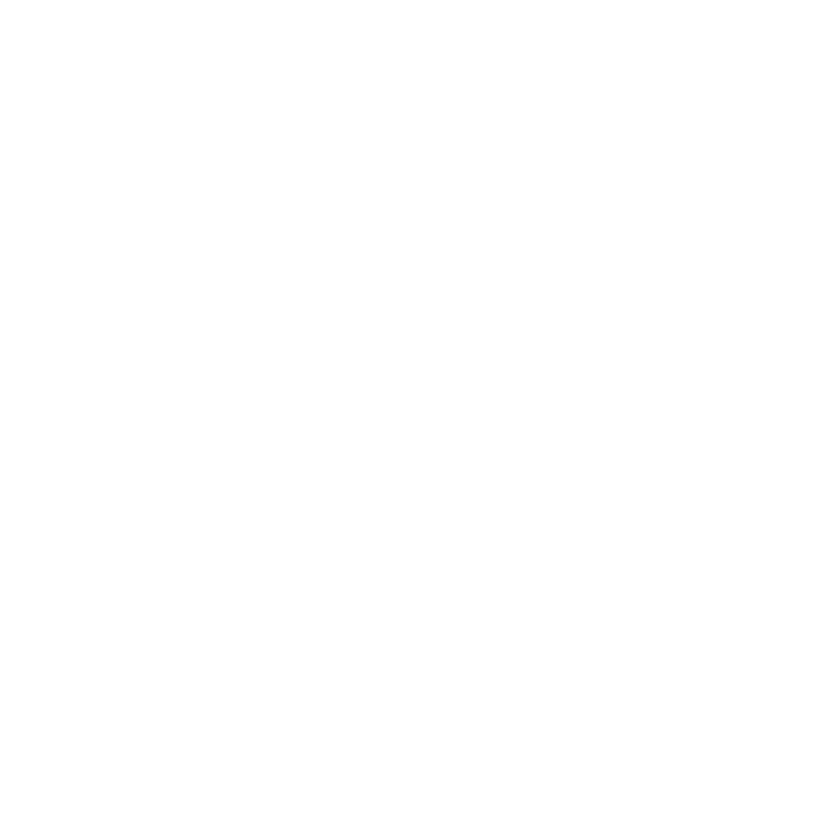

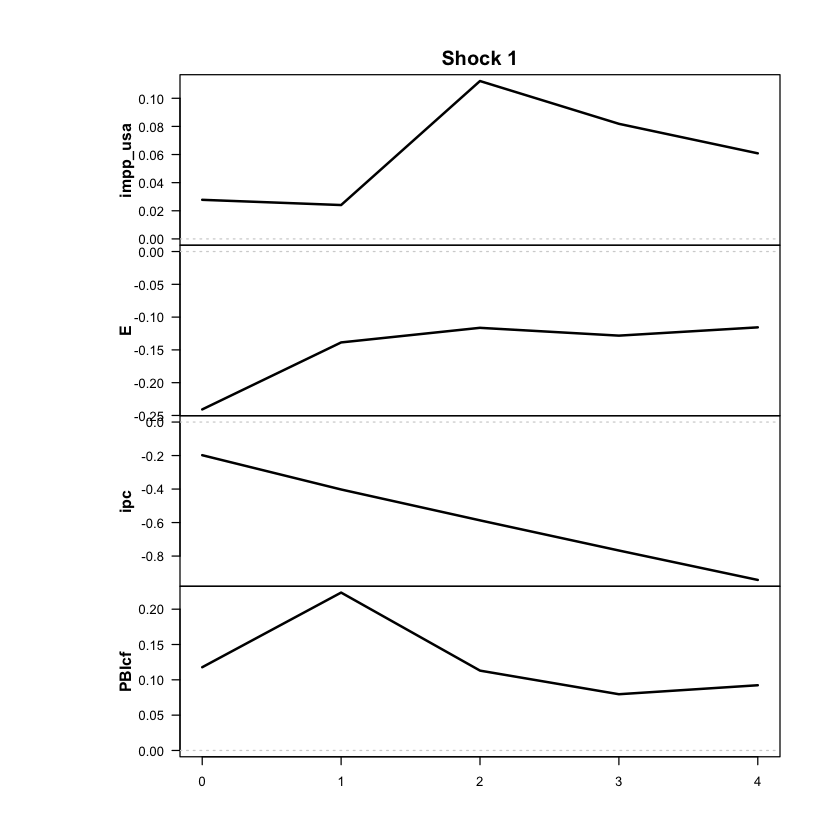

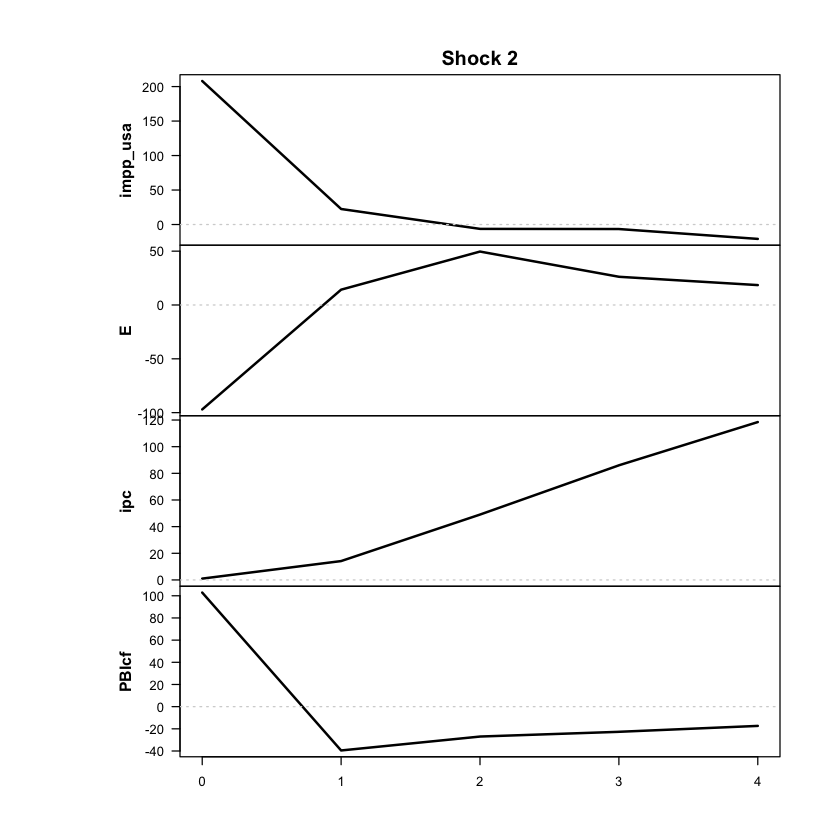

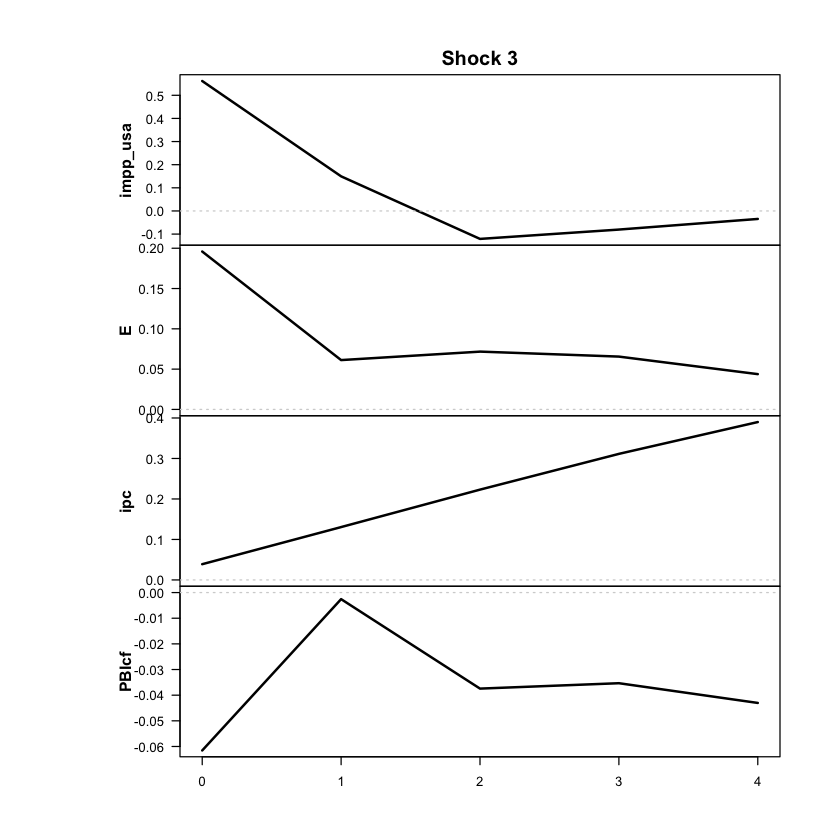

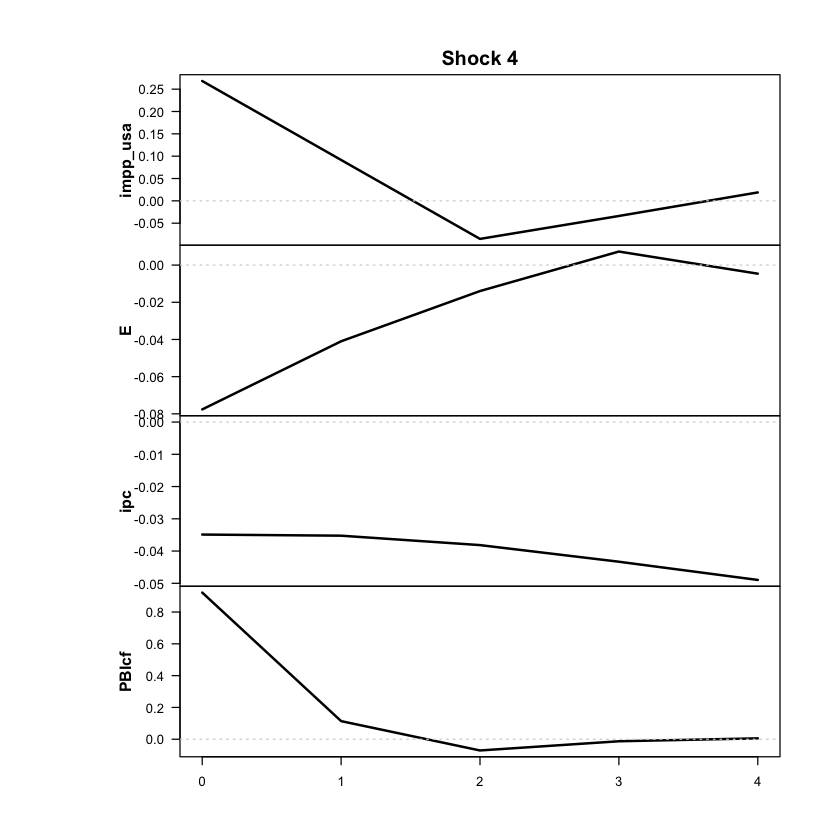

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



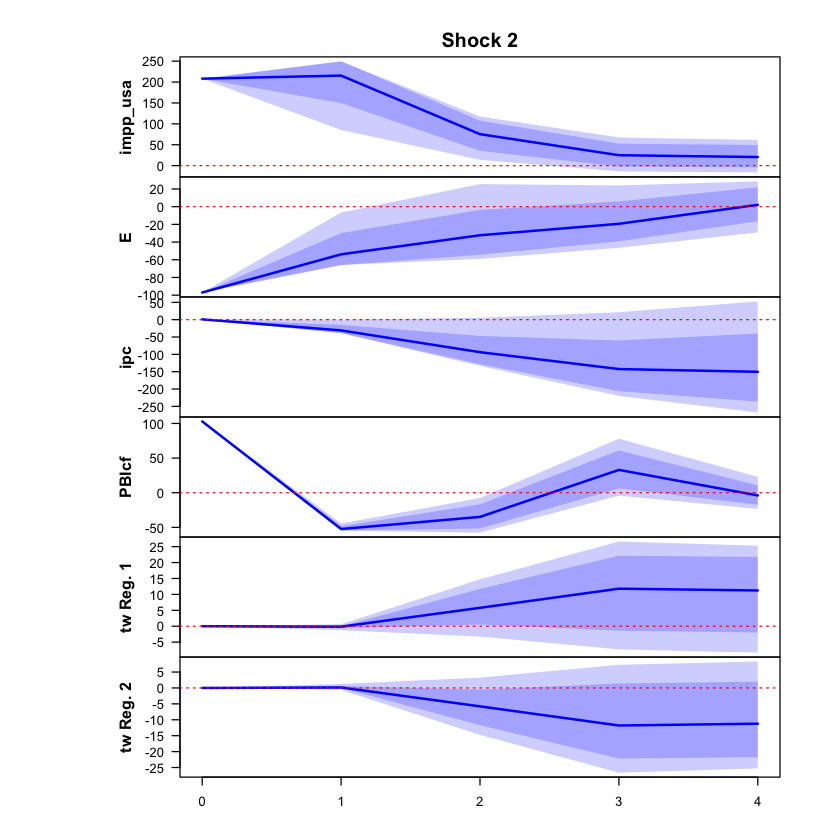

 >>> Linear IRF ( 1  shock units)


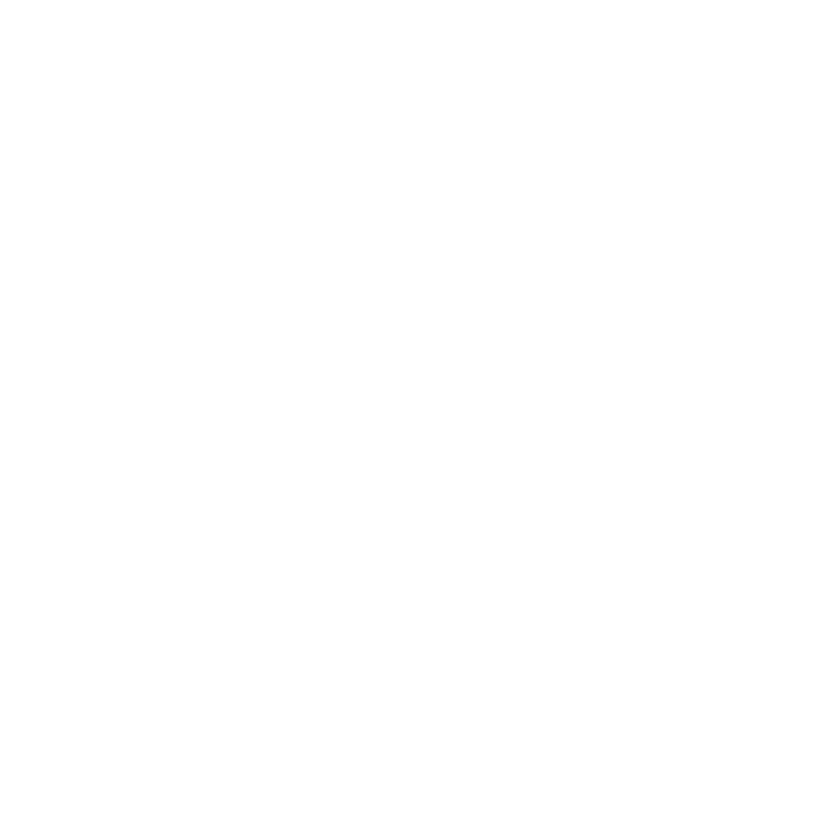

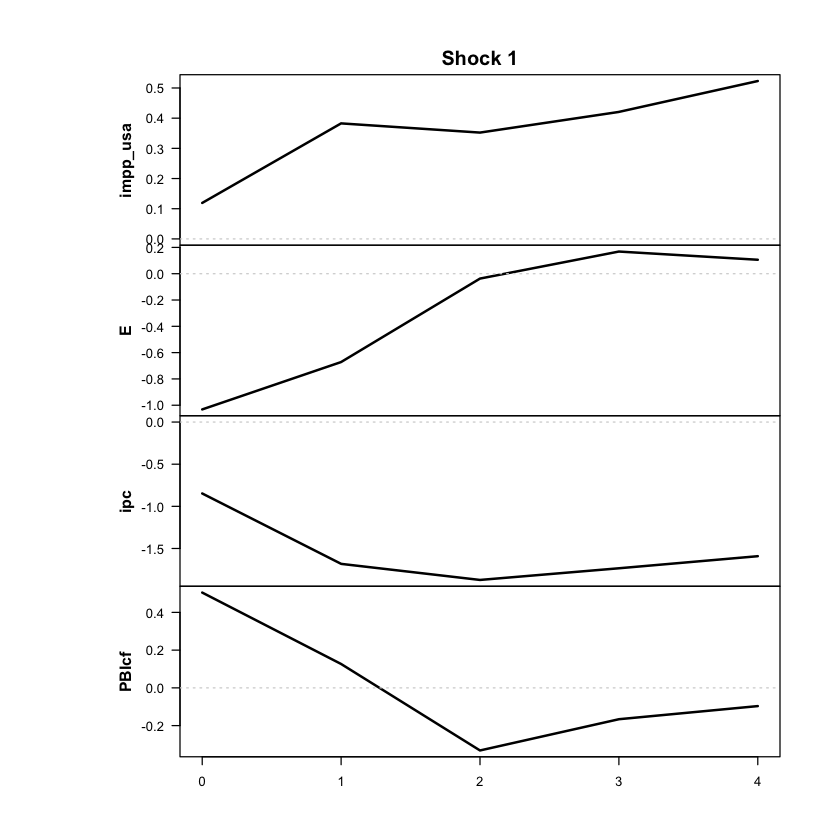

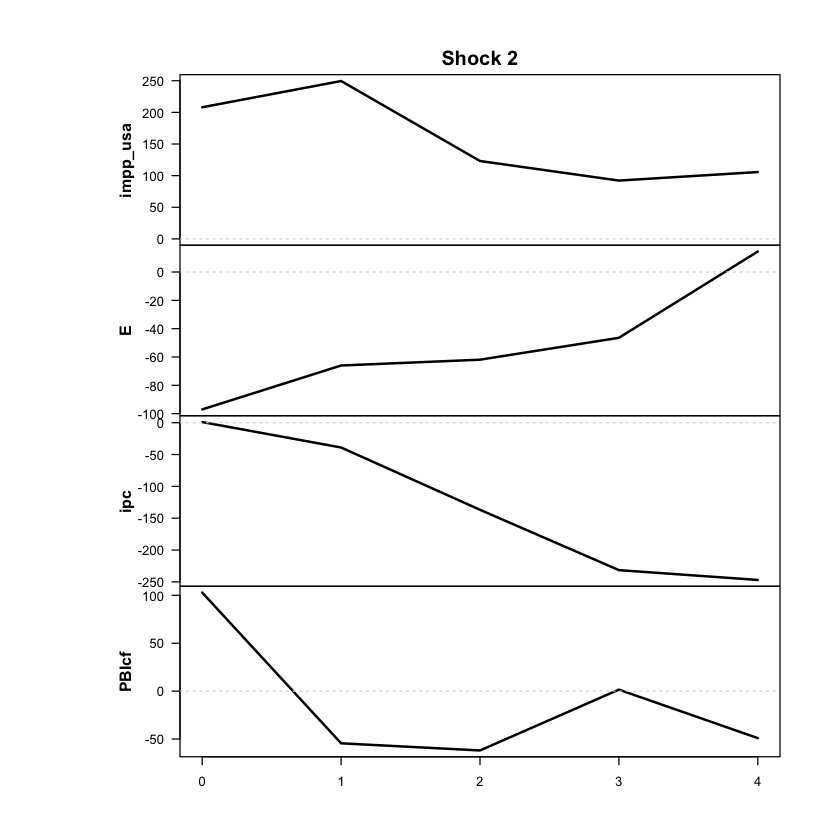

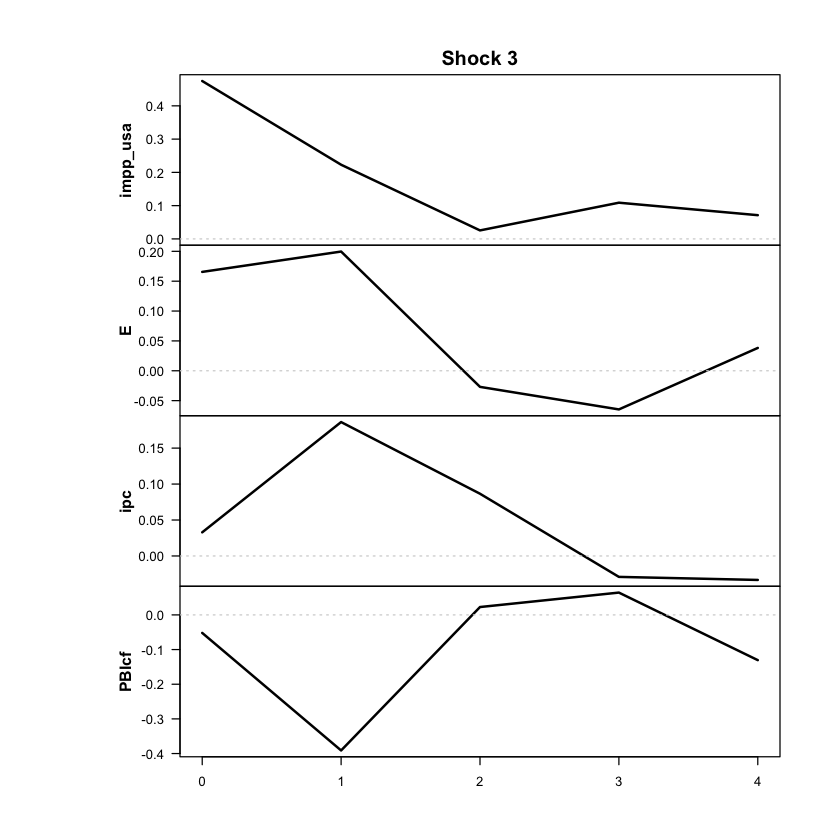

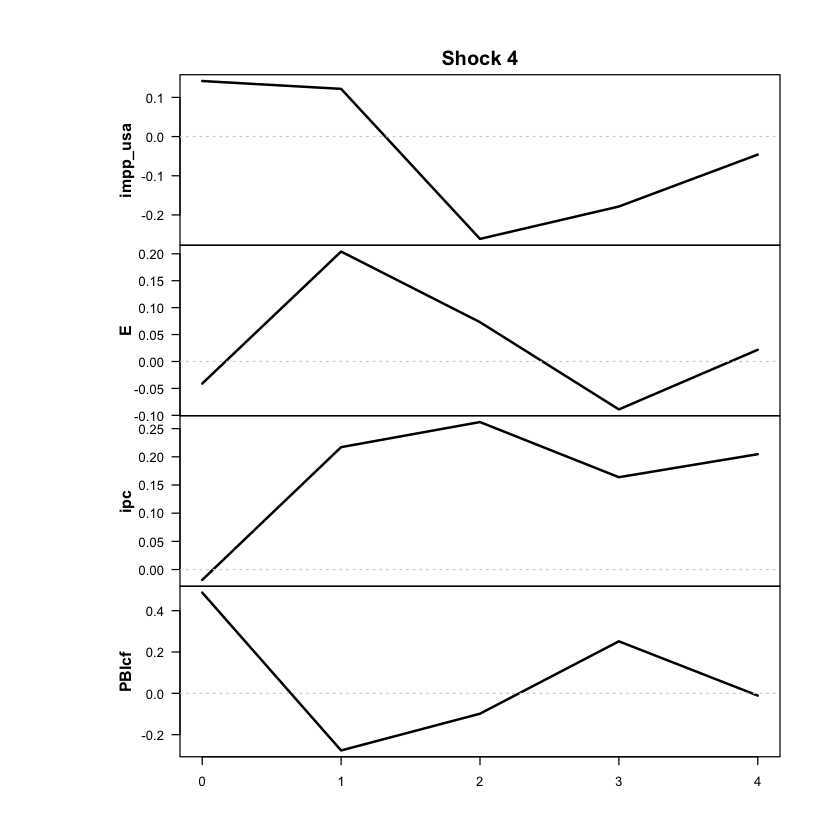

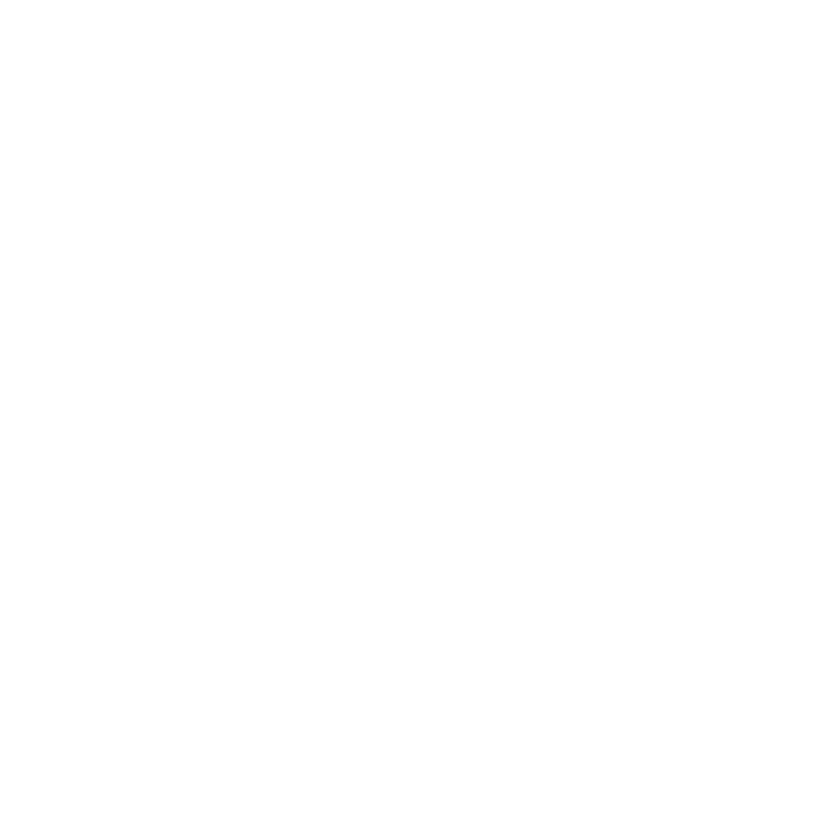

In [8]:
res <- run_threshold_tvar(
  data = df_anual_comb,
  endog = c("impp_usa","E","ipc","PBIcf"),
  periodicity = 'anual', # 'trimestral' o 'anual' o mensual
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIcf")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = TRUE   # primera corrida: estimar. Después de guardado, cambiar a TRUE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [53]:
ic_tvar_p2 <- criterios_info(res, "TVAR p=2")
print(ic_tvar_p2)

    modelo regimenes parametros loglik AIC    HQ   BIC
1 TVAR p=2         2         93   -215 616 707.9 844.3


In [54]:
resumen_modelo(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"))

Modelo: threshold | regímenes: 2 | rezagos: 2 | errores: Gaussian 
Umbrales: 58.3% anual 
Años por régimen (régimen de mayor peso): régimen 1 = 65 | régimen 2 = 21 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      2.65      6.59
E            20.19    192.45
ipc          21.04    231.80
PBIcf         2.82      1.52


In [55]:
identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "PBIcf"))
# Debe sugerir el shock 2 (= posición de E). Si sugiere otro, avisar antes de seguir.

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0021 -0.0363  0.0430  0.0205
  E        -0.1550  0.1423  0.1261 -0.0500
  ipc      -0.1236 -0.0014  0.0243 -0.0218
  PBIcf     0.0054 -0.0108 -0.0028  0.0425

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.72    0.39    0.33    0.08 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.797  -0.010   0.193   0.436 

>>> Shock sugerido como cambiario: 1 (confirmalo: debe mover mucho a E y poco a ipc )


In [56]:
print_passthrough(res, endog = c("impp_usa","E","ipc","PBIcf"))

+++++++++ RÉGIMEN  1 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0      -0.0100
1         1       0.0721
2         2       0.2184
3         3       0.1912
4         4      -0.1075

>>> IRF lineal normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
1         0      -0.0100
2         1      -0.1418
3         2      -0.4912
4         3      -0.8614
5         4      -1.1864

+++++++++ RÉGIMEN  2 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0      -0.0100
1         1       0.3113
2         2       0.9405
3         3       1.4234
4         4       1.5017

>>> IRF lineal normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
1         0      -0.0100
2         1       0.3901
3         2       1.3693
4         3       2.3181
5         4       2.4726



### ERPT y gráficos — TVAR p = 2

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 15.3%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   PBIcf
         0 -0.0100 -0.0760
         1  0.0810 -0.0421
         2  0.2519 -0.0202
         3  0.2482 -0.0258
         4 -0.0463 -0.0182

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   PBIcf
         0 -0.0100 -0.0760
         1  0.3112 -0.0373
         2  0.9434 -0.0116
         3  1.4296 -0.0353
         4  1.5050 -0.0321


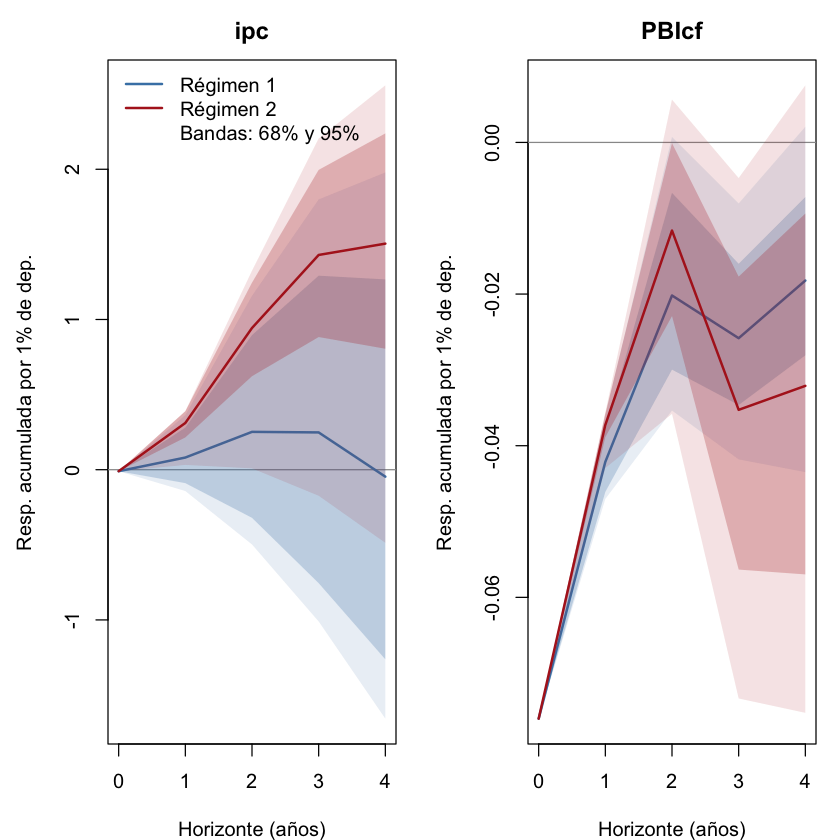


+++ Régimen 1 - IRF lineal acumulada por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   PBIcf
         0 -0.0100 -0.0760
         1 -0.1418 -0.0468
         2 -0.4912 -0.0269
         3 -0.8614 -0.0101
         4 -1.1864  0.0027

+++ Régimen 2 - IRF lineal acumulada por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   PBIcf
         0 -0.0100 -0.0760
         1  0.3901 -0.0358
         2  1.3693  0.0100
         3  2.3181  0.0088
         4  2.4726  0.0450


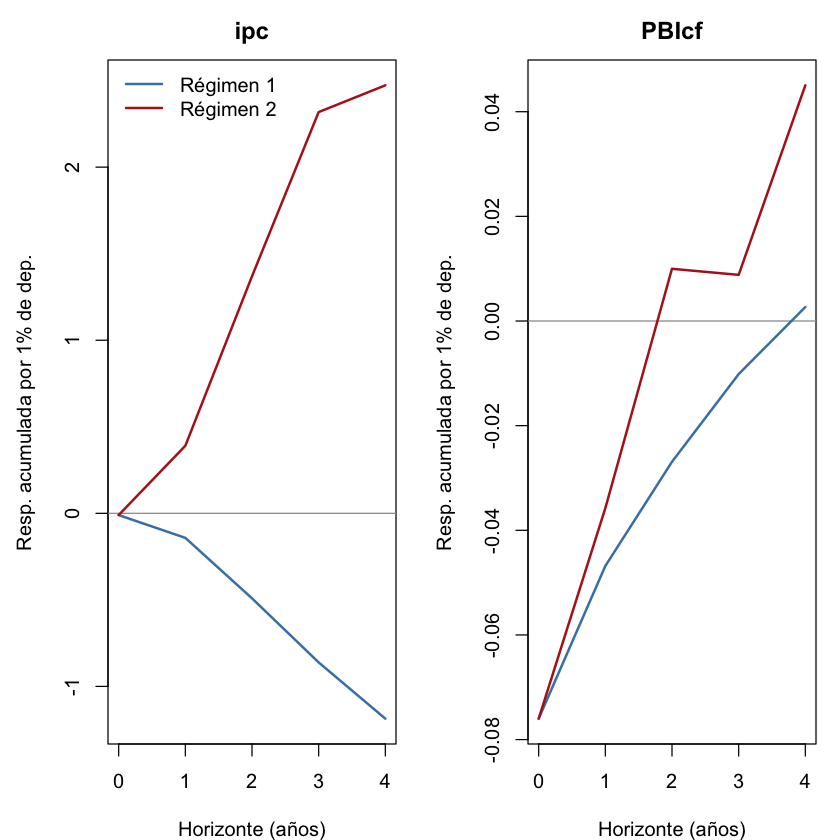

In [57]:
girf_impp_usa_tvar_p2 <- graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                        archivo = paste0(carpeta, "girf_original_impp_usa_tvar_p2_anual_comb"))
irf_impp_usa_tvar_p2  <- graficar_irf_original(res, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                       archivo = paste0(carpeta, "irf_original_impp_usa_tvar_p2_anual_comb"))

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 15.3%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte      E     ipc   PBIcf
         0 1.0000 -0.0100 -0.0760
         1 1.2048  0.0810 -0.0421
         2 1.1315  0.2519 -0.0202
         3 0.9935  0.2482 -0.0258
         4 0.7032 -0.0463 -0.0182

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte      E     ipc   PBIcf
         0 1.0000 -0.0100 -0.0760
         1 1.5573  0.3112 -0.0373
         2 1.8922  0.9434 -0.0116
         3 2.0885  1.4296 -0.0353
         4 2.0609  1.5050 -0.0321


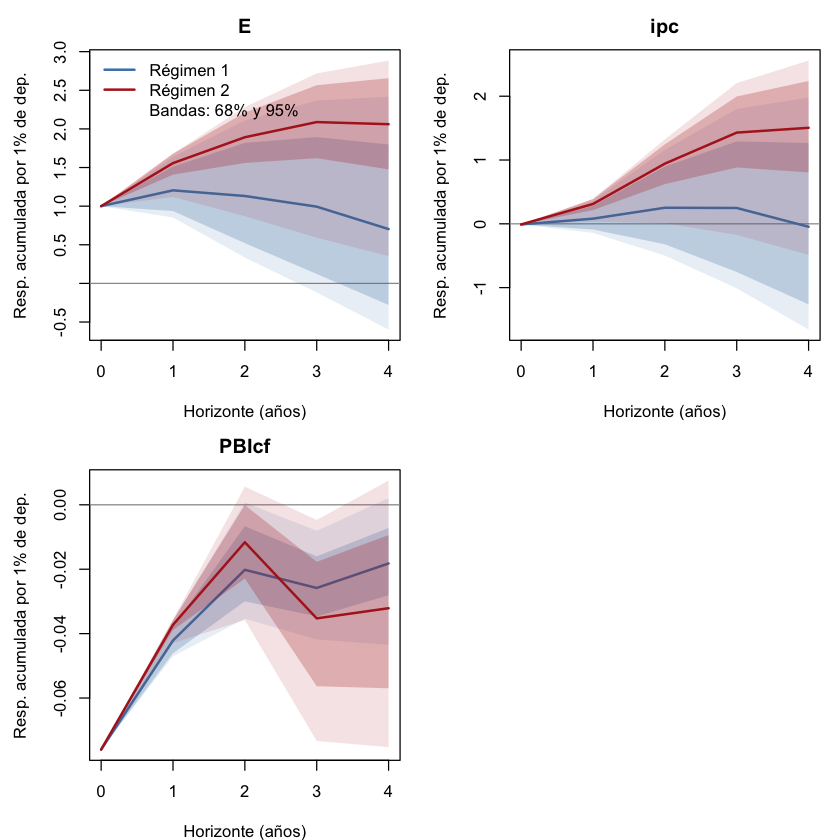

In [58]:
graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                       variables = c("E", "ipc", "PBIcf"),
                       archivo = paste0(carpeta, "girf_original_impp_usa_tvar_p2_con_E_anual_comb"))

In [9]:
out_impp_usa_tvar_p2 <- erpt_historia(res, data = df_anual_comb,
                             endog = c("impp_usa", "E", "ipc", "PBIcf"))


Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 15.3%.

Estimando 86 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 65 | régimen 2 = 21 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9714

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0           -0.0100           -0.0100
2         1           -0.1127            0.2795
3         2           -0.3948            0.8862
4         3           -0.8509            1.3923
5         4           -1.3649            1.4590

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0          -0.0100          -0.0100
2         1          -0.1400           0.3348
3         2          -0.4635           0.9590
4         3          -0.9450           1.5611
5         4          -1.4658           1.5947


In [10]:
out_impp_usa_tvar_p2_acum <- erpt_historia(res, data = df_anual_comb,
                                  endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                  definicion = "acumulado")


Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 15.3%.

Estimando 86 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 65 | régimen 2 = 21 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9714

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0           -0.0100           -0.0100
2         1           -0.1325            0.1785
3         2           -1.1420            0.4620
4         3           14.8470            0.6424
5         4            3.2677            0.6546

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0          -0.0100          -0.0100
2         1          -0.1635           0.2105
3         2          -1.2663           0.5073
4         3           9.9218           0.7244
5         4           3.3203           0.7874


HTML widgets cannot be represented in plain text (need html)

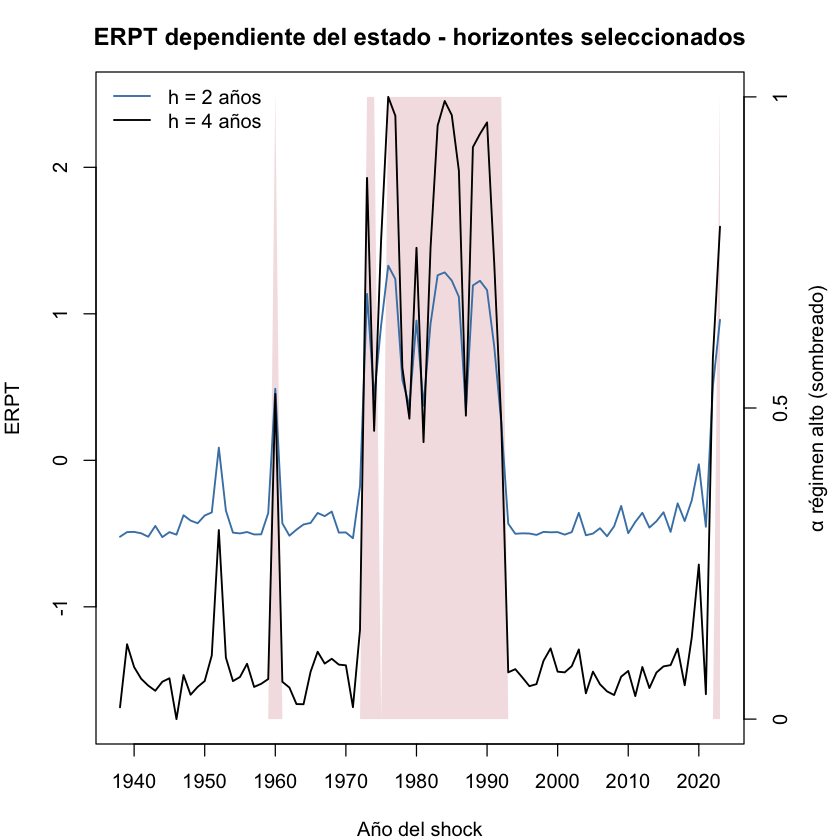

In [60]:
graficar_erpt(out_impp_usa_tvar_p2, archivo = paste0(carpeta, "erpt_impp_usa_tvar_p2_anual_comb"))

Promedio de ERPT por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_original reg_alto_original
         4             3.268             0.655


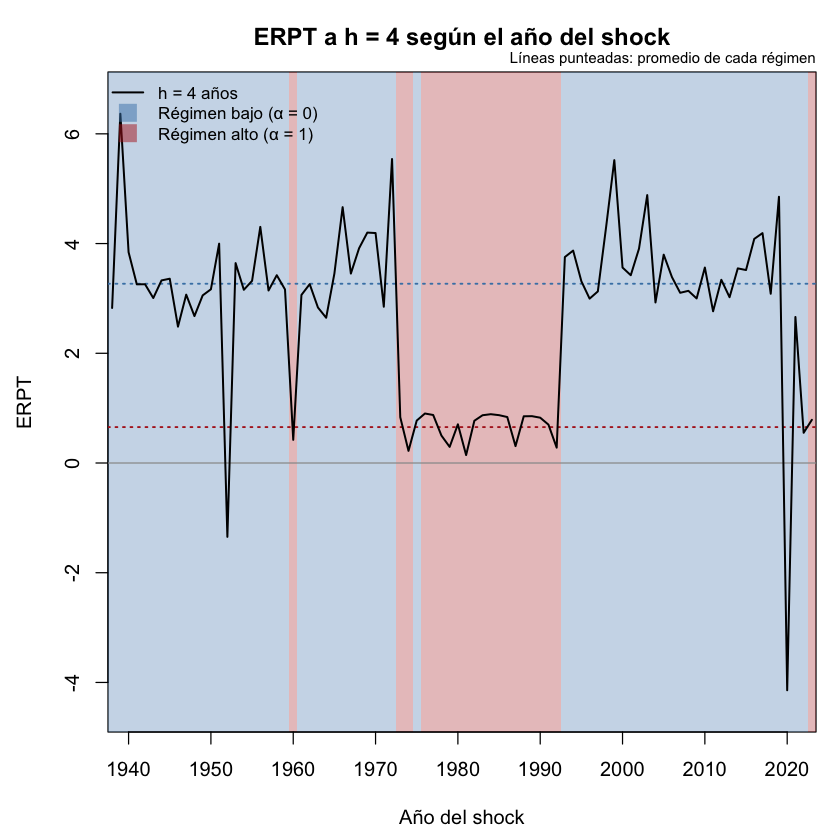

In [11]:
graficar_erpt_2d_bandas(out_impp_usa_tvar_p2_acum, horizontes = 4,
                        archivo = paste0(carpeta, "erpt_2d_bandas_impp_usa_tvar_p2_acum_anual_comb"))

HTML widgets cannot be represented in plain text (need html)

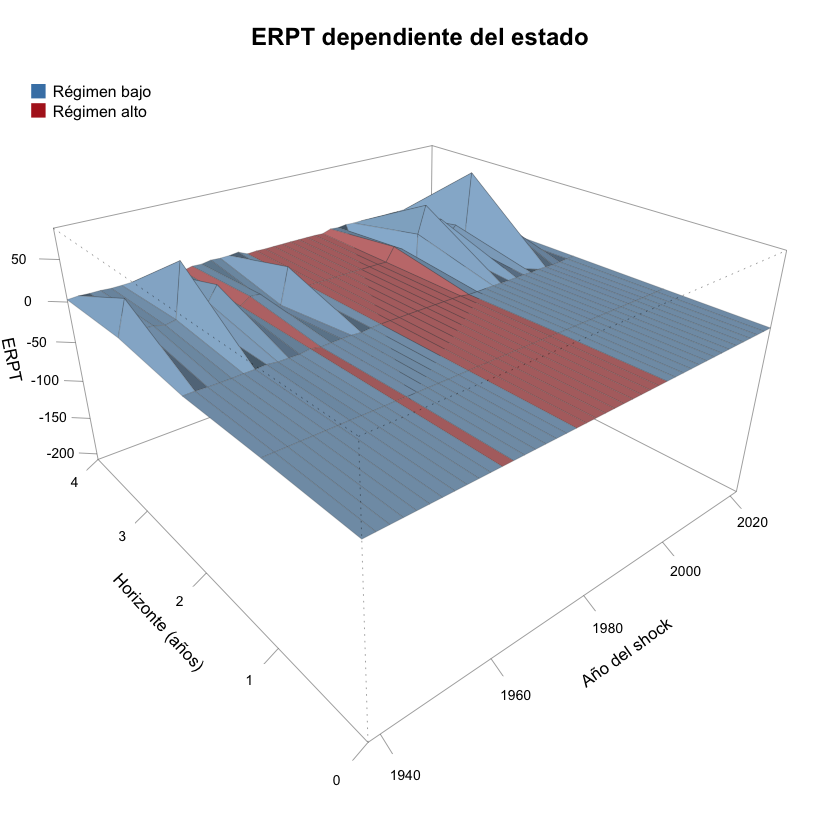

In [12]:
graficar_erpt_manta(out_impp_usa_tvar_p2_acum, cada = 2,
                    archivo = paste0(carpeta, "erpt_manta_impp_usa_tvar_p2_acum_c2_anual_comb"))


In [63]:
graficar_slider(out_impp_usa_tvar_p2, archivo = paste0(carpeta, "slider_impp_usa_tvar_p2_anual_comb"))

HTML widgets cannot be represented in plain text (need html)

 horizonte    1975    1989    2005
         0 -0.0100 -0.0100 -0.0100
         1  0.2551  0.3816 -0.1414
         2  0.9252  1.2253 -0.5000
         3  1.5083  1.9879 -0.9699
         4  1.5122  2.2280 -1.4424


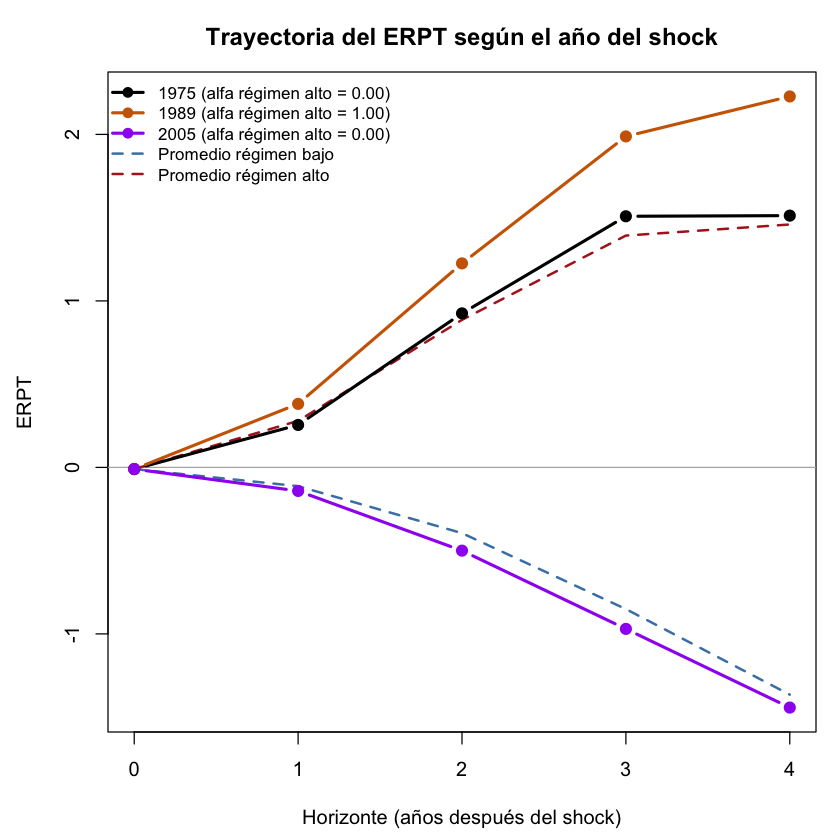

In [64]:
graficar_trayectorias(out_impp_usa_tvar_p2,
                      trimestres = c(1975, 1989, 2005),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p2_1975_1989_2005_anual_comb"))


In [65]:
guardar_gif(out_impp_usa_tvar_p2, archivo = paste0(carpeta, "gif_impp_usa_tvar_p2_anual_comb"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_impp_usa_tvar_p2_anual_comb.gif



HTML widgets cannot be represented in plain text (need html)

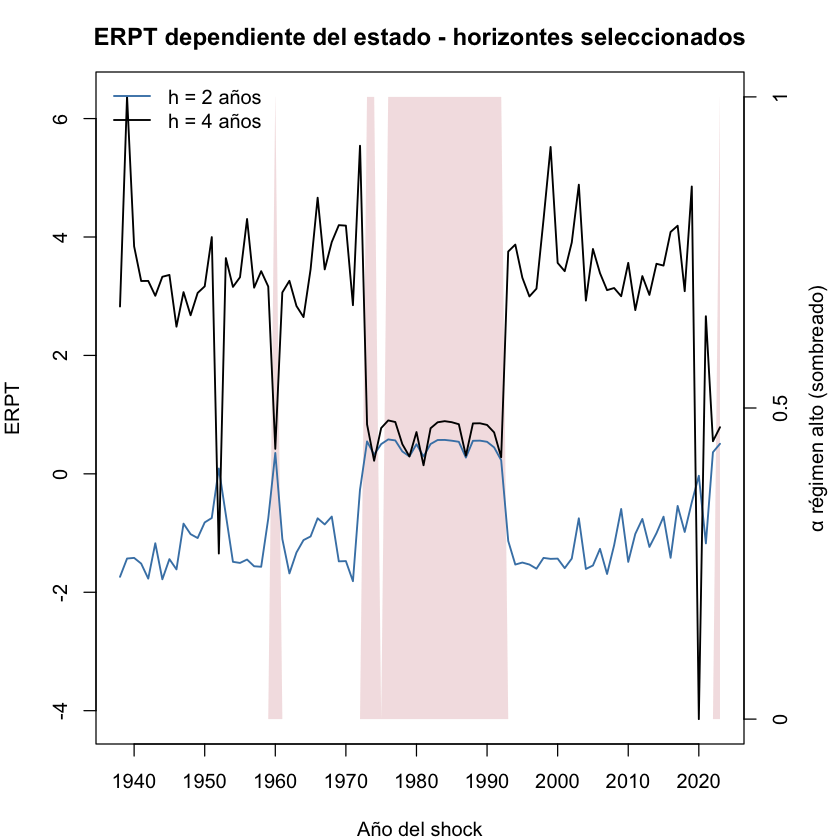

In [67]:
graficar_erpt(out_impp_usa_tvar_p2_acum, archivo = paste0(carpeta, "erpt_impp_usa_tvar_p2_acum_anual_comb"))

In [68]:
graficar_slider(out_impp_usa_tvar_p2_acum, archivo = paste0(carpeta, "slider_impp_usa_tvar_p2_acum_anual_comb"))

HTML widgets cannot be represented in plain text (need html)

 horizonte    1975    1976    1989
         0 -0.0100 -0.0100 -0.0100
         1  0.1736  0.2304  0.2289
         2  0.5023  0.5814  0.5606
         3  0.7177  0.8127  0.7745
         4  0.7734  0.9022  0.8537


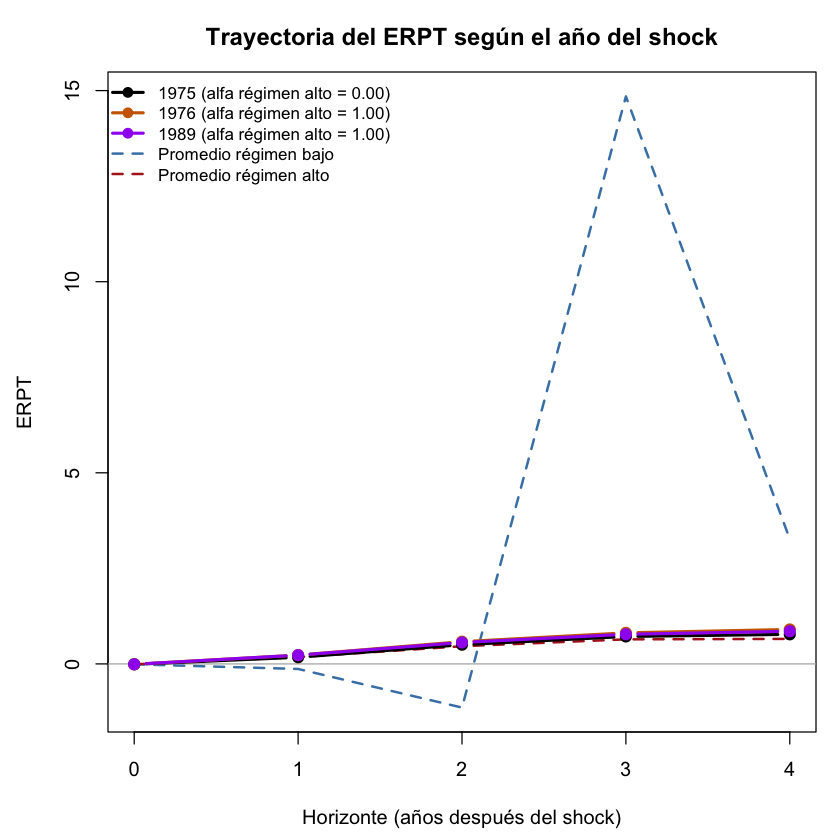

In [69]:
graficar_trayectorias(out_impp_usa_tvar_p2_acum,
                      trimestres = c(1975, 1976, 1989),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p2_acum_1975_1976_1989_anual_comb"))


In [70]:
guardar_gif(out_impp_usa_tvar_p2_acum, archivo = paste0(carpeta, "gif_impp_usa_tvar_p2_acum_anual_comb"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_impp_usa_tvar_p2_acum_anual_comb.gif



  horizonte reg_bajo_original reg_alto_original
1         0           -0.0100           -0.0100
2         1           -0.1027            0.2895
3         2           -0.2821            0.6067
4         3           -0.4561            0.5061
5         4           -0.5140            0.0667


HTML widgets cannot be represented in plain text (need html)

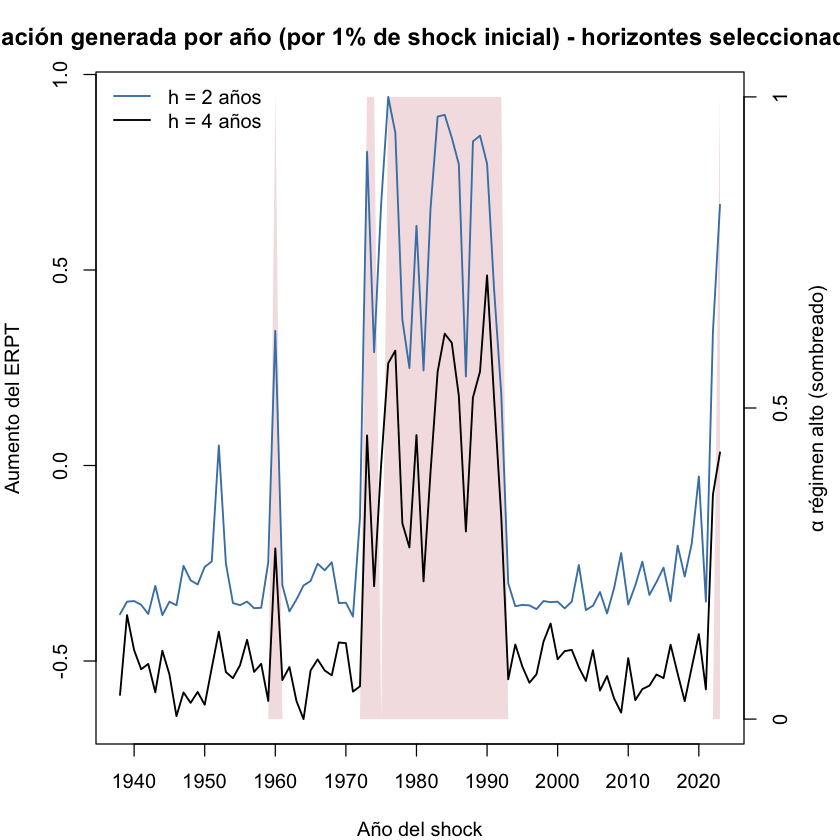

In [71]:
inc_impp_usa_tvar_p2 <- erpt_incremental(out_impp_usa_tvar_p2)
graficar_erpt(inc_impp_usa_tvar_p2, archivo = paste0(carpeta, "erpt_impp_usa_tvar_p2_incremental_anual_comb"),
              titulo = "Inflación generada por año (por 1% de shock inicial)",
              eje_z = "Aumento del ERPT")


  horizonte reg_bajo_original reg_alto_original
1         0           -0.0100           -0.0100
2         1           -0.1224            0.1886
3         2           -1.0096            0.2835
4         3           15.9891            0.1804
5         4          -11.5794            0.0122


HTML widgets cannot be represented in plain text (need html)

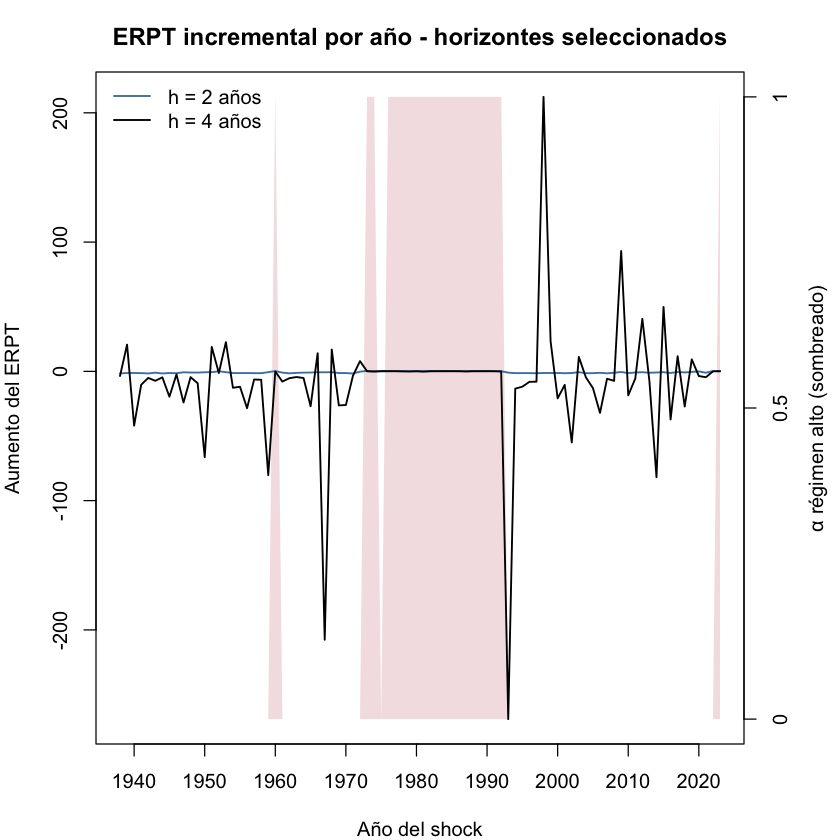

In [72]:
inc_impp_usa_tvar_p2_acum <- erpt_incremental(out_impp_usa_tvar_p2_acum)
graficar_erpt(inc_impp_usa_tvar_p2_acum, archivo = paste0(carpeta, "erpt_impp_usa_tvar_p2_acum_incremental_anual_comb"),
              titulo = "ERPT incremental por año", eje_z = "Aumento del ERPT")

Umbrales (inflación anual de t-1): 58.3% anual 
Años por régimen: régimen 1 = 65 | régimen 2 = 21 


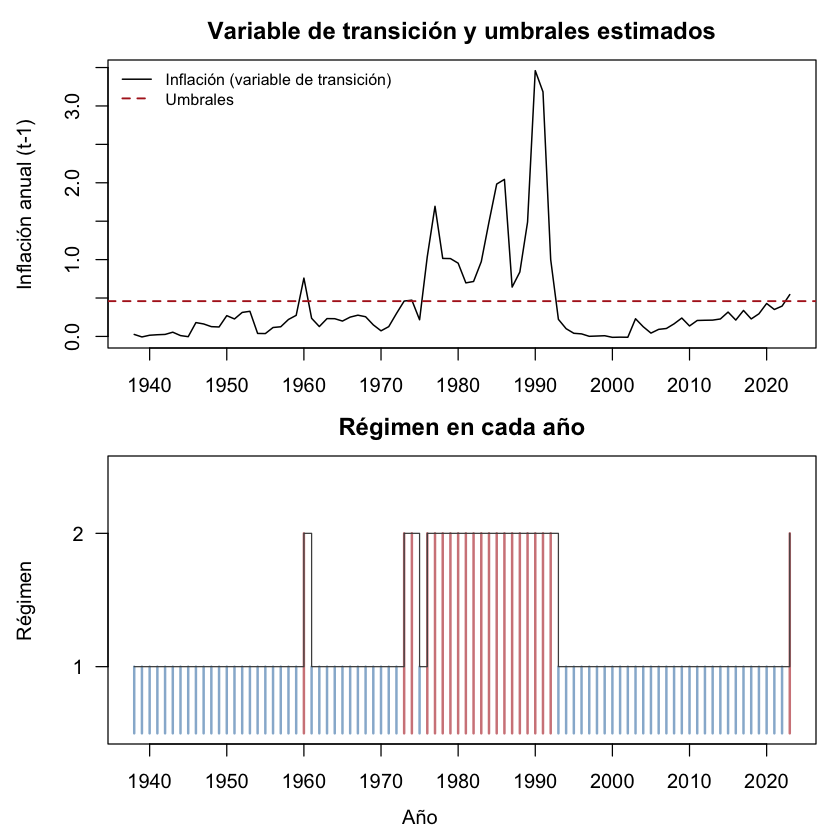

In [73]:
graficar_transicion(res, data = df_anual_comb,
                    endog = c("impp_usa", "E", "ipc", "PBIcf"),
                    archivo = paste0(carpeta, "transicion_impp_usa_tvar_p2_anual_comb"))


In [75]:
e <- out_impp_usa_tvar_p2_acum$erpt
o <- order(abs(e), decreasing = TRUE)[1:5]
data.frame(año = colnames(e)[col(e)[o]], horizonte = row(e)[o] - 1, erpt = round(e[o], 1))

año,horizonte,erpt
<chr>,<dbl>,<dbl>
1993,3,272.8
1967,3,211.1
1998,3,-208.0
2009,3,-90.1
2014,3,85.4


In [ ]:
g_t_p2_acum <- acotar_para_graficar(out_impp_usa_tvar_p2_acum)
graficar_slider(g_t_p2_acum, archivo = paste0(carpeta, "slider_impp_usa_tvar_p2_acum_acotado_anual_comb"))

In [77]:
round(out_impp_usa_tvar_p2_acum$erpt[1:2, c("1975", "1976", "1989")], 3)   # h = 0 y h = 1

,1975,1976,1989
0,-0.010,-0.01,-0.010
1,0.174,0.23,0.229


In [78]:
o <- graficos_con_mediana(out_impp_usa_tvar_p2_acum)
bajo <- .normalizar_out(o)$regimen == 1
round(quantile(o$erpt["3", bajo], c(0.05, 0.25, 0.5, 0.75, 0.95)), 2)

Gráficos con la MEDIANA por régimen como referencia.


5%    25%    50%    75%    95% 
-33.63   0.54   9.92  22.96  80.65

In [79]:
pers <- out_impp_usa_tvar_p2$erpt / out_impp_usa_tvar_p2_acum$erpt
bajo <- .normalizar_out(out_impp_usa_tvar_p2)$regimen == 1
round(apply(pers[, bajo], 1, median), 2)   # mediana del régimen bajo, h = 0 a 4

0     1     2     3     4 
 1.00  0.86  0.37 -0.03 -0.44

### Gráficos adicionales — TVAR p = 2

Según el criterio de esta notebook (la principal se elige por el Portmanteau del TVAR), p = 2 es la principal: con p = 1 el Portmanteau rechaza (0,013 y 0,004) y con p = 2 no (0,082 y 0,274). Estos son los gráficos que tenía p = 1 y le faltaban a p = 2.

**Antes de correrlos:** revisar la identificación. `identificar_shock_cambiario` sugiere el shock 1 y se usó el 2, y el ERPT del régimen bajo da negativo y creciente en valor absoluto (−1,36 a h = 4 en el promedio). Consultarlo con el director.

In [ ]:
# Mismo juego de gráficos que la especificación principal (TVAR p = 1), para comparar
guardar_gif_erpt_h(out_impp_usa_tvar_p2_acum, h = 4,
                   archivo = paste0(carpeta, "gif_erpt_h4_impp_usa_tvar_p2_acum_anual_comb"))
guardar_gif_erpt_h(out_impp_usa_tvar_p2_acum, h = 4, marcas = c(1975, 1989, 2002, 2018),
                   archivo = paste0(carpeta, "gif_erpt_h4_marcas_impp_usa_tvar_p2_acum_anual_comb"))
for (a in list(1973:1976, 1987:1990, 1989:1992, 2001:2004, 2016:2019, c(1950, 1983, 1988, 2002))) {
  graficar_trayectorias(out_impp_usa_tvar_p2_acum, trimestres = a,
                        archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p2_acum_",
                                         paste(a, collapse = "_"), "_anual_comb"))
}

In [ ]:
for (m in c("construir", "rotar")) {
  guardar_gif_manta(out_impp_usa_tvar_p2_acum, modo = m,
                    archivo = paste0(carpeta, "gif_manta_", m, "_impp_usa_tvar_p2_acum_anual_comb"))
  guardar_gif_manta(out_impp_usa_tvar_p2_acum, modo = m, marcas = c(1975, 1989, 2002, 2018),
                    archivo = paste0(carpeta, "gif_manta_", m, "_marcas_impp_usa_tvar_p2_acum_anual_comb"))
}
guardar_gif(out_impp_usa_tvar_p2_acum, archivo = paste0(carpeta, "gif_impp_usa_tvar_p2_acum_lento_anual_comb"),
            segundos_por_cuadro = 0.5, cada = 2)

## Comparación de criterios

In [82]:
rbind(ic_tvar_p1, ic_tvar_p2)

modelo,regimenes,parametros,loglik,AIC,HQ,BIC
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
TVAR p=1,2,61,-233.71,589.4,650.0,739.8
TVAR p=2,2,93,-215.00,616.0,707.9,844.3


## Errores t de Student (2 regímenes)

Misma especificación, pero con errores t de Student (`cond_dist = "Student"`): colas más pesadas, que admiten trimestres extremos sin necesitar un régimen aparte. Objetivo: (1) ver si el VLSTAR encuentra una solución válida (sin covarianza casi singular) y (2) verificar que el ERPT del TVAR principal no cambia. Los modelos gaussianos ya guardados no se pisan: los archivos t llevan `student_` en el nombre.

`resumen_modelo` muestra los grados de libertad: valores bajos (≈ 3–6) indican colas muy pesadas; valores muy altos (> 30) indican que los errores son casi normales.

### TVAR con errores t, p = 1

Se cargó exitosamente modelos preguardados  threshold_tvar_student_1_2_500_52169eadae81cf13df43a1d2afde97f4.rds  de la carpeta models

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , 4 , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


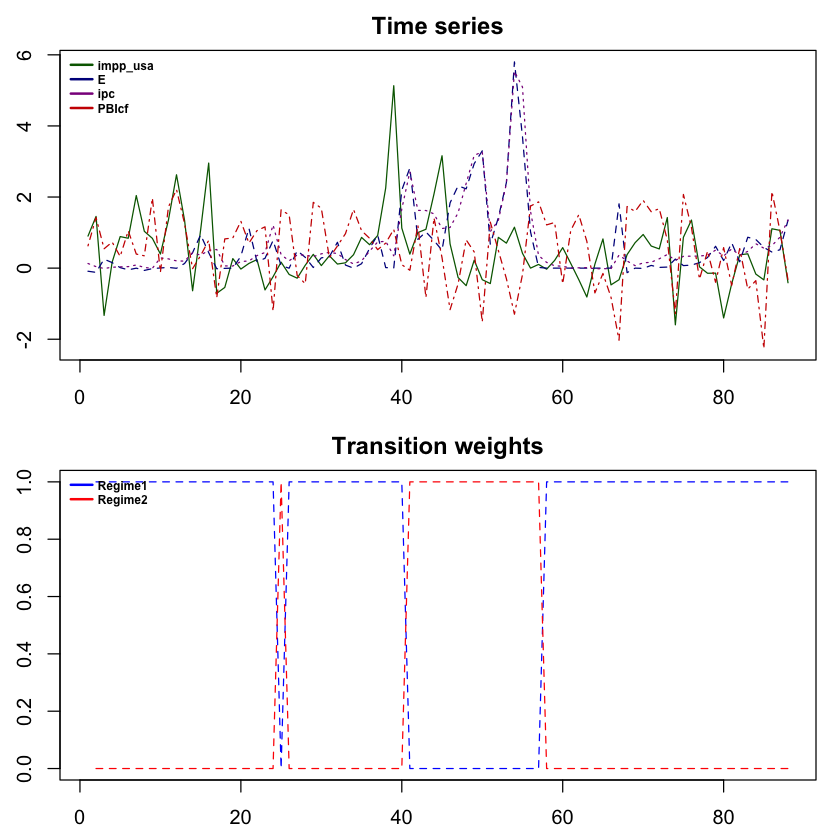

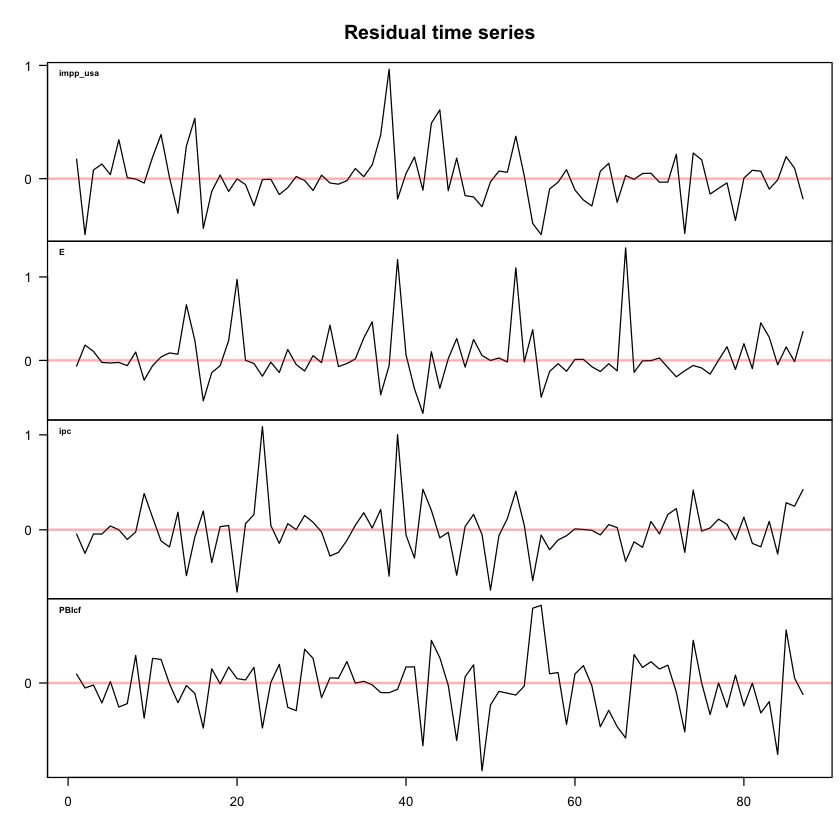

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



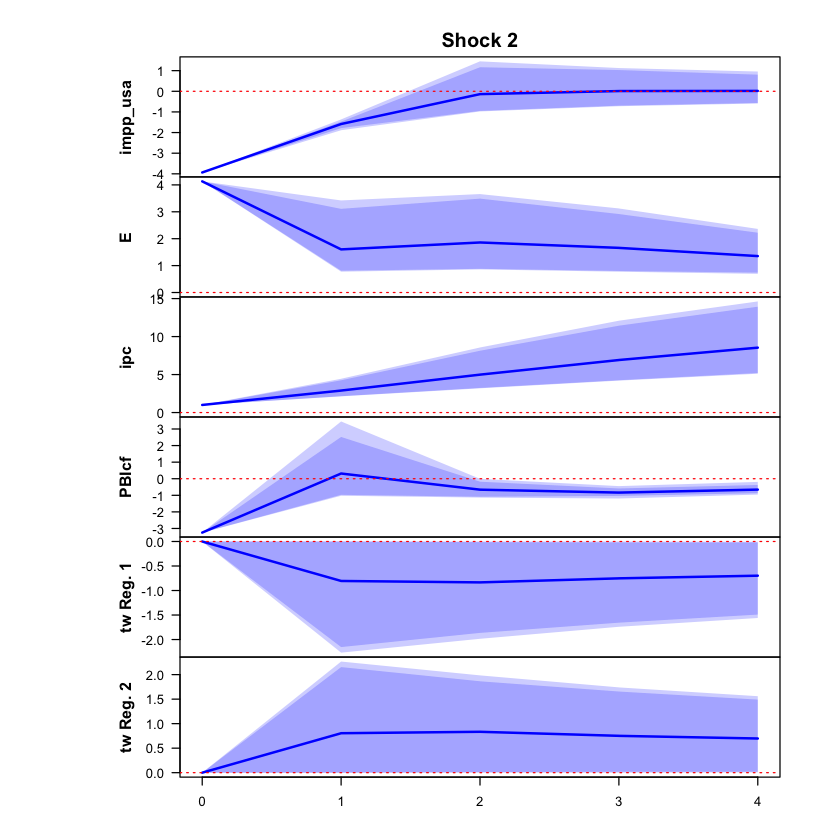

 >>> Linear IRF ( 1  shock units)


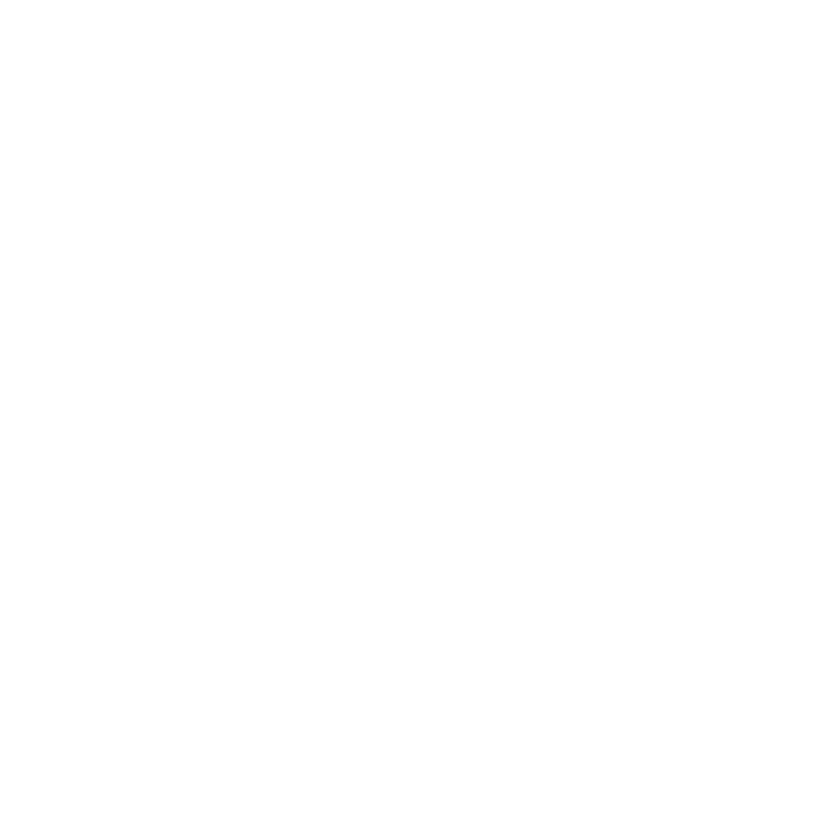

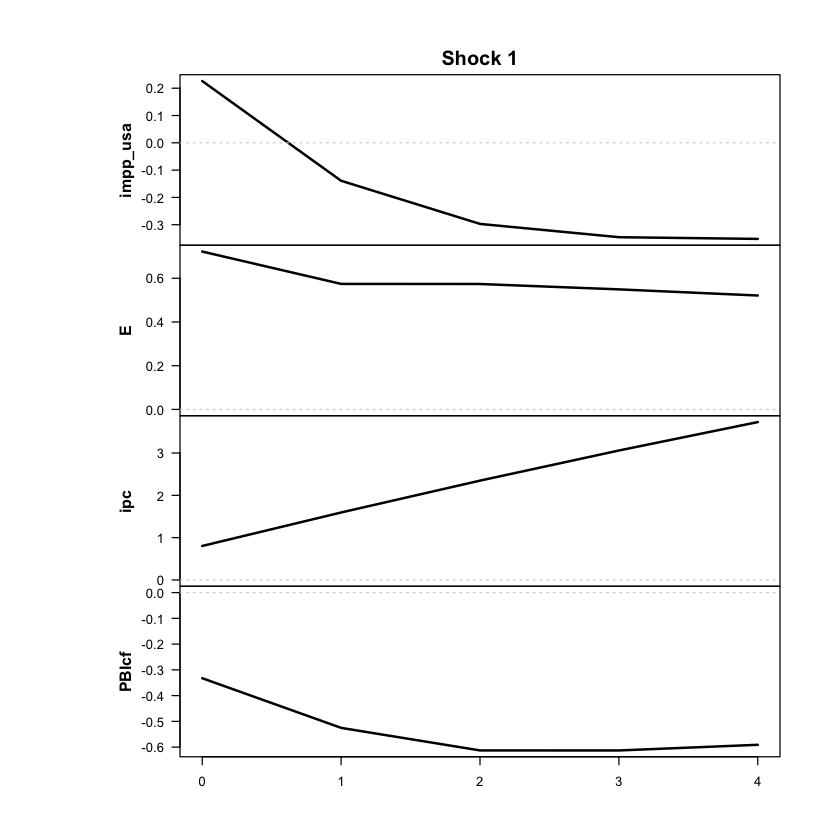

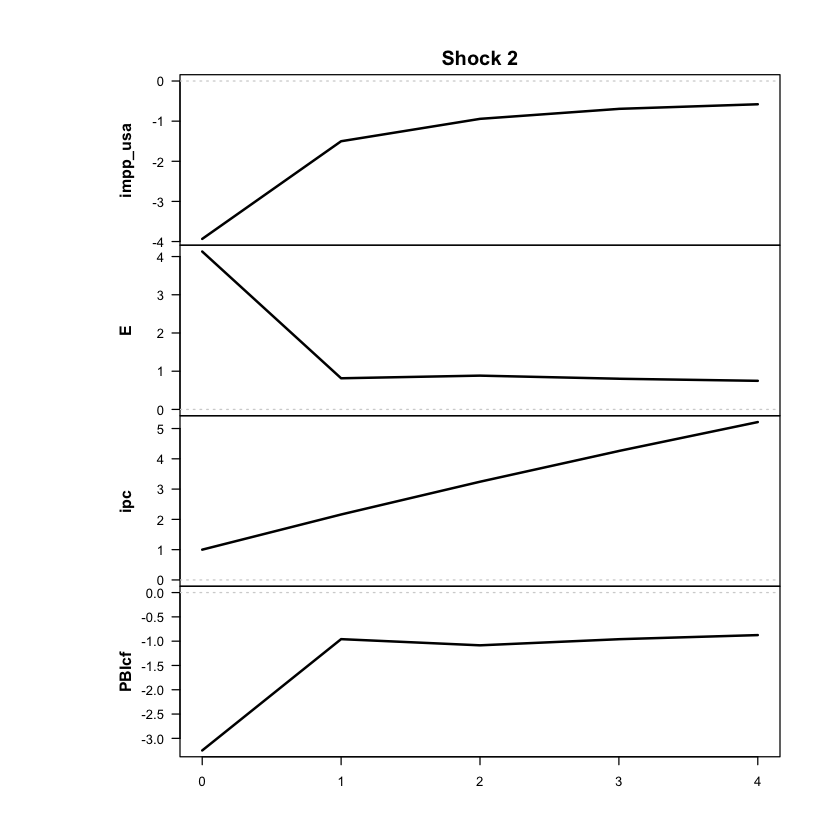

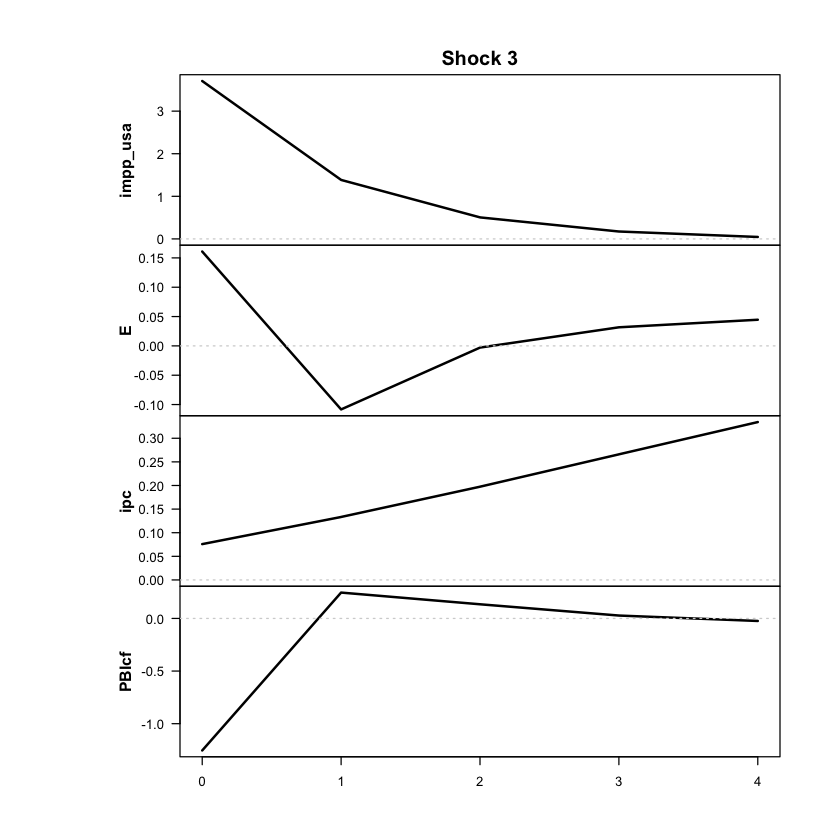

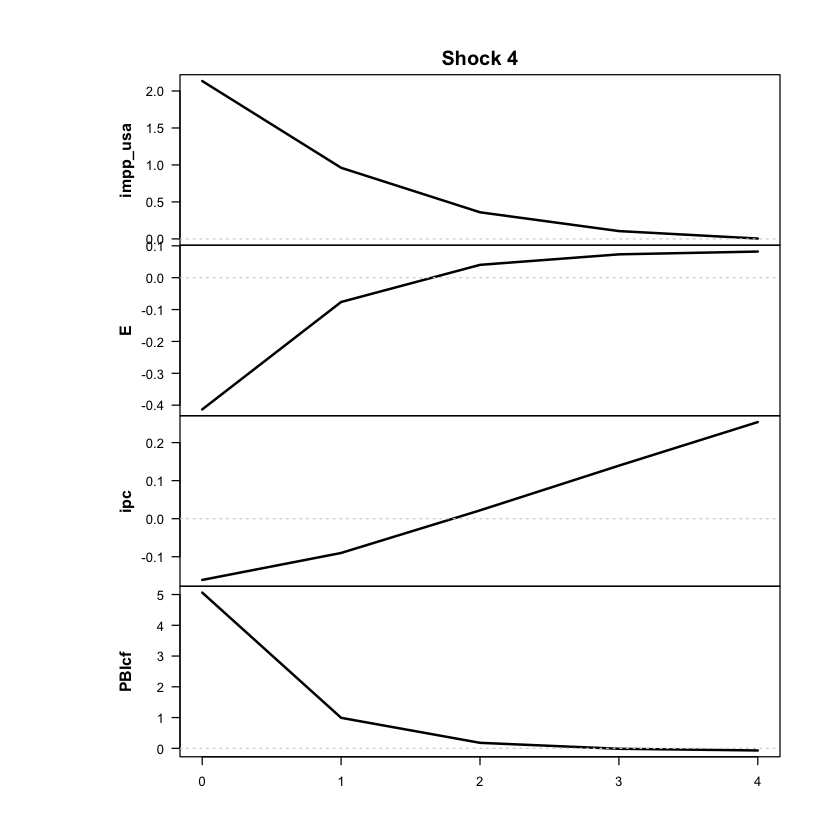

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



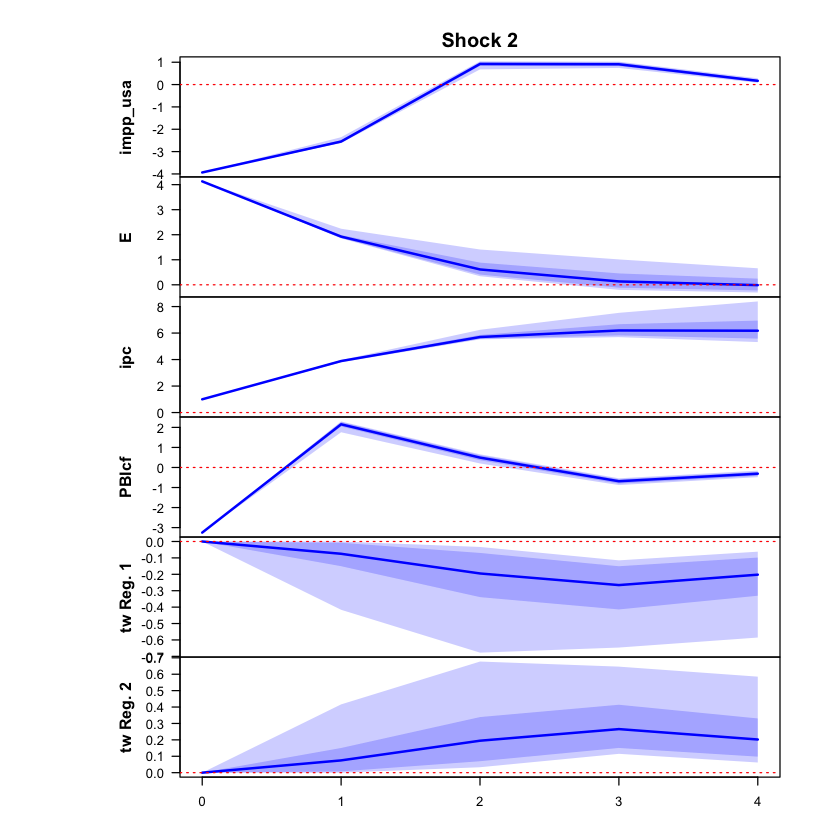

 >>> Linear IRF ( 1  shock units)


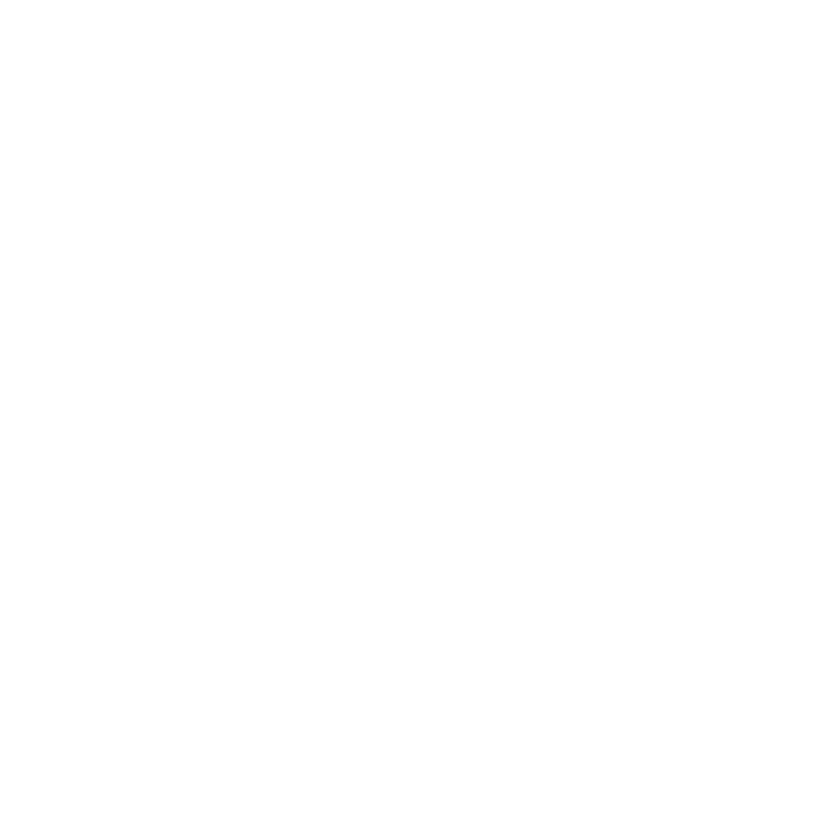

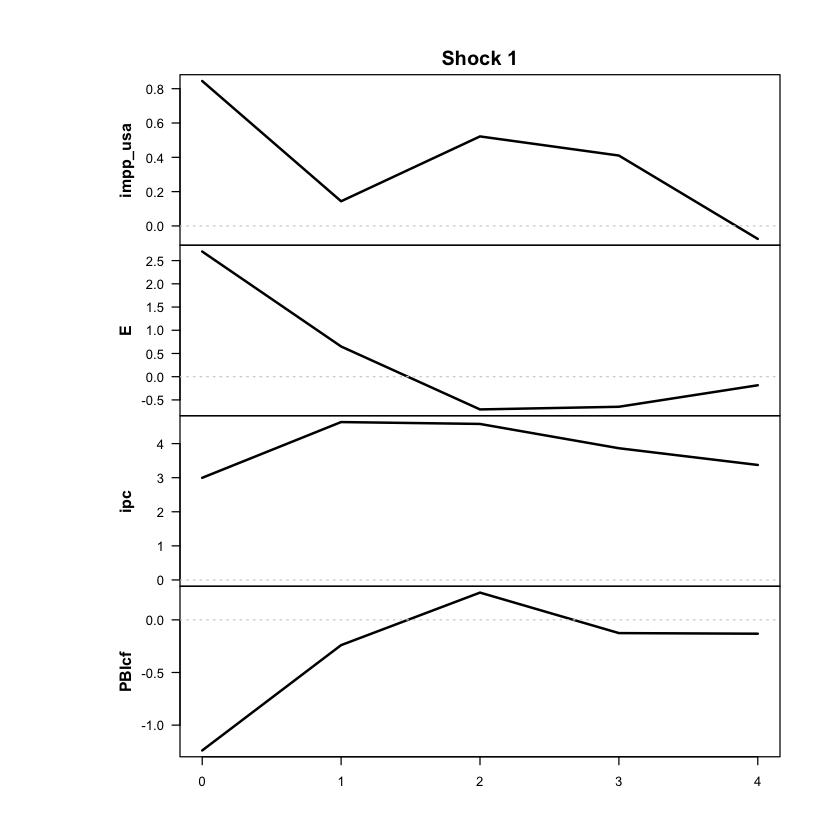

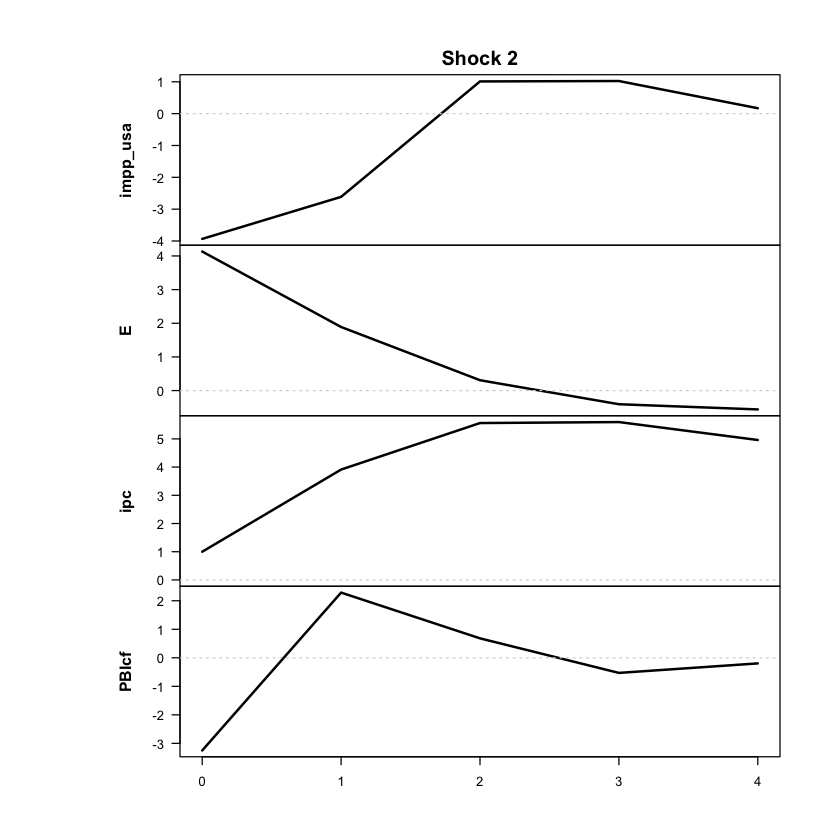

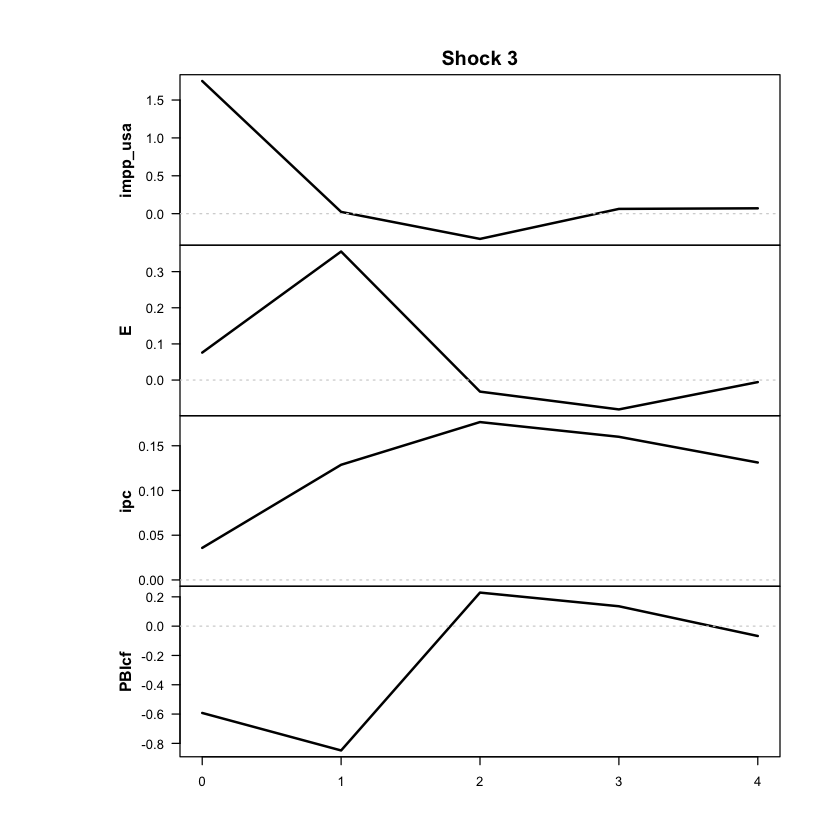

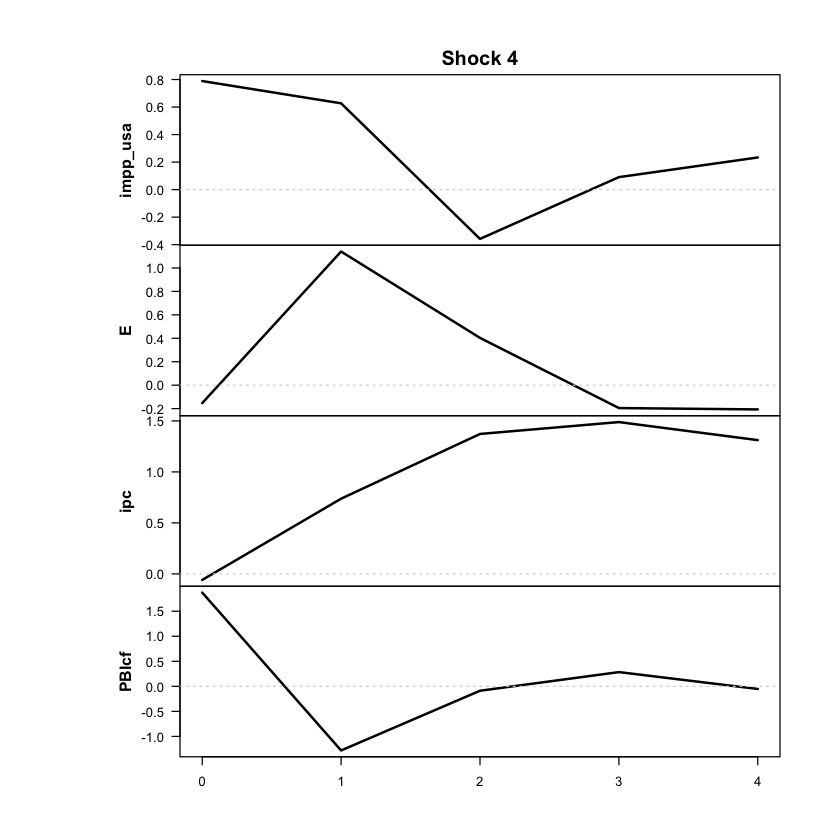

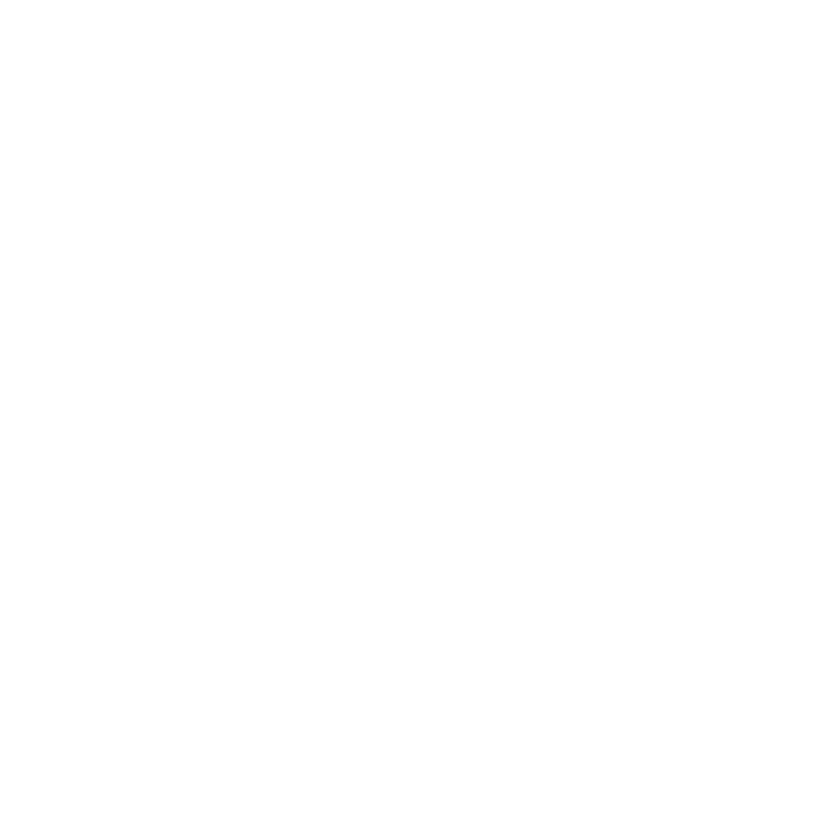

In [22]:
res <- run_threshold_tvar(
  data = df_anual_comb,
  endog = c("impp_usa","E","ipc","PBIcf"),
  periodicity = 'anual', # 'trimestral' o 'anual' o mensual
  feature_lag = 1,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIcf")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = TRUE,
  cond_dist = "Student"   # errores t de Student
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [23]:
c(tipo = res$tvar_model$model$weight_function, p = res$tvar_model$model$p,
  errores = res$tvar_model$model$cond_dist)

tipo           p     errores 
"threshold"         "1"   "Student"

In [24]:
ic_tvar_t_p1 <- criterios_info(res, "TVAR-t p=1")
print(ic_tvar_t_p1)
saveRDS(ic_tvar_t_p1, "ic_tvar_t_p1_anual_comb.rds")

      modelo regimenes parametros  loglik   AIC    HQ BIC
1 TVAR-t p=1         2         62 -203.05 530.1 591.7 683


In [85]:
resumen_modelo(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"))

Modelo: threshold | regímenes: 2 | rezagos: 1 | errores: Student 
Grados de libertad de la t de Student: 2.04 
Umbrales: 85.7% anual 
Años por régimen (régimen de mayor peso): régimen 1 = 69 | régimen 2 = 18 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      3.46      4.58
E            20.30    233.14
ipc          22.45    272.06
PBIcf         2.85      1.40


In [86]:
explorar_optimos(res, n = 10)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -203.05            85.7    NA        2.0            69/18
             2 -203.05            79.8    NA        2.0            69/18
             3 -203.05            74.3    NA        2.0            69/18
             4 -203.05              80    NA        2.0            69/18
             5 -203.05            78.2    NA        2.0            69/18
             6 -203.06            76.9    NA        2.1            69/18
             7 -203.06            79.3    NA        2.1            69/18
             8 -203.06            79.7    NA        2.1            69/18
             9 -203

In [87]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

threshold Student STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 1, M = 2, d = 4, #parameters = 62, #observations = 87 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Degrees of freedom: 2.04 (for all regimes) 
Upper threshold: 0.99 
Regime means: 0.36, 0.32, 0.44, 0.67

   Y      phi0          A1                              Omega                  
1 y1 = [  0.33 ] + [  0.38  0.11 -0.37  0.03 ] y1.1 + [ 19.77 -1.62 -0.24  7.26
2 y2   [ -0.01 ]   [ -0.04  0.00  0.73  0.02 ] y2.1   [ -1.62  2.29  1.04 -3.77
3 y3   [ -0.03 ]   [  0.01  0.11  0.91  0.05 ] y3.1   [ -0.24  1.04  0.77 -1.48
4 y4   [  0.84 ]   [  0.12  0.18 -0.79  0.13 ] y4.1   [  7.26 -3.77 -1.48 28.30
    1/2     
1 ]     eps1
2 ]     eps2
3 ]     eps3
4 ]     eps4

Regime 2 
Regime means: 0.62, 1.91, 2.13, 0.23

   Y     phi0          A1                              Omega                  
1 y1 = [ 0.21 ] + [  0.11 -0.44  0.52  0.27 ] y1.1 + [  8.45 -1.96  1.52  2.73
2 y2   [ 0.85 ]   

In [ ]:
shock_tvar_t_p1 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "PBIcf"))
# La función sugiere el shock 1, pero ese shock mueve más al ipc que a E (ERPT de impacto 1,08):
# no es el cambiario. El shock 2 sí cumple el chequeo (E 0,81; ipc 0,19; ERPT de impacto 0,235).
shock_tvar_t_p1 <- 2
shock_tvar_t_p1

In [ ]:
# res todavía es el TVAR-t (celda del modelo). Si no, volver a correr esa celda (load_presaved = TRUE).
girf_impp_usa_tvar_t_p1 <- graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                                  archivo = paste0(carpeta, "girf_original_impp_usa_tvar_t_p1_anual_comb"))
irf_impp_usa_tvar_t_p1  <- graficar_irf_original(res, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                                 archivo = paste0(carpeta, "irf_original_impp_usa_tvar_t_p1_anual_comb"))

### ERPT — TVAR t, p = 1

Correr solo si el modelo pasó el diagnóstico.

In [ ]:
out_impp_usa_tvar_t_p1 <- erpt_historia(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"), shock_num = shock_tvar_t_p1)

In [ ]:
out_impp_usa_tvar_t_p1_acum <- erpt_historia(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"), shock_num = shock_tvar_t_p1,
                      definicion = "acumulado")

In [ ]:
   out_impp_usa_tvar_t_p1_acum_s456 <- erpt_historia(res, data = df_anual_comb,
                                                     endog = c("impp_usa", "E", "ipc", "PBIcf"),
                                                     shock_num = shock_tvar_t_p1,
                                                     definicion = "acumulado", semilla = 456)

Umbrales (inflación anual de t-1): 85.7% anual 
Años por régimen: régimen 1 = 69 | régimen 2 = 18 


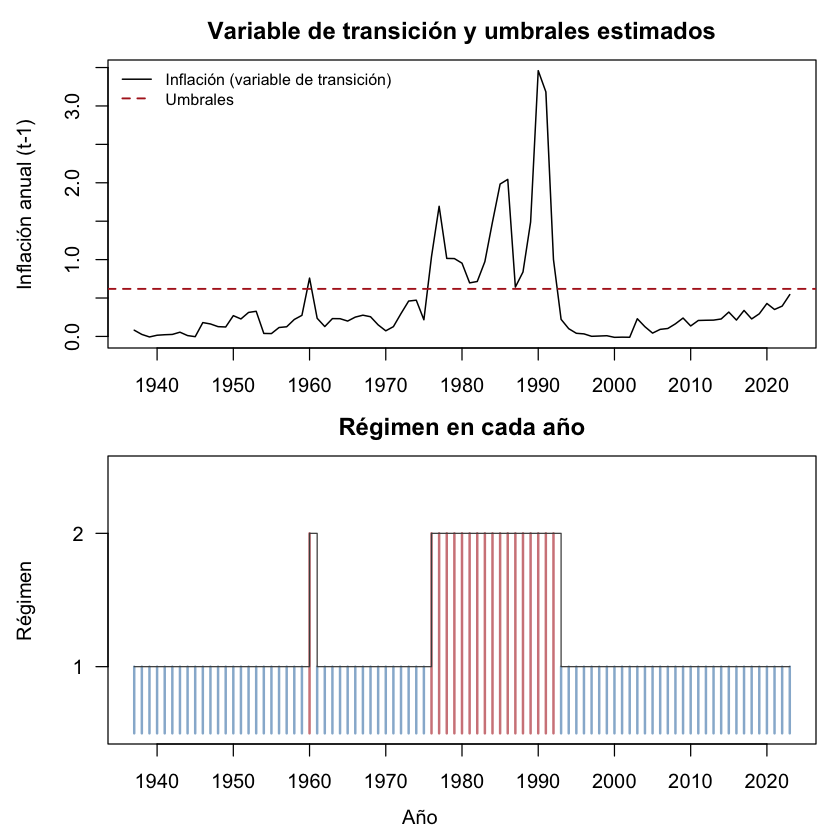

In [92]:
graficar_transicion(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                    archivo = paste0(carpeta, "transicion_impp_usa_tvar_t_p1_anual_comb"))

### Gráficos — TVAR t, p = 1 (robustez)

Modelo que pasa el diagnóstico de convergencia y tiene los mejores criterios de información, pero el Portmanteau rechaza (0,004 y 0,034) y los grados de libertad son 2,04: queda como robustez.

In [ ]:
graficar_erpt(out_impp_usa_tvar_t_p1_acum, archivo = paste0(carpeta, "erpt_impp_usa_tvar_t_p1_acum_anual_comb"))

In [ ]:
graficar_erpt_manta(out_impp_usa_tvar_t_p1_acum, cada = 2,
                    archivo = paste0(carpeta, "erpt_manta_impp_usa_tvar_t_p1_acum_c2_anual_comb"))

In [ ]:
# Mismo juego de gráficos que la especificación principal (TVAR p = 1), para comparar
graficar_erpt_2d_bandas(out_impp_usa_tvar_t_p1_acum, horizontes = 4,
                        archivo = paste0(carpeta, "erpt_2d_bandas_impp_usa_tvar_t_p1_acum_anual_comb"))
guardar_gif_erpt_h(out_impp_usa_tvar_t_p1_acum, h = 4,
                   archivo = paste0(carpeta, "gif_erpt_h4_impp_usa_tvar_t_p1_acum_anual_comb"))
guardar_gif_erpt_h(out_impp_usa_tvar_t_p1_acum, h = 4, marcas = c(1975, 1989, 2002, 2018),
                   archivo = paste0(carpeta, "gif_erpt_h4_marcas_impp_usa_tvar_t_p1_acum_anual_comb"))
for (a in list(1973:1976, 1987:1990, 1989:1992, 2001:2004, 2016:2019, c(1950, 1983, 1988, 2002))) {
  graficar_trayectorias(out_impp_usa_tvar_t_p1_acum, trimestres = a,
                        archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_t_p1_acum_",
                                         paste(a, collapse = "_"), "_anual_comb"))
}

### VLSTAR con errores t, p = 1

Nota de la versión trimestral: el VLSTAR-t con p = 3 dio muy mal resultado. En la anual, el equivalente es p = 2 (abajo); correrlo solo si el de p = 1 converge bien.


Desvíos usados para escalar:
  impp_usa          E        ipc      PBIcf 
0.07653640 0.64353427 0.62510191 0.04611195 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -305.647

The largest loglik: -217.925

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -303.672

The largest loglik: -191.393

Filtering inappropriate estimates...

Filtered through 73 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Warning message in warn_eigens(ret, allow_unstab = allow_unstab):
“Regime 1 has near-unit-roots! Consider building a model from the next-largest local maximum with the function 'alt_stvar' by adjusting its argument 'which_largest' (or use the function 'filter_estimates').”
Finished!




========= Unstructured fitted model ==========


Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


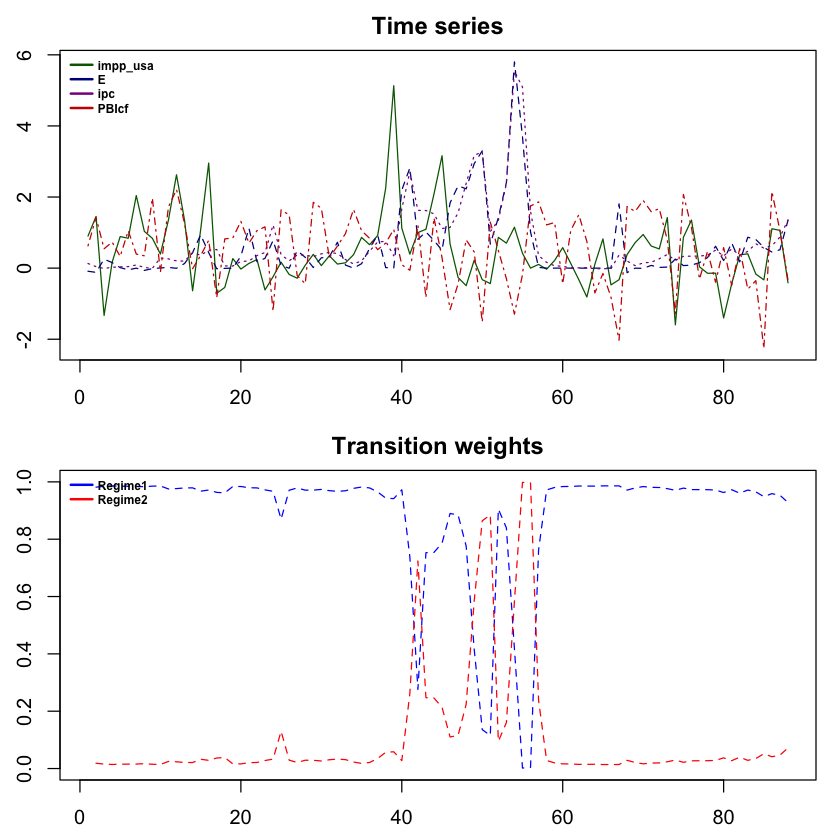

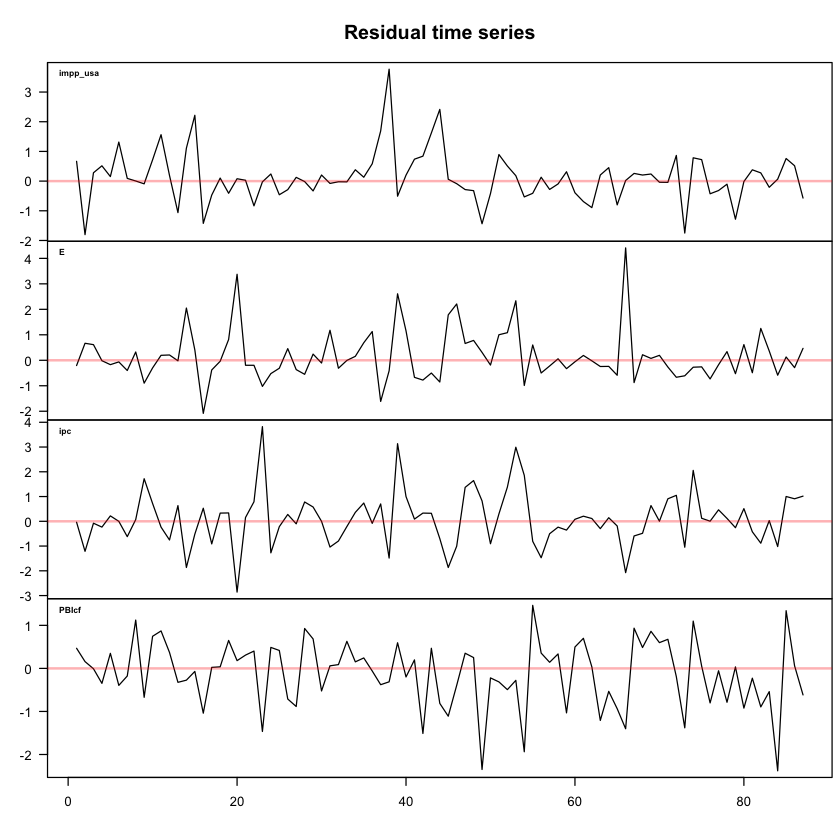

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



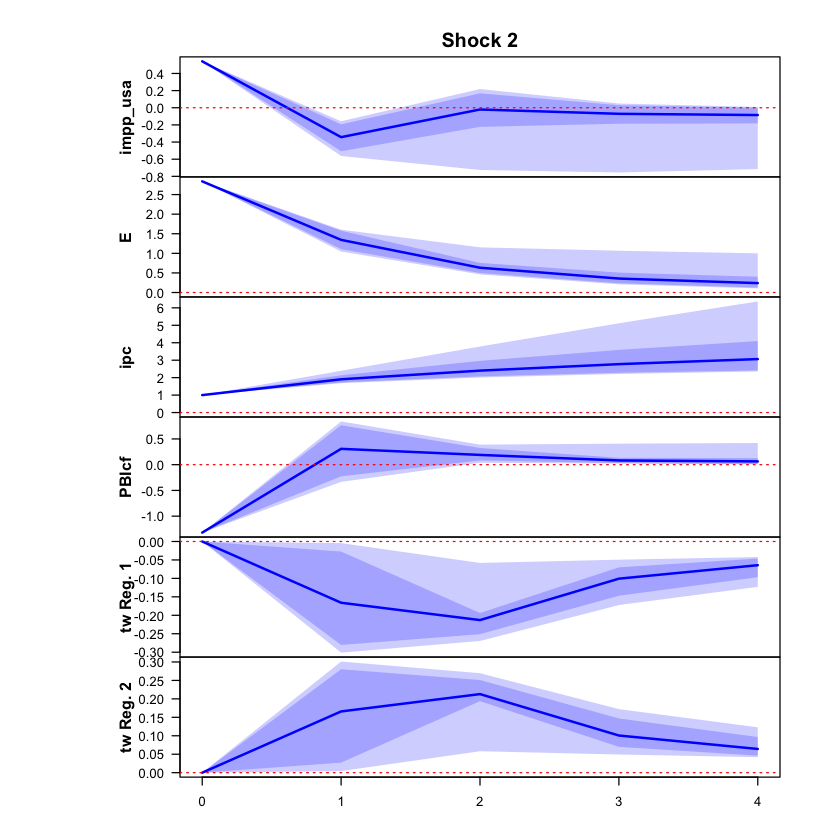

 >>> Linear IRF ( 1  shock units)


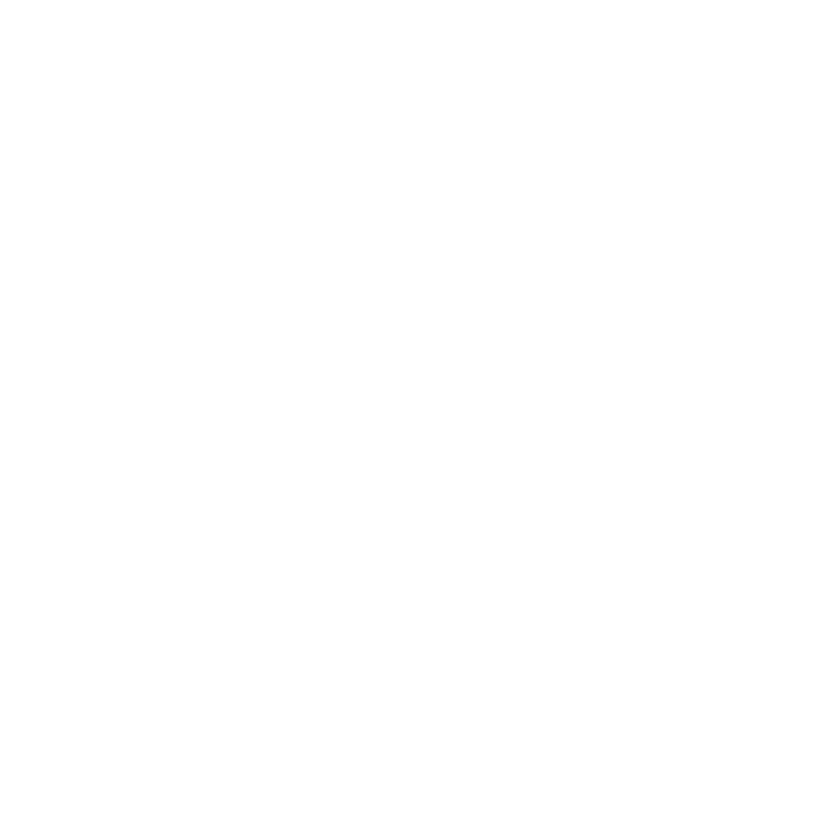

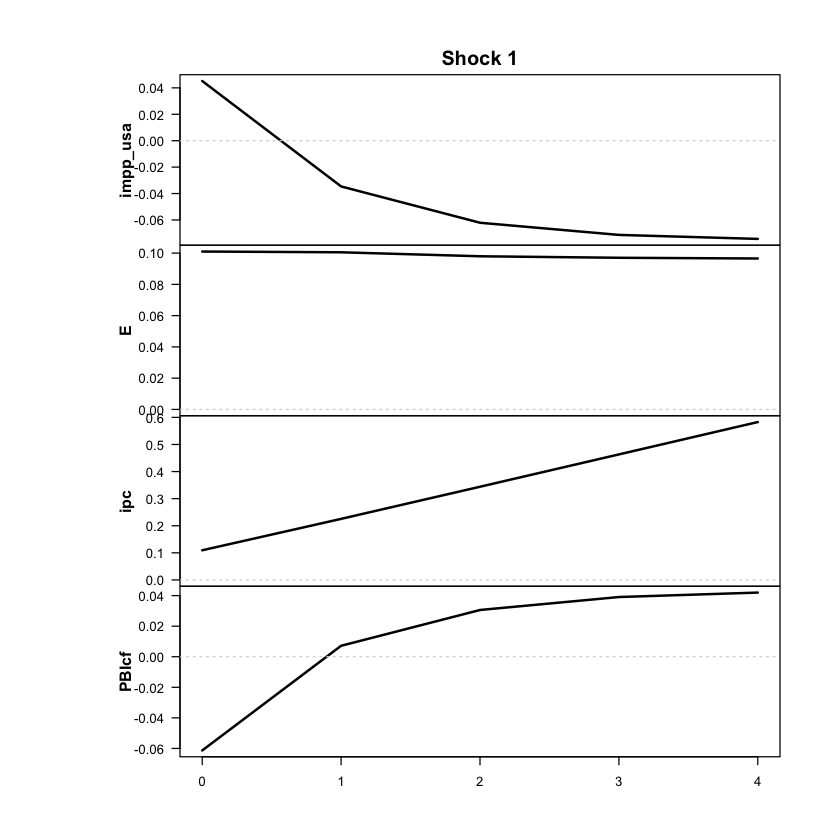

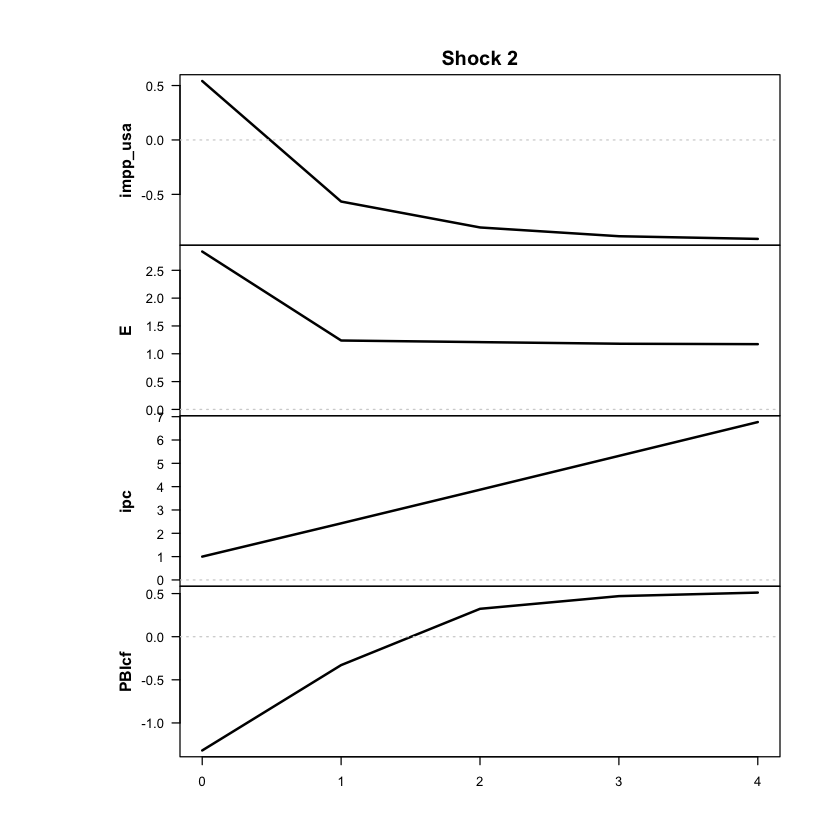

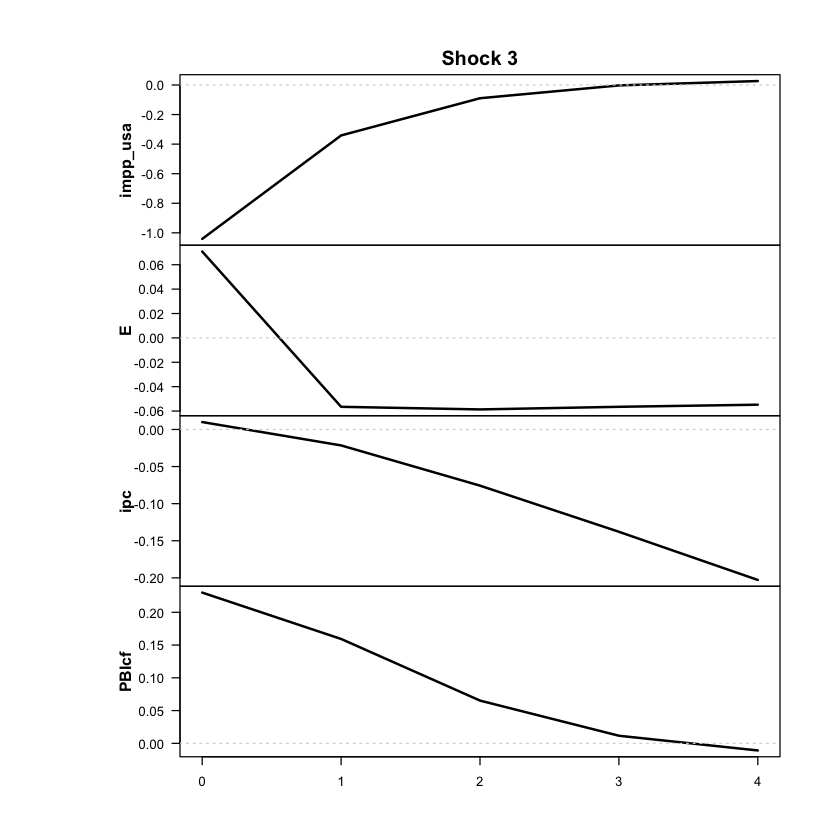

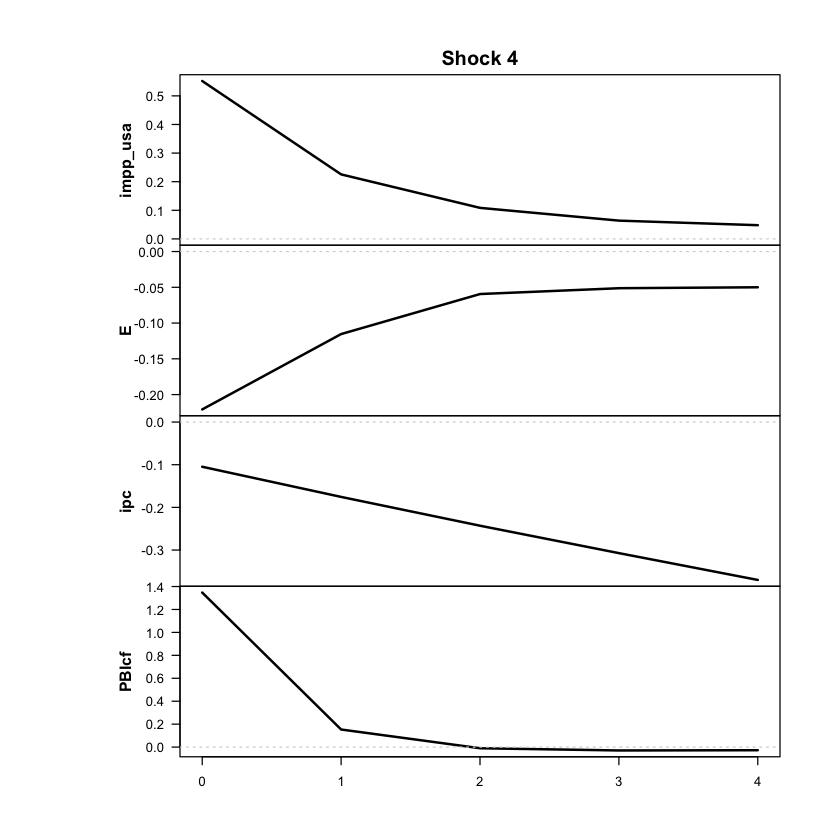

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



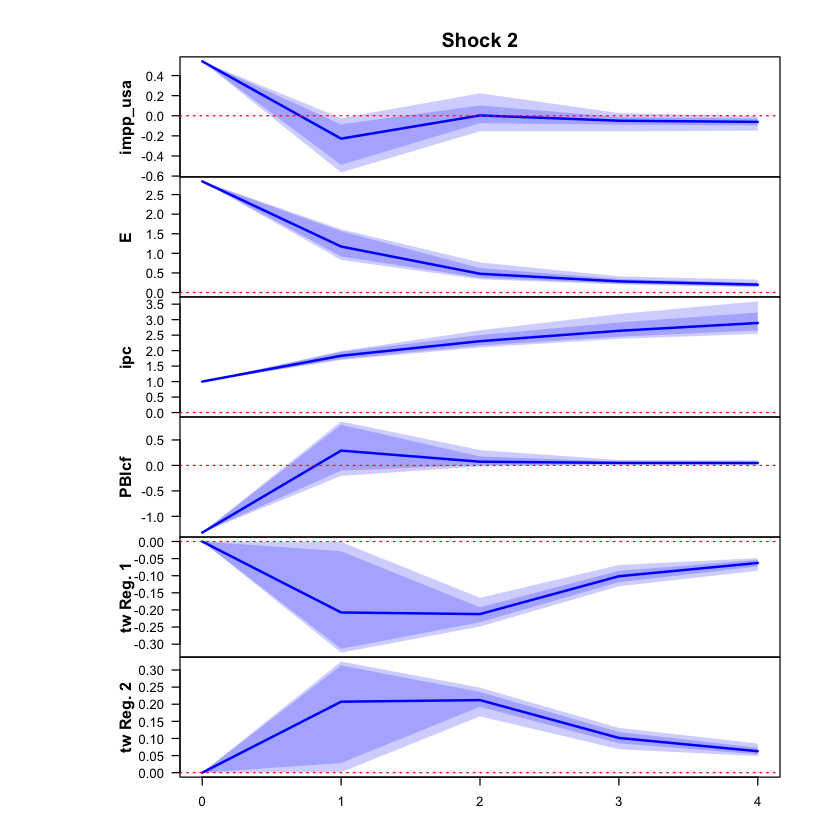

 >>> Linear IRF ( 1  shock units)


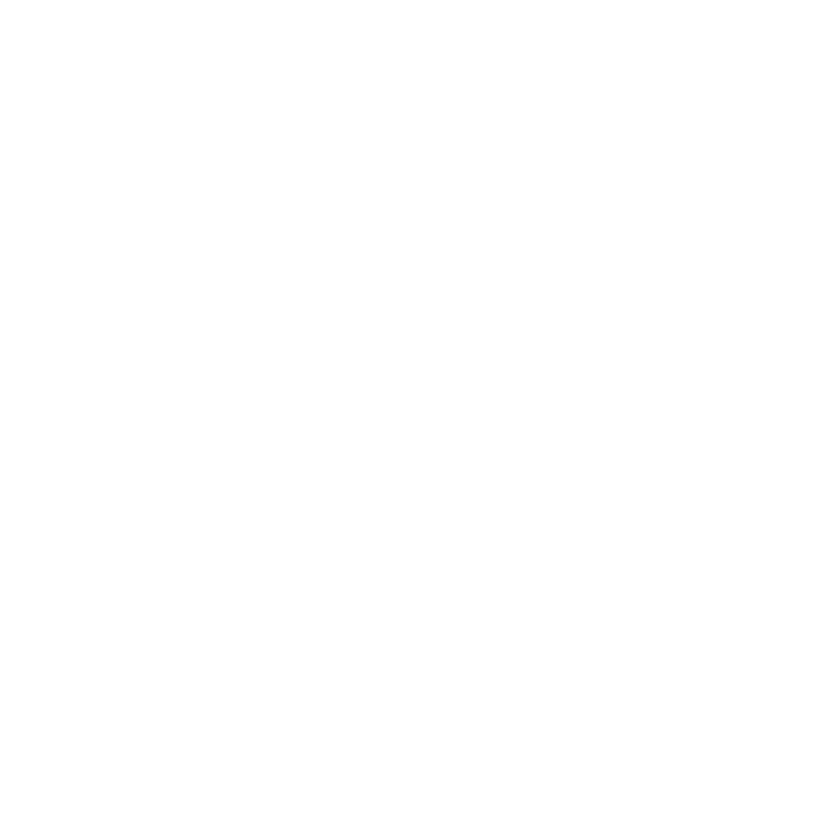

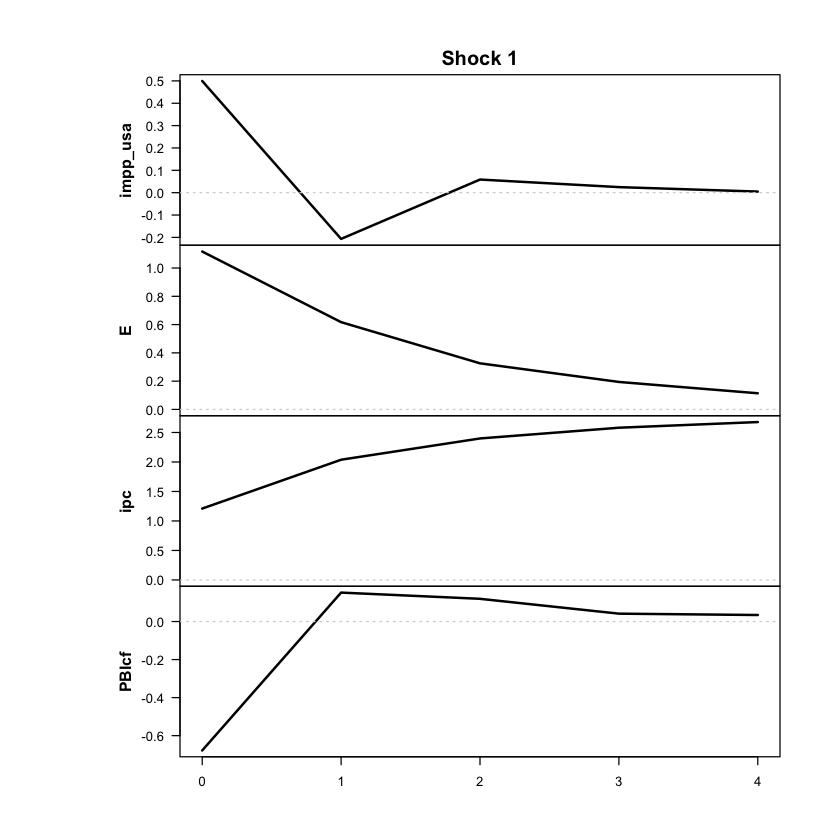

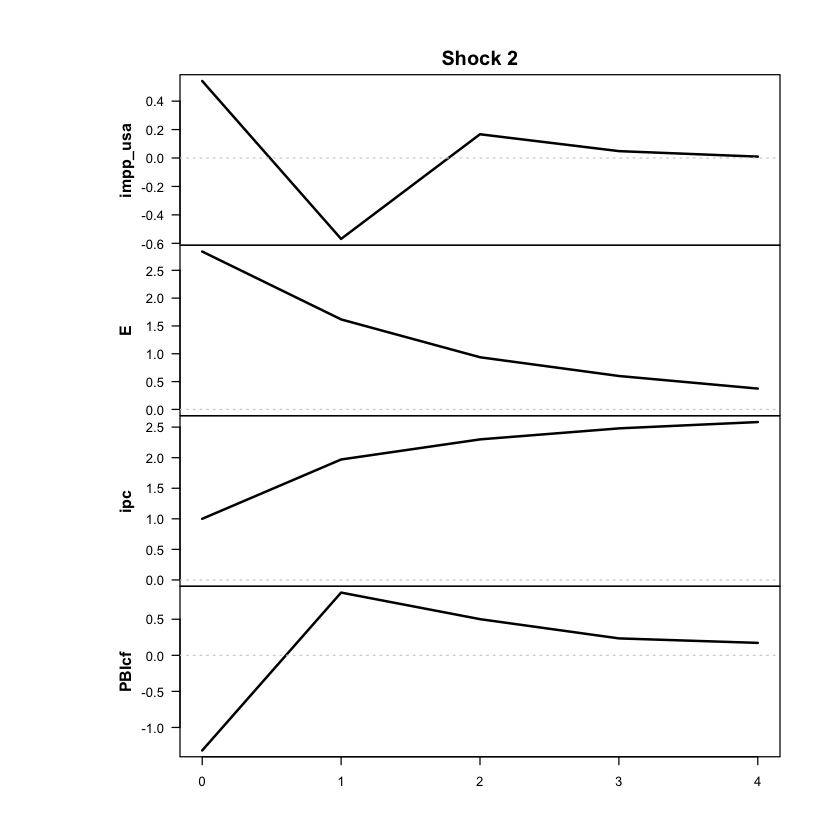

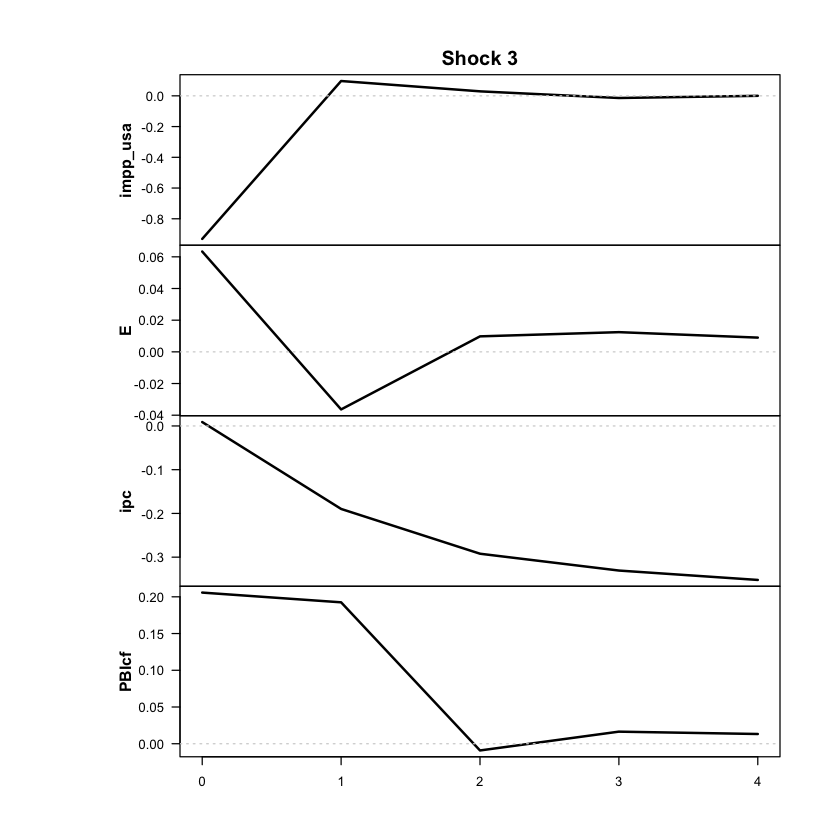

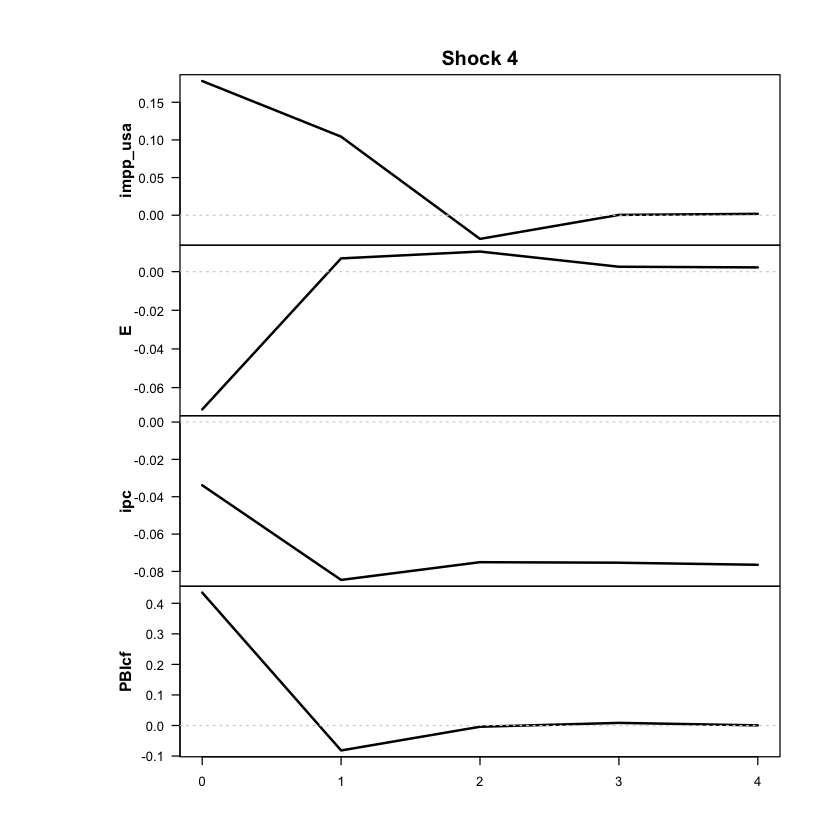

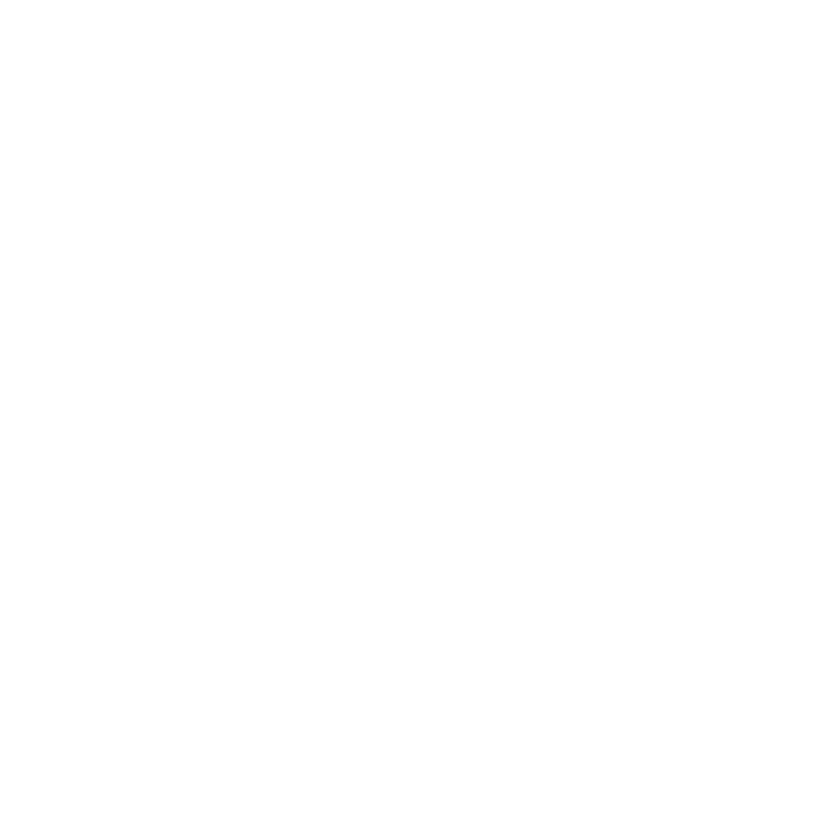

In [93]:
res <- run_vlstar (
  data = df_anual_comb,
  endog = c("impp_usa","E","ipc","PBIcf"),
  periodicity = 'anual', # 'trimestral' o 'anual'
  feature_lag = 1,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIcf")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE,
  cond_dist = "Student"   # errores t de Student
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [94]:
ic_vlstar_t_p1 <- criterios_info(res, "VLSTAR-t p=1")
print(ic_vlstar_t_p1)

        modelo regimenes parametros  loglik   AIC    HQ   BIC
1 VLSTAR-t p=1         2         63 -249.53 625.1 687.6 780.4


In [95]:
resumen_modelo(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"))

Modelo: logistic | regímenes: 2 | rezagos: 1 | errores: Student 
Grados de libertad de la t de Student: 3.64 
Umbral (c): 297.1% anual | gamma: 1.91 
Años por régimen (régimen de mayor peso): régimen 1 = 80 | régimen 2 = 7 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      3.82      2.25
E            32.77    434.94
ipc          35.49    571.24
PBIcf         2.67      1.13


In [96]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -191.39           118.5  3.72        2.6            73/14
             2 -192.19           110.3  3.60        2.5            72/15
             3 -193.34           107.8  3.67        3.0            72/15
             4 -193.55           104.9  3.74        2.5            72/15
             5 -193.75            91.2  4.68        2.8            70/17
             6 -197.69            73.9  6.25        3.1            69/18
             7 -200.23            65.4  7.09        3.1            68/19
             8 -204.01            90.3  3.57        2.7            70/17
             9 -207

In [97]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

logistic Student STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 1, M = 2, d = 4, #parameters = 63, #observations = 87 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Degrees of freedom: 3.64 (for all regimes) 
Weight params: 2.21 (location), 1.91 (scale) 
Regime means: -5.48,  7.56,  9.38,  4.05

   Y      phi0          A1                              Omega                  
1 y1 = [  0.32 ] + [  0.31 -0.16 -0.31 -0.01 ] y1.1 + [  1.40 -0.16 -0.05  0.49
2 y2   [  0.00 ]   [  0.06  0.15  0.74 -0.03 ] y2.1   [ -0.16  0.21  0.09 -0.36
3 y3   [ -0.03 ]   [  0.06  0.20  0.87  0.02 ] y3.1   [ -0.05  0.09  0.04 -0.17
4 y4   [  0.59 ]   [ -0.12 -0.13  0.33  0.17 ] y4.1   [  0.49 -0.36 -0.17  1.90
    1/2     
1 ]     eps1
2 ]     eps2
3 ]     eps3
4 ]     eps4

Regime 2 
Regime means:  0.80, -0.92,  0.12, -0.32

   Y      phi0          A1                              Omega                  
1 y1 = [  0.82 ] + [ -0.05 -0.10  0.09  0.25 ] y1.1 + [  1.20  0.7

In [98]:
shock_vlstar_t_p1 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "PBIcf"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_vlstar_t_p1 <- 2
shock_vlstar_t_p1

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0035  0.0056 -0.0797  0.0422
  E         0.0650  0.2483  0.0456 -0.1421
  ipc       0.0684  0.0850  0.0062 -0.0655
  PBIcf    -0.0028 -0.0083  0.0106  0.0621

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.60    0.85    0.07    0.15 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  1.053   0.342   0.137   0.461 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


[1] 2

### ERPT — VLSTAR t, p = 1

Correr solo si el modelo pasó el diagnóstico. **No pasó: todos los óptimos tienen `descartar = TRUE`. No usar este ERPT ni graficarlo.**

In [99]:
out_impp_usa_vlstar_t_p1 <- erpt_historia(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"), shock_num = shock_vlstar_t_p1)

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 28.2%.

Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 70 | régimen 2 = 2 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9714

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.3424            0.3424
2         1            0.8180            0.6054
3         2            1.2717            0.7647
4         3            1.6985            0.8792
5         4            2.0948            0.9649

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.3424           0.3424
2         1           0.8206           0.6054
3         2           1.2790           0.7647
4         3           1.7120           0.8792
5         4           2.1154           0.9649


In [100]:
out_impp_usa_vlstar_t_p1_acum <- erpt_historia(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"), shock_num = shock_vlstar_t_p1,
                      definicion = "acumulado")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 28.2%.

Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 70 | régimen 2 = 2 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9714

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.3424            0.3424
2         1            0.5734            0.4304
3         2            0.7012            0.4851
4         3            0.7823            0.5247
5         4            0.8390            0.5525

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.3424           0.3424
2         1           0.5747           0.4304
3         2           0.7035           0.4851
4         3           0.7852           0.5247
5         4           0.8424           0.5525


Parámetros usados -> c (escalado): 2.21 | gamma: 1.91 
(deben coincidir con 'Weight params' de print(modelo); si no, pasalos a mano)
Umbral en unidades originales: 1.379 | franja 10%-90%: 0.6618 a 2.0963 


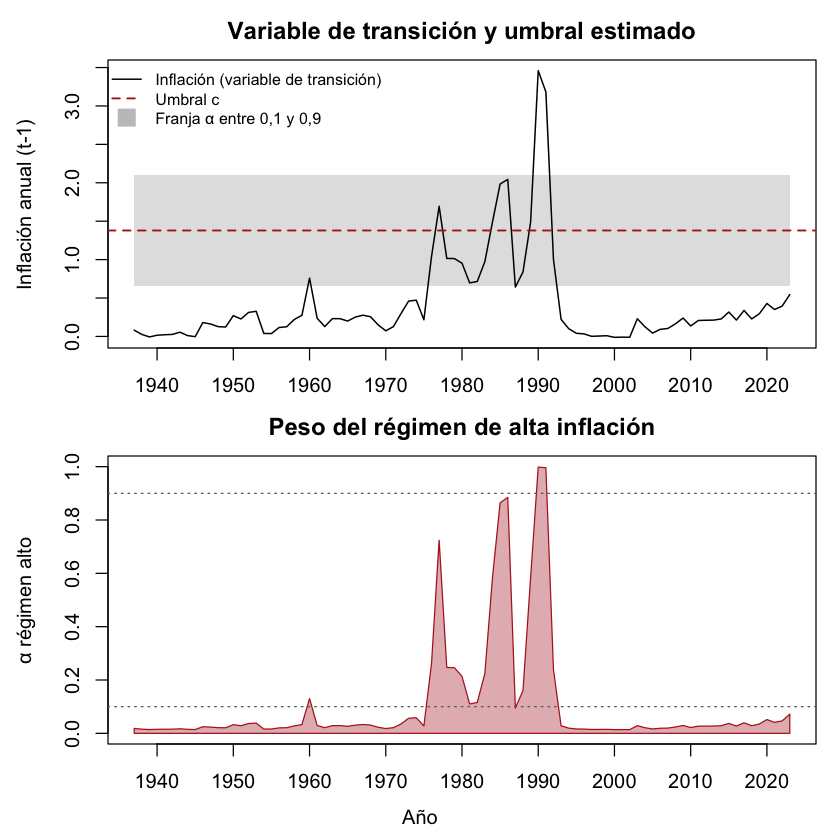

In [101]:
graficar_transicion(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                    archivo = paste0(carpeta, "transicion_impp_usa_vlstar_t_p1_anual_comb"))

### VLSTAR con errores t, p = 2

Desvíos usados para escalar:
  impp_usa          E        ipc      PBIcf 
0.07653640 0.64353427 0.62510191 0.04611195 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -519.704

The largest loglik: -223.409

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -519.704

The largest loglik: -173.454

Filtering inappropriate estimates...

Filtered through 29 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Warning message in warn_eigens(ret, allow_unstab = allow_unstab):
“Regime 1 has near-unit-roots! Consider building a model from the next-largest local maximum with the function 'alt_stvar' by adjusting its argument 'which_largest' (or use the function 'filter_estimates').”
Finished!




========= Unstructured fitted model ==========


Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


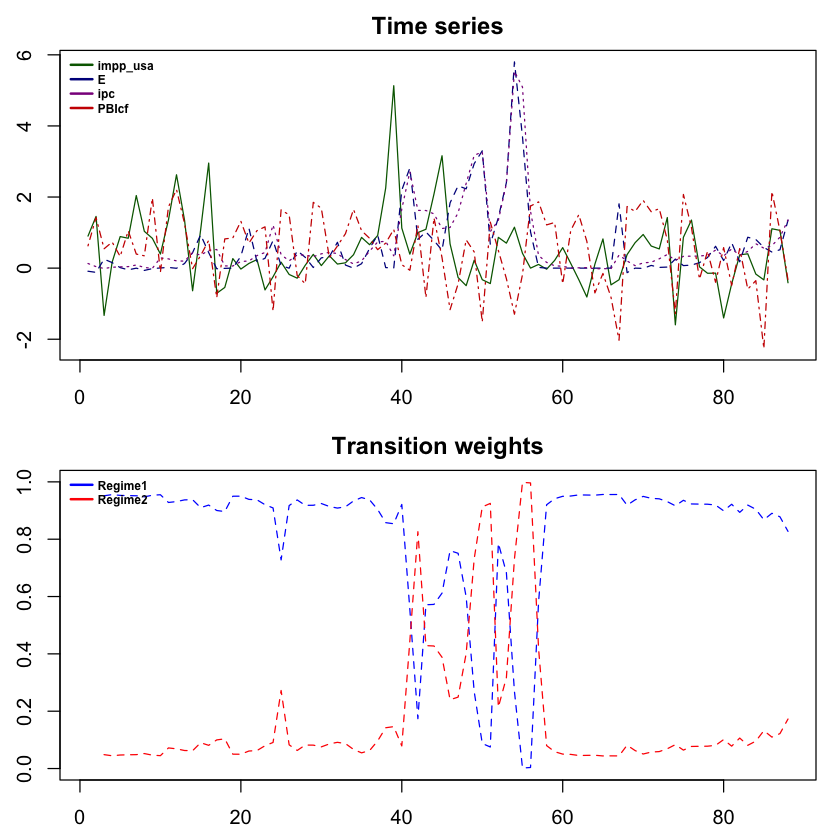

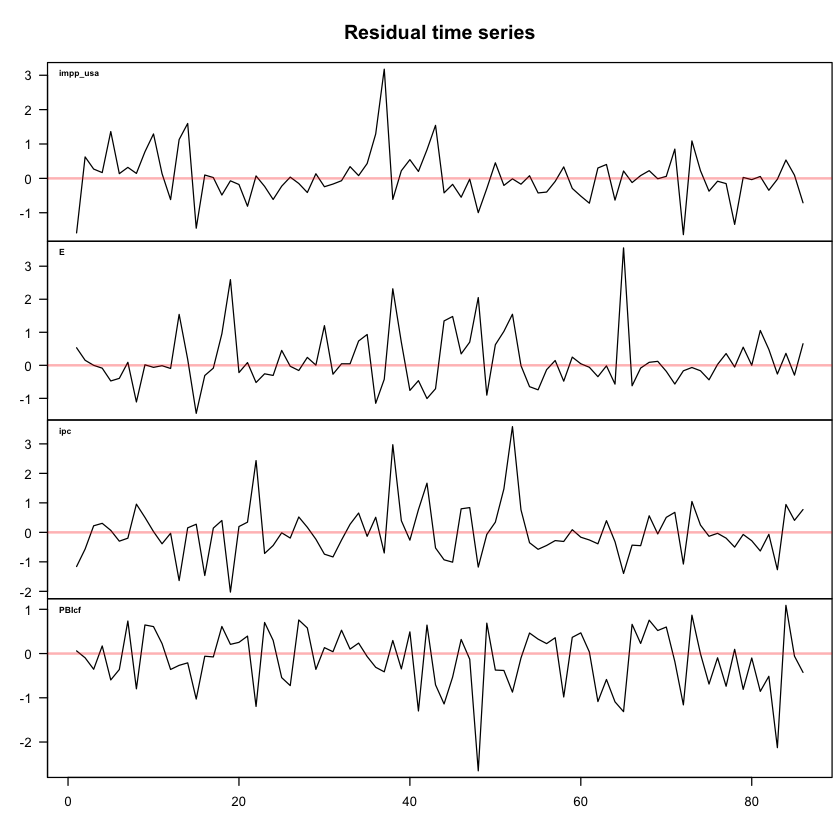

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



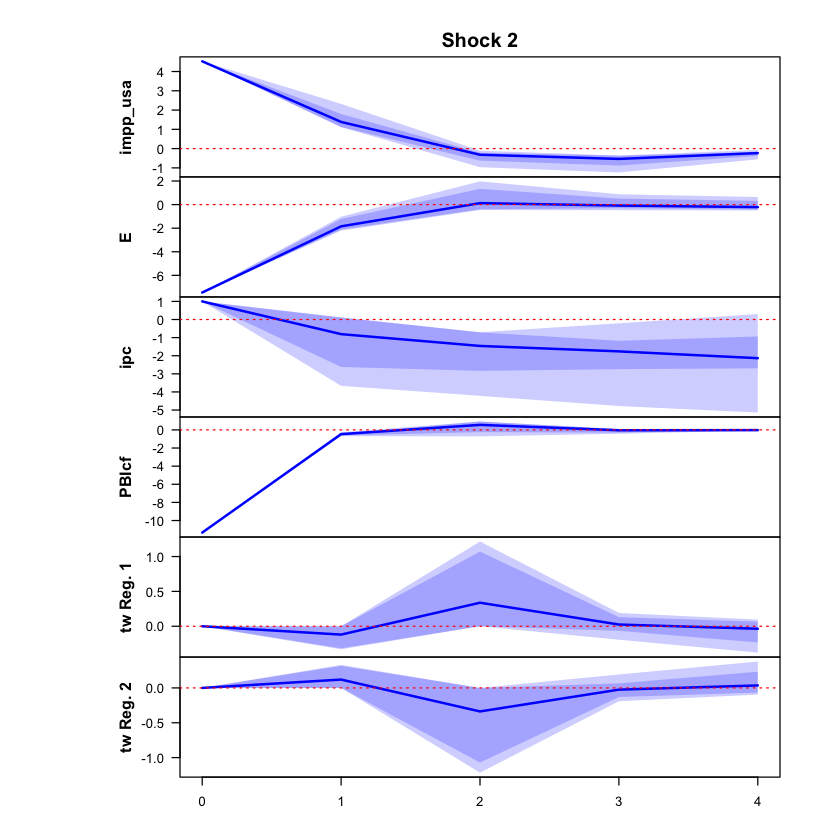

 >>> Linear IRF ( 1  shock units)


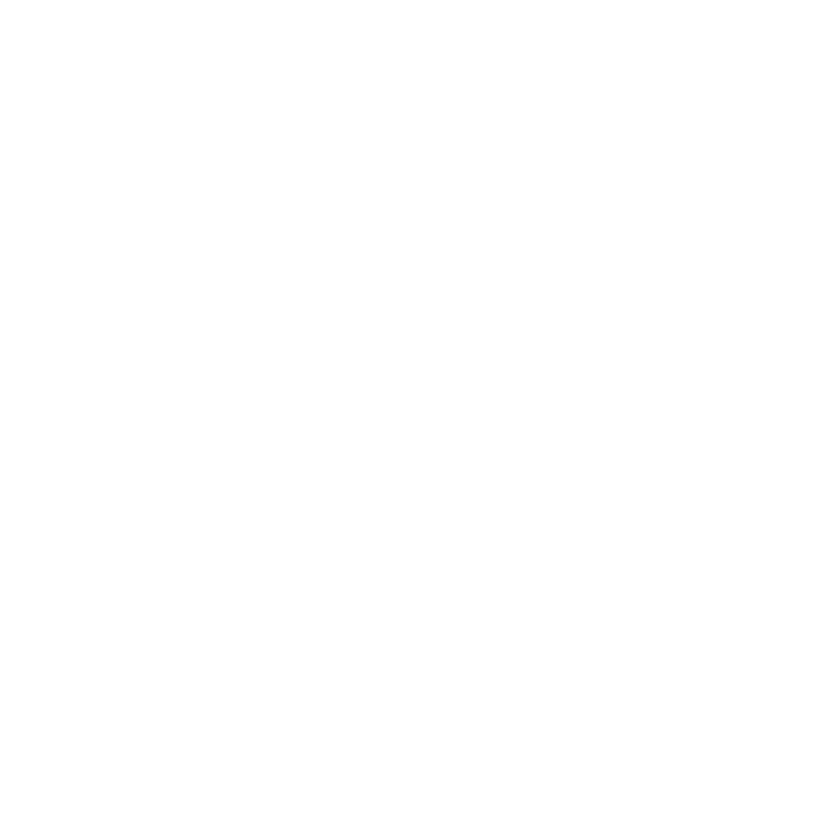

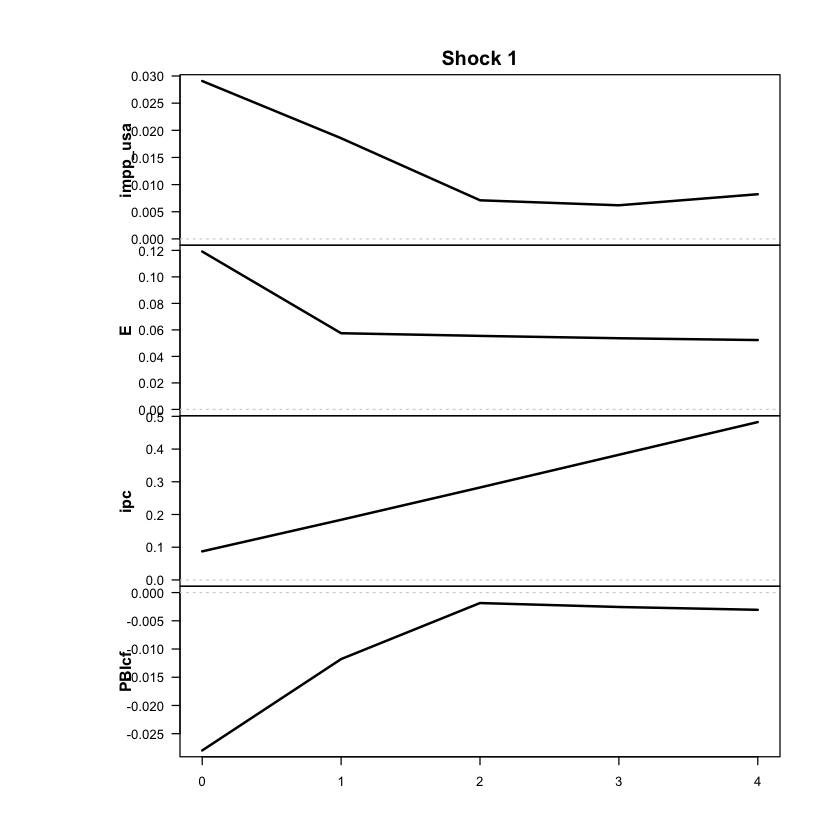

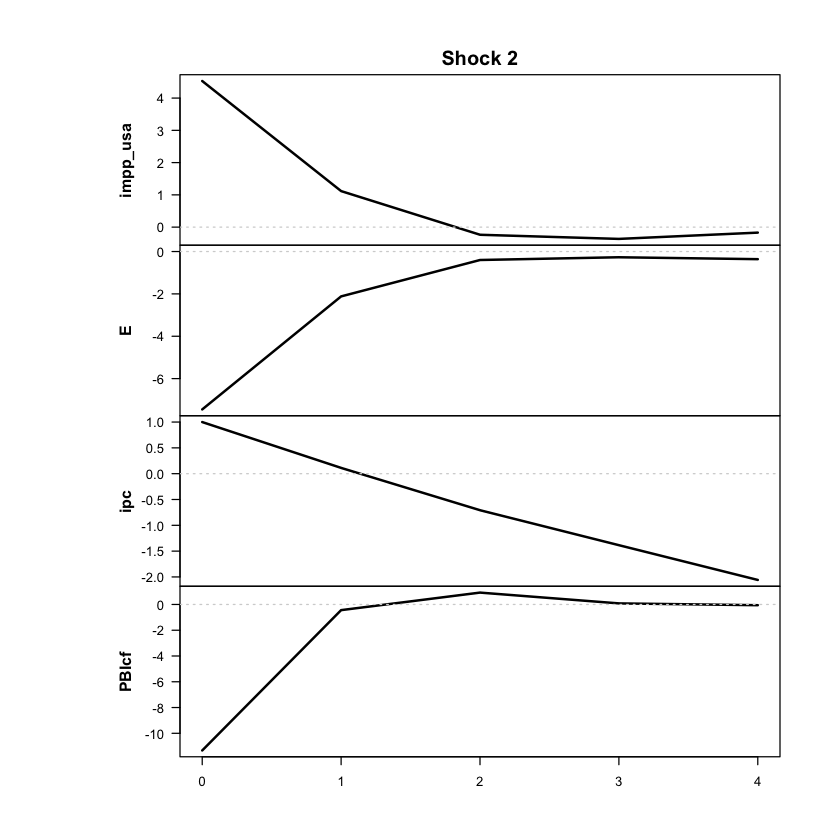

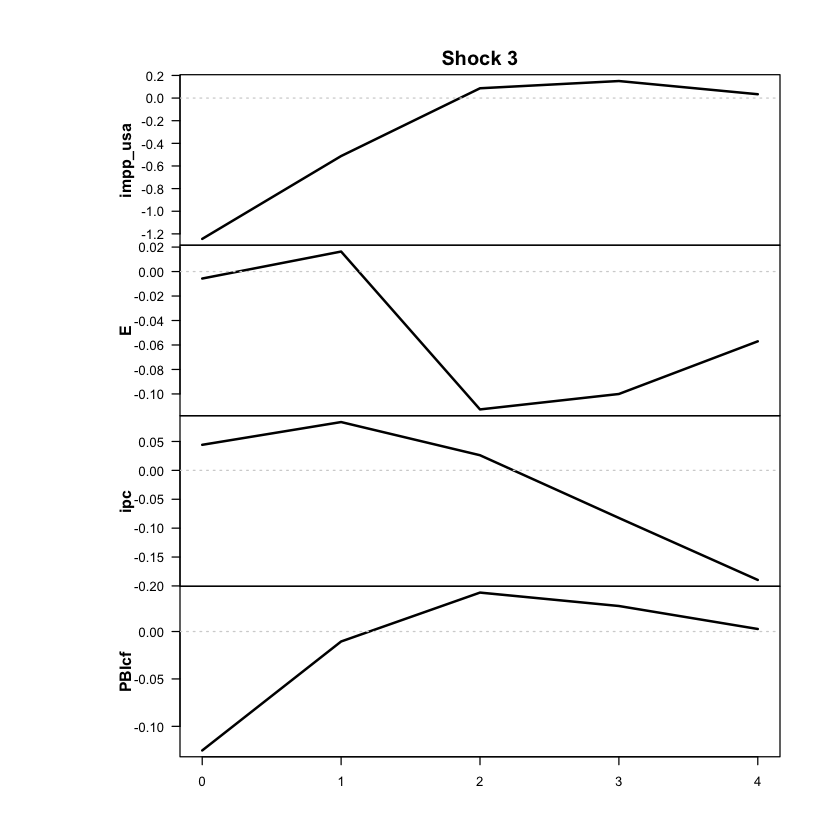

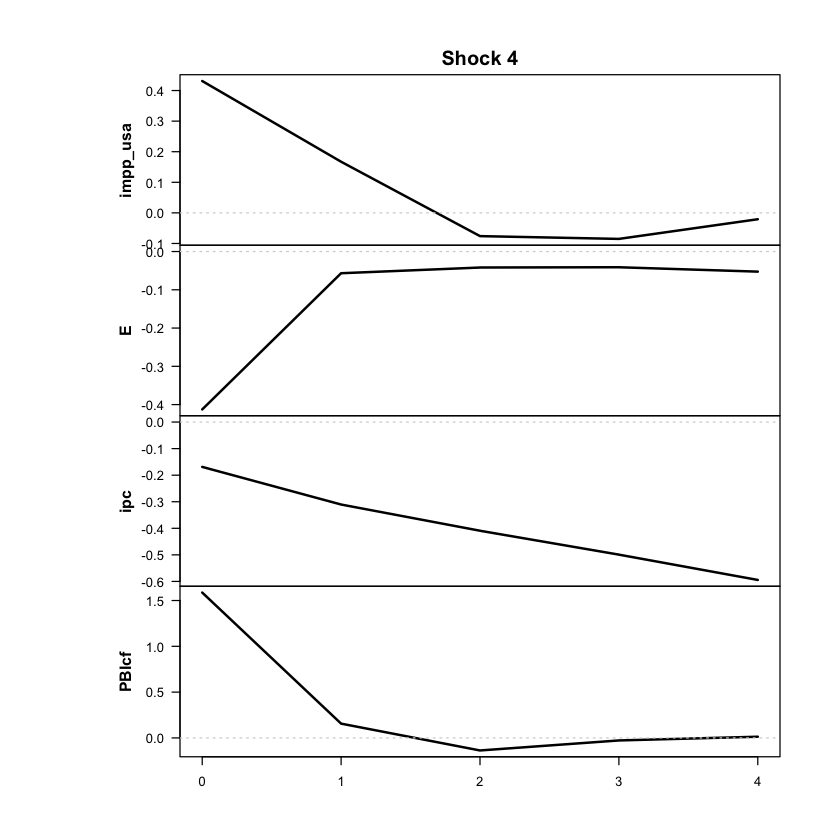

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



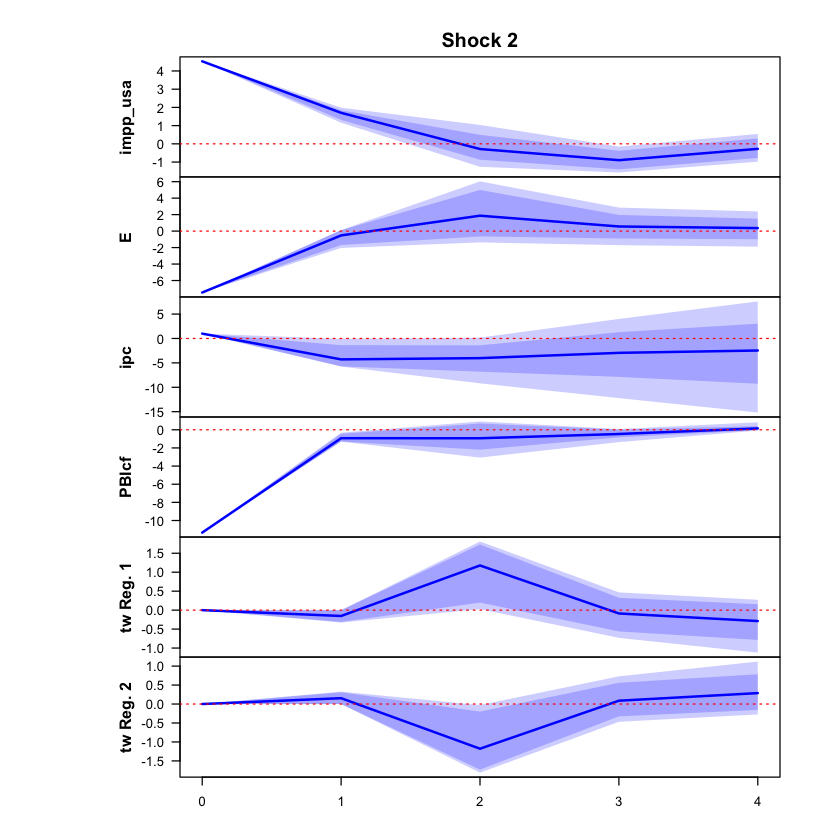

 >>> Linear IRF ( 1  shock units)


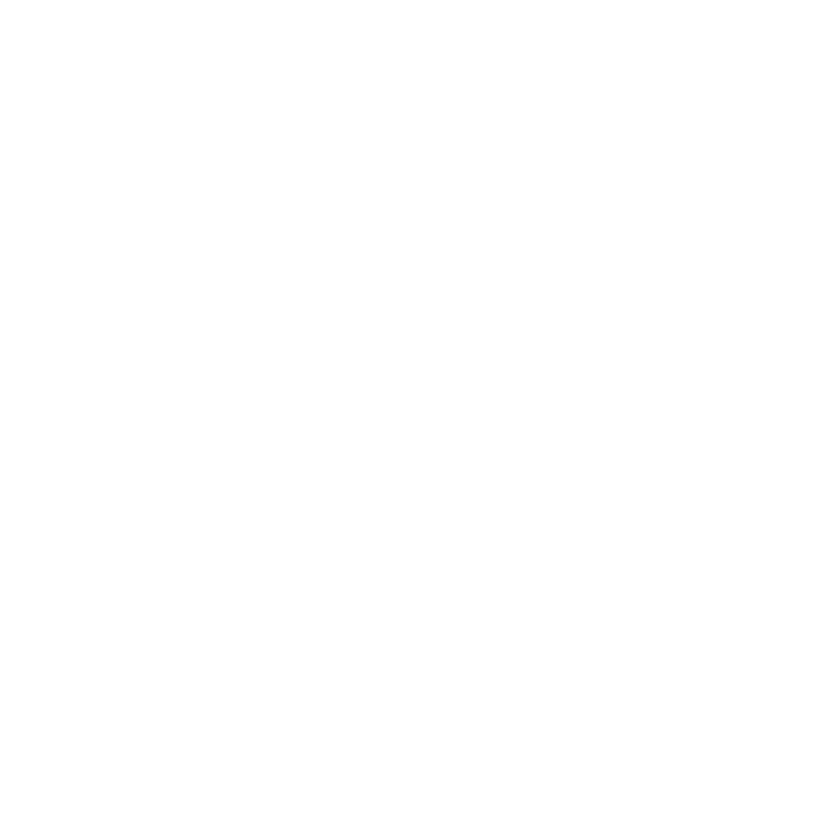

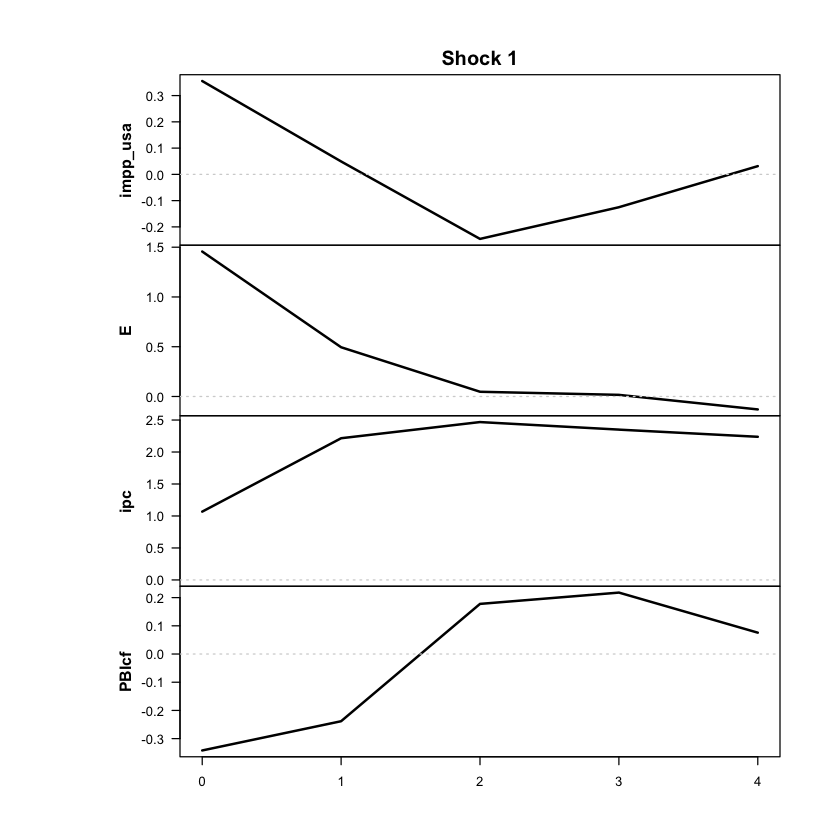

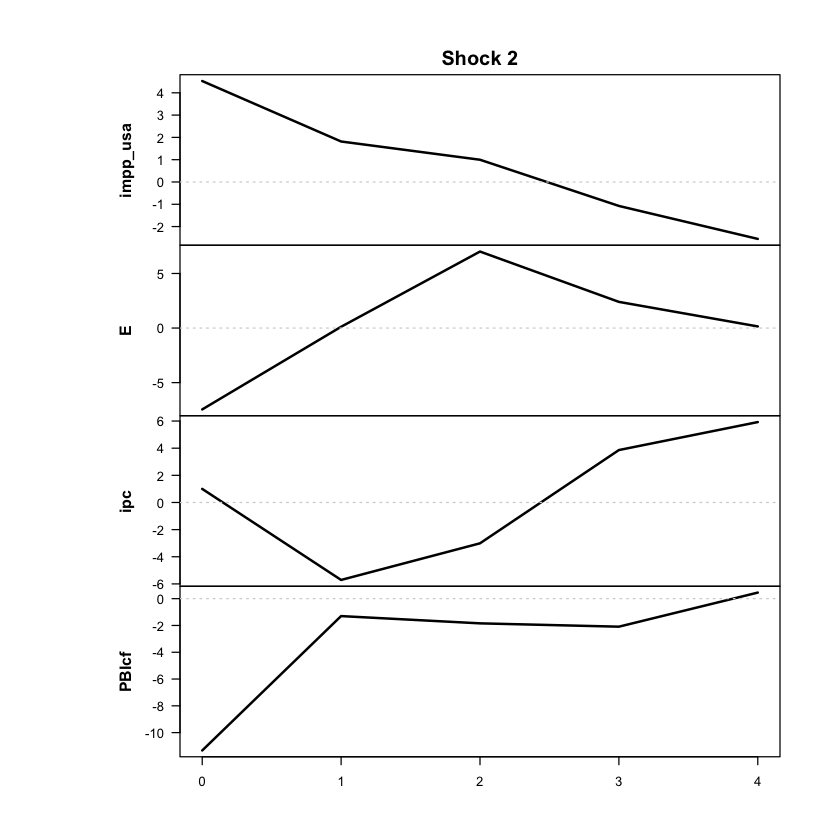

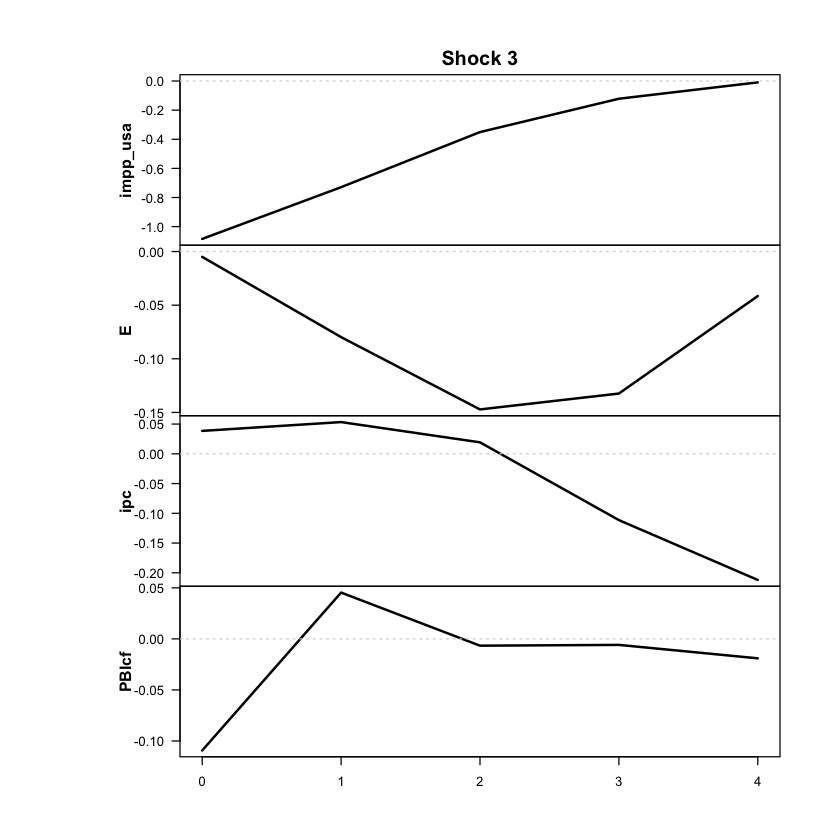

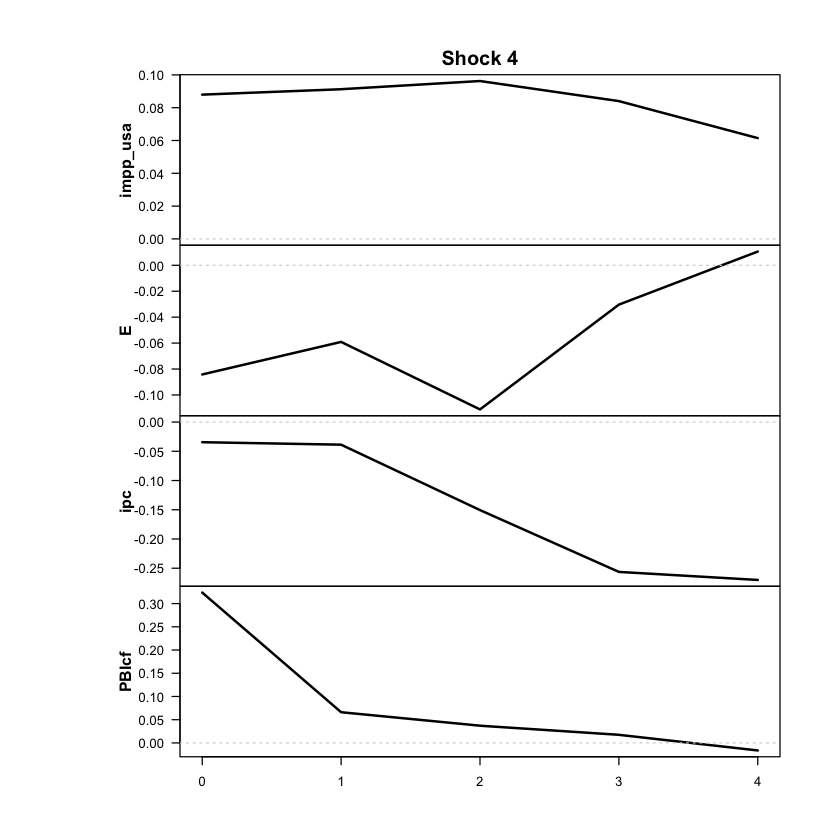

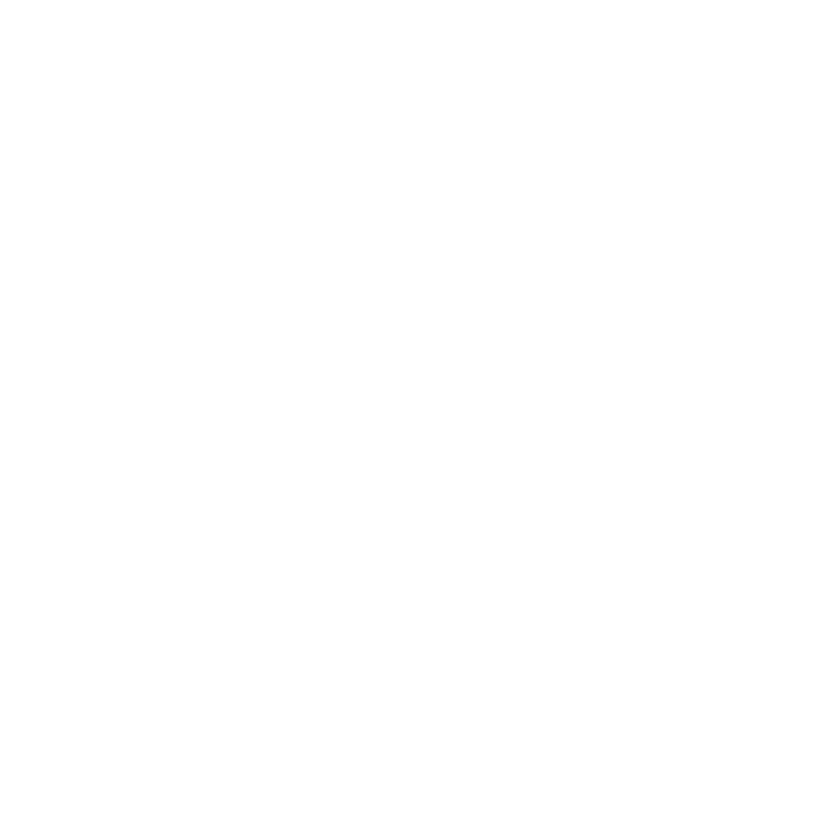

In [102]:
res <- run_vlstar (
  data = df_anual_comb,
  endog = c("impp_usa","E","ipc","PBIcf"),
  periodicity = 'anual', # 'trimestral' o 'anual'
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIcf")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE,
  cond_dist = "Student"   # errores t de Student
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [103]:
ic_vlstar_t_p2 <- criterios_info(res, "VLSTAR-t p=2")
print(ic_vlstar_t_p2)

        modelo regimenes parametros  loglik   AIC    HQ   BIC
1 VLSTAR-t p=2         2         95 -232.16 654.3 748.2 887.5


In [104]:
resumen_modelo(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"))

Modelo: logistic | regímenes: 2 | rezagos: 2 | errores: Student 
Grados de libertad de la t de Student: 2.79 
Umbral (c): 206.8% anual | gamma: 1.7 
Años por régimen (régimen de mayor peso): régimen 1 = 79 | régimen 2 = 7 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      3.72      2.25
E            33.37    434.94
ipc          35.96    571.24
PBIcf         2.62      1.13


In [105]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -173.45            79.6  4.20        2.7            68/18
             2 -175.99            88.9  4.54        2.8            68/18
             3 -188.10            60.6 12.46        2.9            67/19
             4 -202.47           100.7  2.75        2.3            69/17
             5 -205.04           119.9  3.08        3.5            72/14
             6 -205.57           127.1  3.02        3.9            72/14
             7 -209.39           186.8  3.36        4.1             79/7
             8 -209.58           116.4  2.19        2.6            72/14
             9 -210

In [106]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

logistic Student STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 2, M = 2, d = 4, #parameters = 95, #observations = 86 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Degrees of freedom: 2.79 (for all regimes) 
Weight params: 1.79 (location), 1.70 (scale) 
Regime means: 0.35, 0.38, 0.82, 0.78

   Y      phi0          A1                                 A2                  
1 y1 = [  0.24 ] + [  0.41  0.08 -0.03  0.01 ] y1.1 + [ -0.23 -0.02  0.07 -0.03
2 y2   [ -0.11 ]   [ -0.01  0.23  0.37  0.07 ] y2.1   [  0.11  0.03  0.01 -0.01
3 y3   [ -0.05 ]   [ -0.01  0.16  0.90  0.05 ] y3.1   [  0.08  0.00  0.00  0.00
4 y4   [  0.81 ]   [  0.00 -0.06 -0.02  0.08 ] y4.1   [ -0.03  0.01  0.02 -0.09
             Omega                     1/2     
1 ] y1.2 + [  1.75 -0.19 -0.12  0.81 ]     eps1
2 ] y2.2   [ -0.19  0.21  0.08 -0.61 ]     eps2
3 ] y3.2   [ -0.12  0.08  0.04 -0.28 ]     eps3
4 ] y4.2   [  0.81 -0.61 -0.28  2.60 ]     eps4

Regime 2 
Regime means: 1.5

In [107]:
shock_vlstar_t_p2 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "PBIcf"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_vlstar_t_p2 <- 2
shock_vlstar_t_p2

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0022 -0.0079 -0.0952  0.0330
  E         0.0767  0.1100 -0.0037 -0.2655
  ipc       0.0546 -0.0143  0.0276 -0.1055
  PBIcf    -0.0013  0.0120 -0.0058  0.0732

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.78    0.52    0.00    0.24 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.712  -0.130  -7.528   0.397 

>>> Shock sugerido como cambiario: 1 (confirmalo: debe mover mucho a E y poco a ipc )


[1] 1

### ERPT — VLSTAR t, p = 2

Correr solo si el modelo pasó el diagnóstico. **No pasó: todos los óptimos tienen `descartar = TRUE`. No usar este ERPT ni graficarlo.**

In [108]:
out_impp_usa_vlstar_t_p2 <- erpt_historia(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"), shock_num = shock_vlstar_t_p2)

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 8.0%.

Estimando 86 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 1...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 59 | régimen 2 = 4 
Shock usado:1| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9714

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.7122            0.7122
2         1            1.5002            1.2919
3         2            2.2817            1.4656
4         3            3.0311            1.5579
5         4            3.7194            1.6046

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.7122           0.7122
2         1           1.4975           1.2756
3         2           2.2845           1.4456
4         3           3.0405           1.5339
5         4           3.7418           1.5802


In [109]:
out_impp_usa_vlstar_t_p2_acum <- erpt_historia(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"), shock_num = shock_vlstar_t_p2,
                      definicion = "acumulado")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 8.0%.

Estimando 86 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 1...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 59 | régimen 2 = 4 
Shock usado:1| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9714

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.7122            0.7122
2         1            0.9590            0.9269
3         2            1.0687            0.9225
4         3            1.1276            0.9255
5         4            1.1623            0.9342

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.7122           0.7122
2         1           0.9600           0.8834
3         2           1.0710           0.9040
4         3           1.1300           0.9096
5         4           1.1651           0.9155


Parámetros usados -> c (escalado): 1.79 | gamma: 1.7 
(deben coincidir con 'Weight params' de print(modelo); si no, pasalos a mano)
Umbral en unidades originales: 1.1209 | franja 10%-90%: 0.313 a 1.9288 


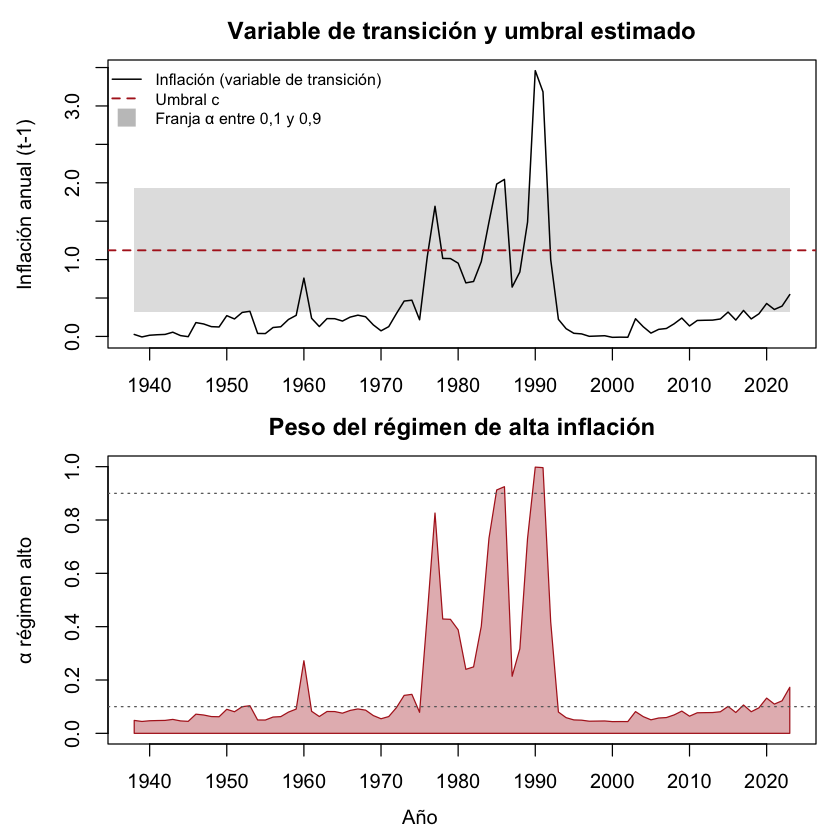

In [110]:
graficar_transicion(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                    archivo = paste0(carpeta, "transicion_impp_usa_vlstar_t_p2_anual_comb"))

### Comparación: gaussiano vs. t de Student

In [111]:
rbind(ic_tvar_p1, ic_tvar_p2, ic_tvar_t_p1, ic_vlstar_t_p1, ic_vlstar_t_p2)

modelo,regimenes,parametros,loglik,AIC,HQ,BIC
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
TVAR p=1,2,61,-233.71,589.4,650.0,739.8
TVAR p=2,2,93,-215.00,616.0,707.9,844.3
TVAR-t p=1,2,62,-203.05,530.1,591.7,683.0
VLSTAR-t p=1,2,63,-249.53,625.1,687.6,780.4
VLSTAR-t p=2,2,95,-232.16,654.3,748.2,887.5


## VLSTAR gaussiano, 2 regímenes, p = 1 — estimación en tres etapas

La estimación en tres etapas (`estim_method = "three-phase"`) empieza estimando los coeficientes por mínimos cuadrados y descarta los puntos de partida en los que algún régimen tiene muy pocas observaciones en relación con sus parámetros (`min_obs_coef`). Objetivo: evitar las soluciones degeneradas que aíslan los trimestres de hiperinflación. El modelo se guarda con `3fases_moc3` en el nombre del archivo; los modelos en dos etapas no se pisan.

Se cargó exitosamente modelos preguardados  vlstar_3fases_moc2_1_2_500_ca9210ddc70cf436bf28f7ae5de74060.rds  de la carpeta models

 >>> DIAGNOSTIC PLOTS


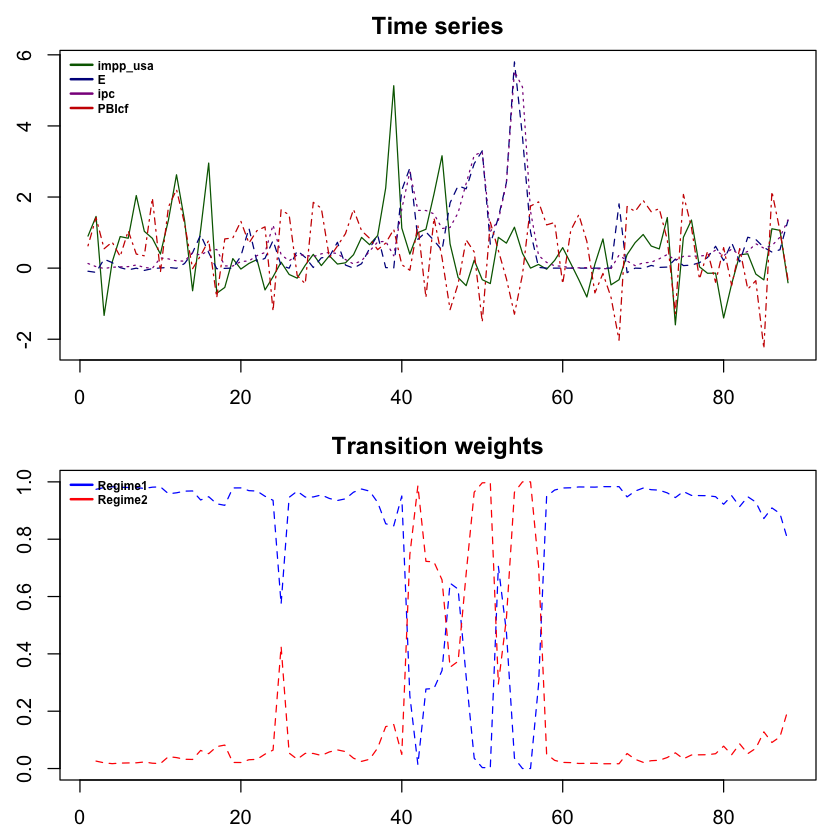

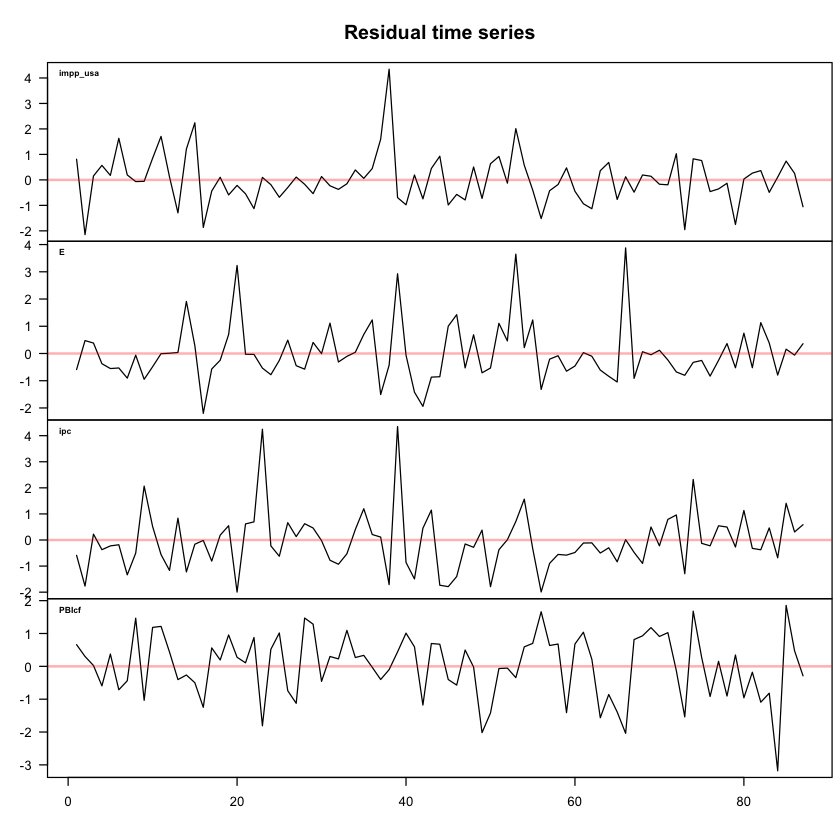

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



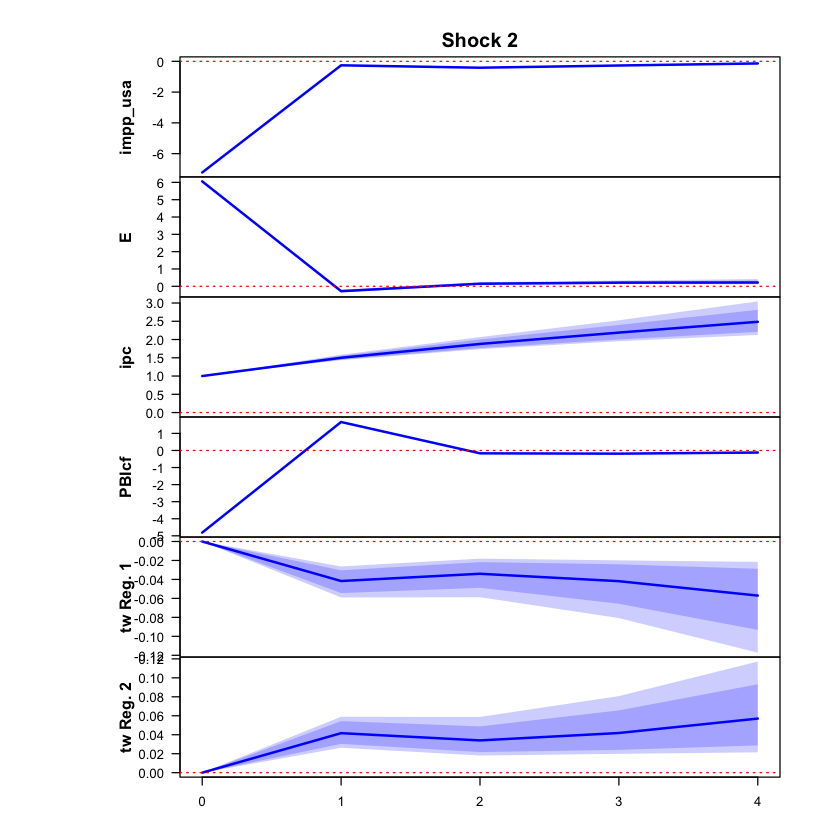

 >>> Linear IRF ( 1  shock units)


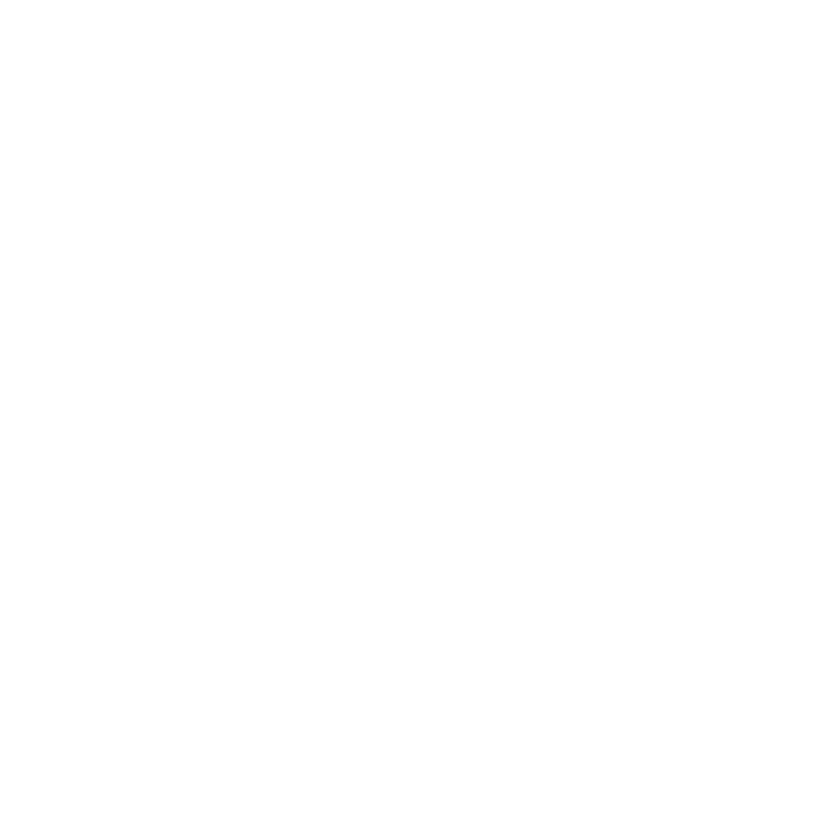

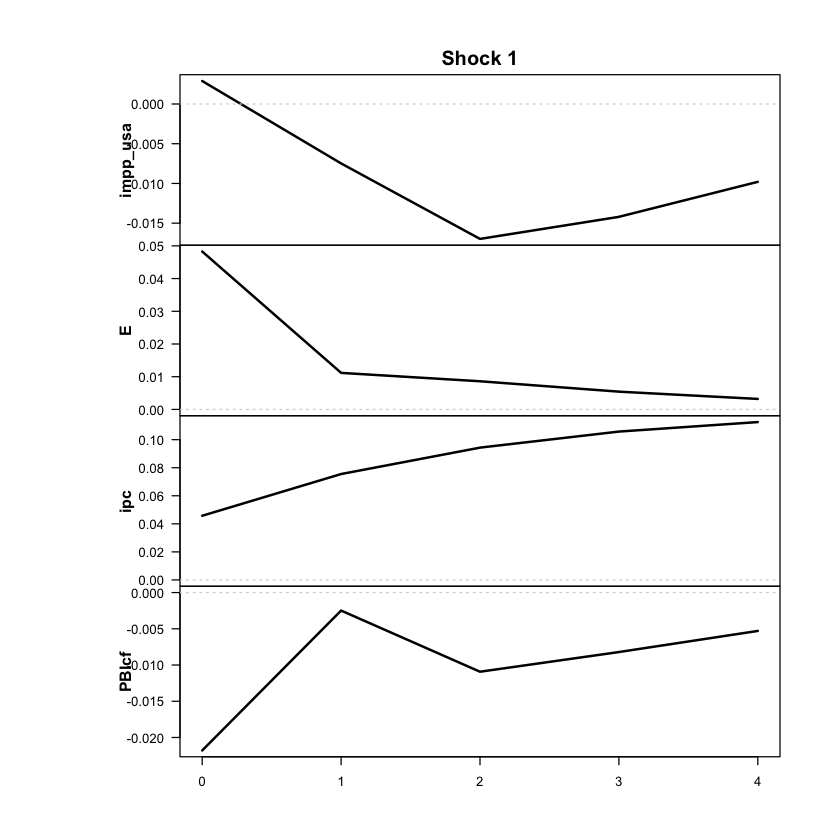

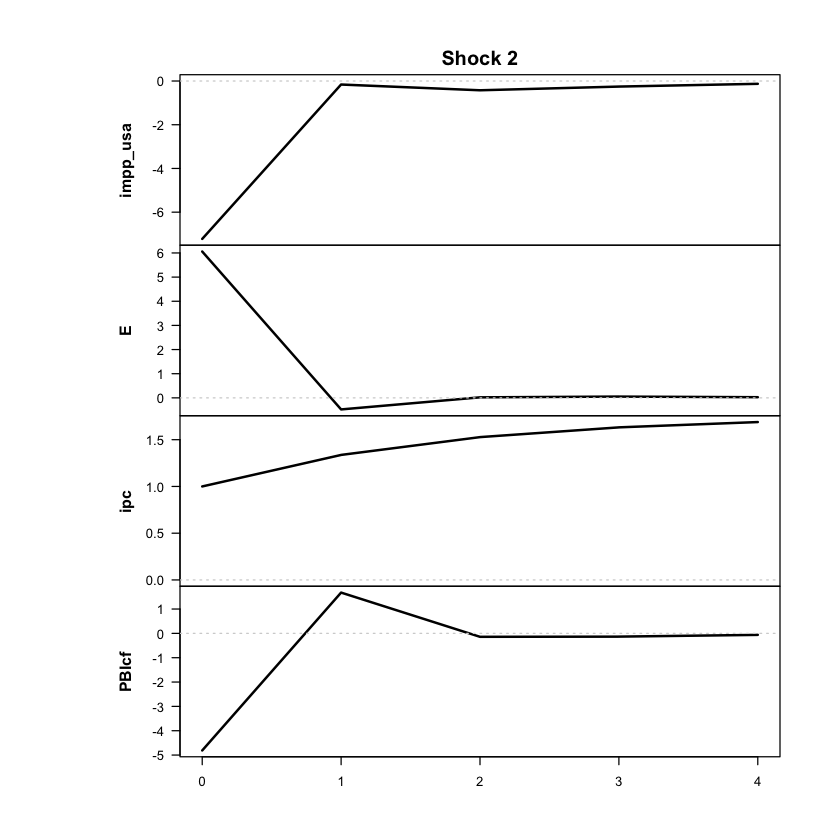

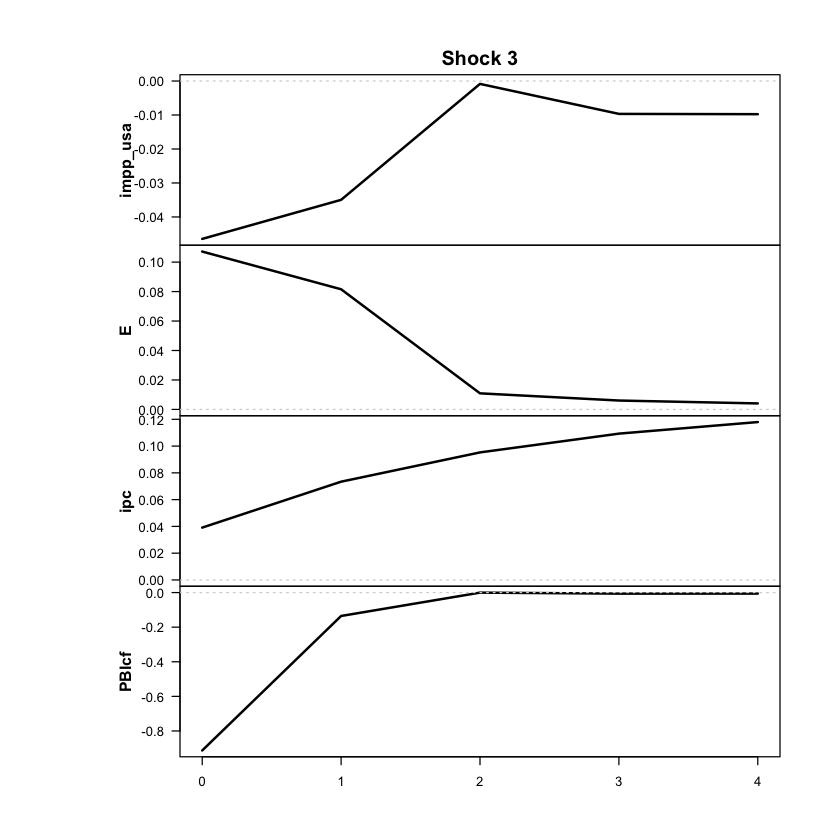

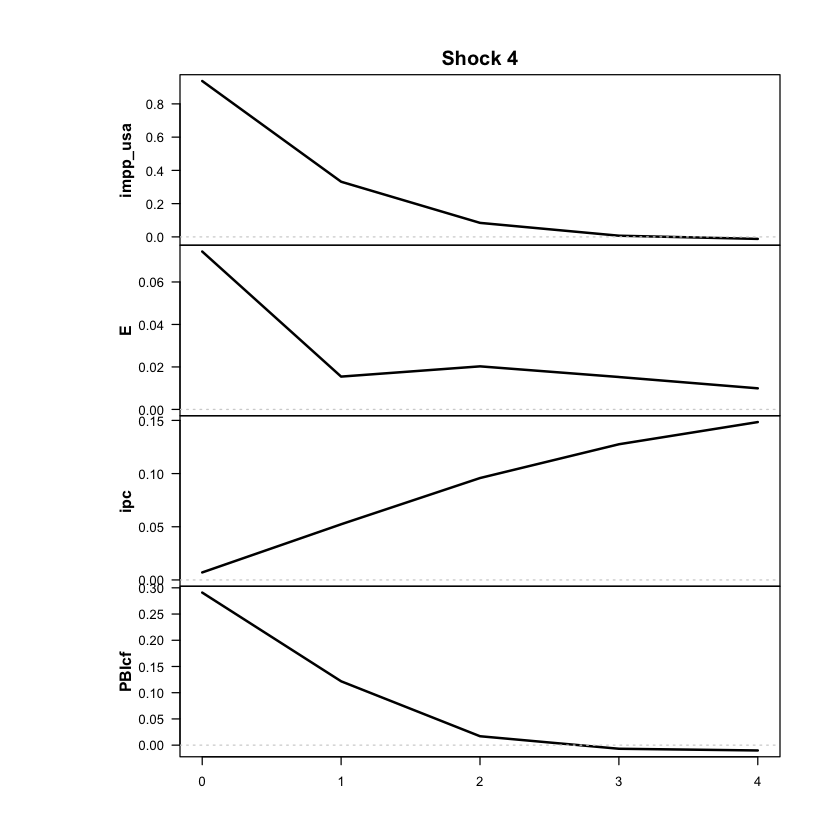

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



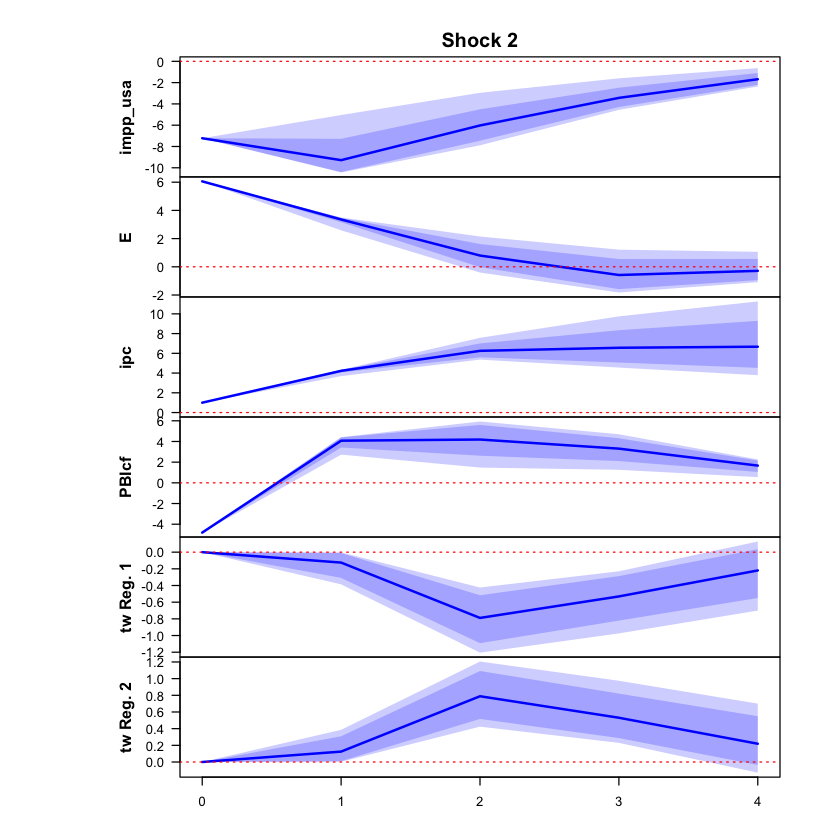

 >>> Linear IRF ( 1  shock units)


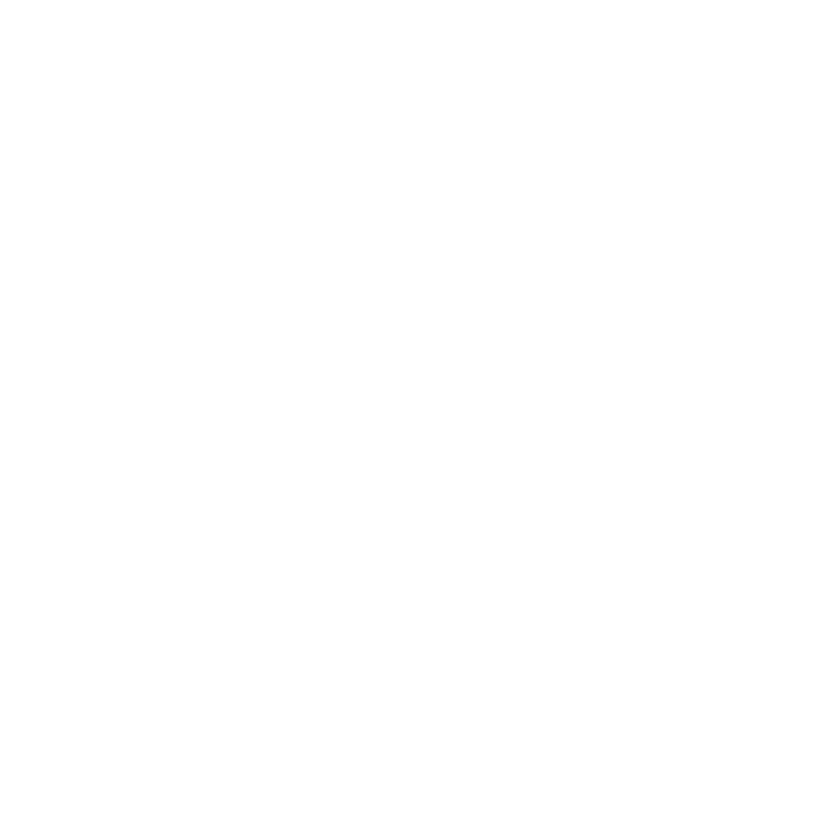

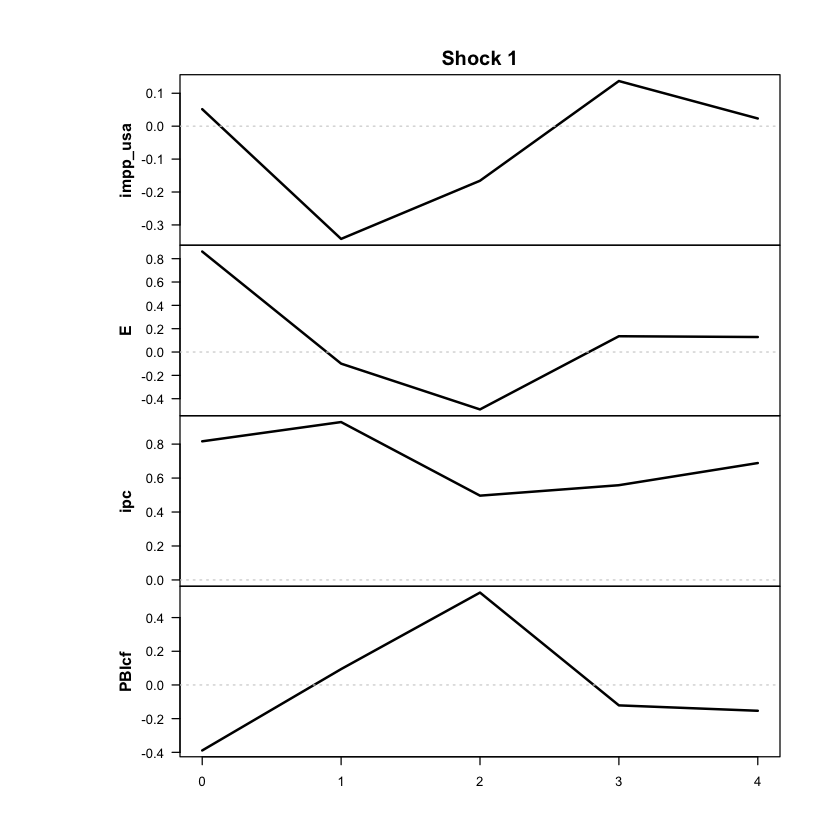

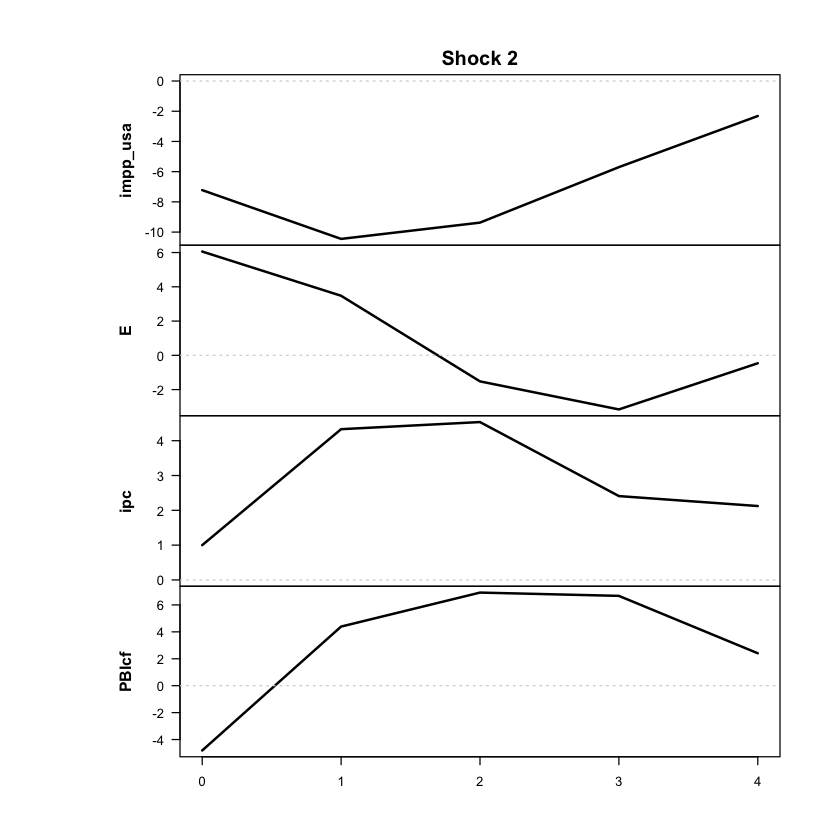

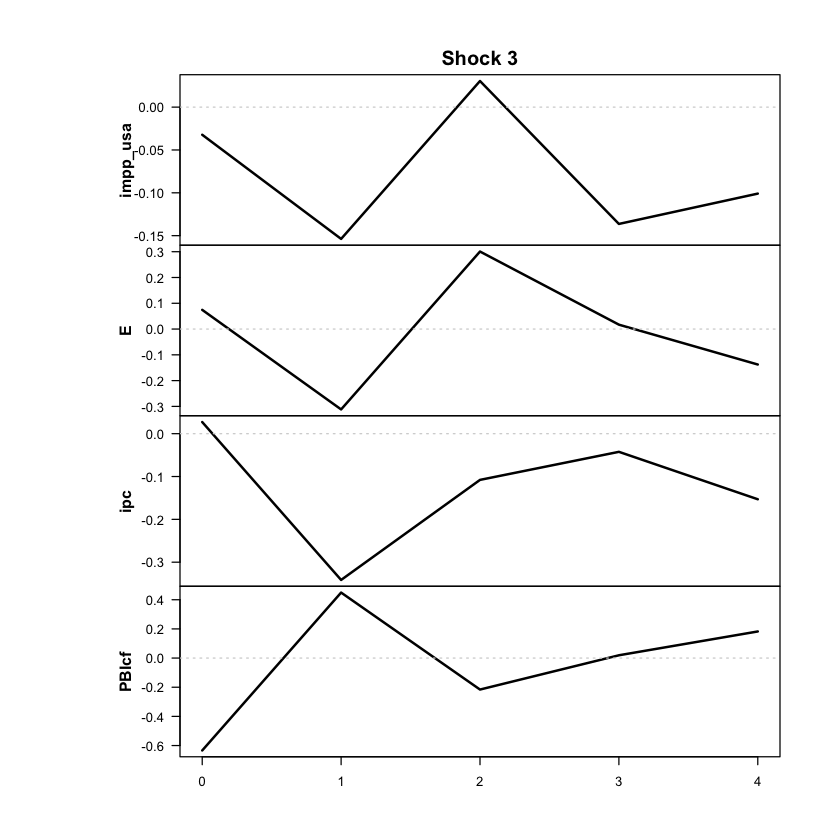

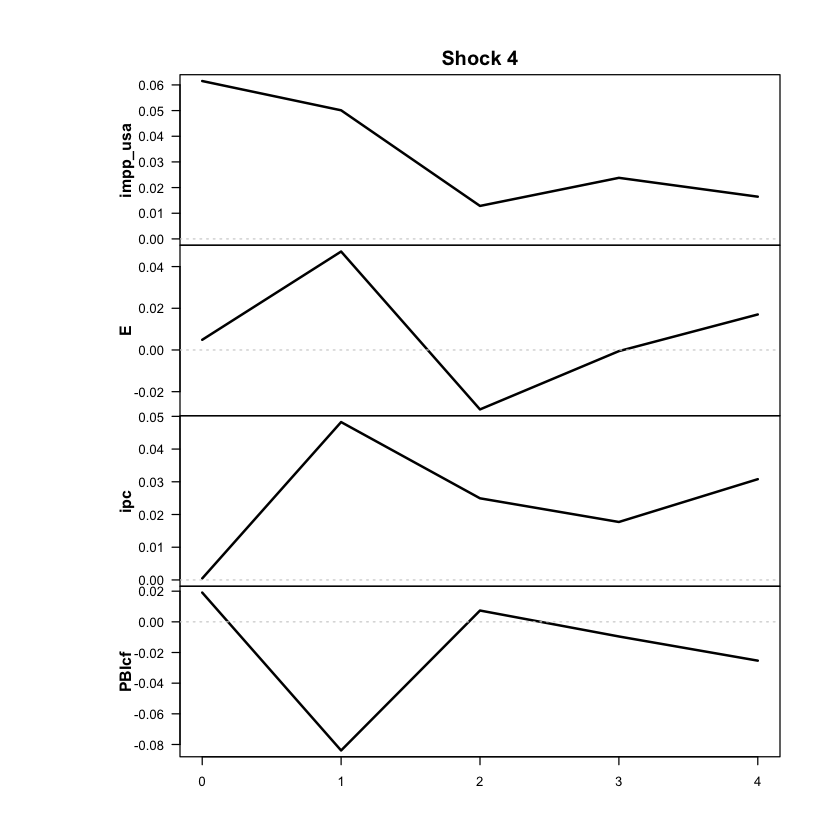

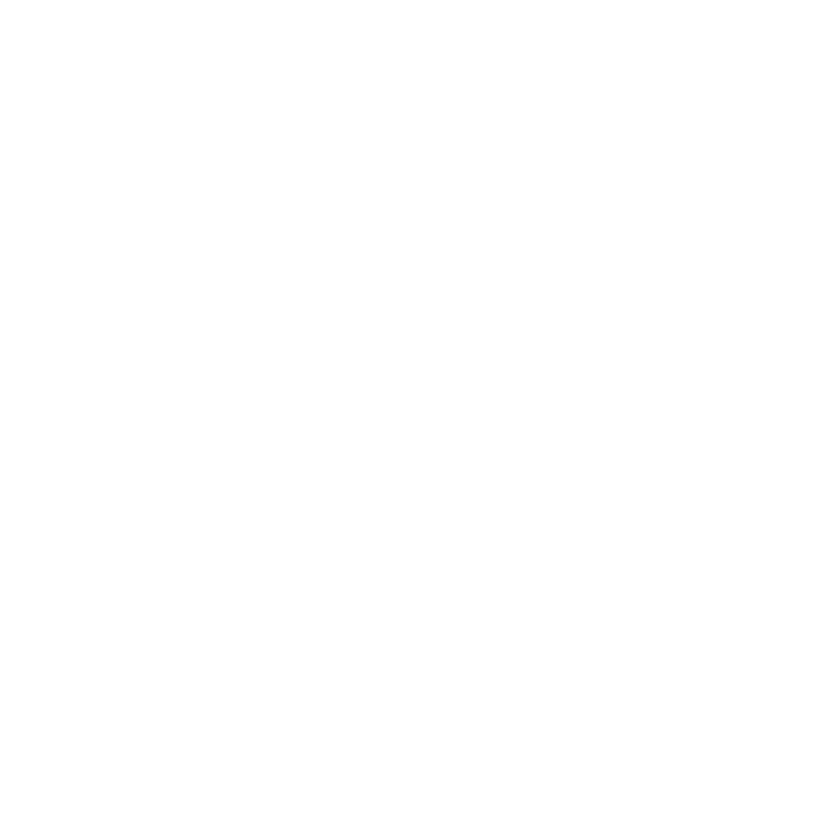

In [31]:
res <- run_vlstar (
  data = df_anual_comb,
  endog = c("impp_usa","E","ipc","PBIcf"),
  periodicity = 'anual', # 'trimestral' o 'anual'
  feature_lag = 1,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIcf")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = TRUE,
  estim_method = "three-phase",   # estimación en tres etapas
  min_obs_coef = 2                # con 88 años, 3 (default) exige más observaciones por régimen de las que hay
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [32]:
ic_vlstar_3f_p1 <- criterios_info(res, "VLSTAR 3 etapas p=1")
print(ic_vlstar_3f_p1)
saveRDS(ic_vlstar_3f_p1, "ic_vlstar_3f_p1_anual_comb.rds")

               modelo regimenes parametros  loglik   AIC  HQ   BIC
1 VLSTAR 3 etapas p=1         2         62 -234.21 592.4 654 745.3


In [114]:
resumen_modelo(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"))

Modelo: logistic | regímenes: 2 | rezagos: 1 | errores: Gaussian 
Umbral (c): 127.1% anual | gamma: 3.07 
Años por régimen (régimen de mayor peso): régimen 1 = 73 | régimen 2 = 14 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      3.42      5.09
E            25.16    262.46
ipc          25.77    344.55
PBIcf         2.73      1.63


In [115]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -234.21           127.1  3.07         NA            73/14
             2 -246.26            92.3  2.44         NA            70/17
             3 -246.49            90.5  2.50         NA            70/17
             4 -246.54            95.6  2.29         NA            70/17
             5 -247.55            76.9  2.17         NA            69/18
             6 -247.88            97.3  2.56         NA            70/17
             7 -247.95            70.8  2.20         NA            68/19
             8 -248.15            72.5  2.19         NA            69/18
             9 -248

In [116]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

logistic Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 1, M = 2, d = 4, #parameters = 62, #observations = 87 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Weight params: 1.31 (location), 3.07 (scale) 
Regime means: 0.44, 0.10, 0.07, 0.68

   Y     phi0          A1                              Omega                  
1 y1 = [ 0.27 ] + [  0.30  0.49 -0.67  0.05 ] y1.1 + [  1.03 -0.06 -0.02  0.41
2 y2   [ 0.13 ]   [  0.05 -0.15  0.35 -0.09 ] y2.1   [ -0.06  0.12  0.02 -0.16
3 y3   [ 0.01 ]   [  0.05  0.00  0.65 -0.01 ] y3.1   [ -0.02  0.02  0.01 -0.05
4 y4   [ 0.52 ]   [  0.03  0.55 -0.55  0.19 ] y4.1   [  0.41 -0.16 -0.05  0.98
    1/2     
1 ]     eps1
2 ]     eps2
3 ]     eps3
4 ]     eps4

Regime 2 
Regime means:  1.38,  2.64,  2.90, -0.40

   Y     phi0          A1                              Omega                  
1 y1 = [ 1.19 ] + [  0.83 -0.69  0.32  0.13 ] y1.1 + [  0.72 -0.56 -0.06  0.48
2 y2   [ 2.66 ]   [  0.44  1.89 -1.85  0

In [117]:
shock_vlstar_3f_p1 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "PBIcf"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_vlstar_3f_p1 <- 2
shock_vlstar_3f_p1

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0002 -0.0296 -0.0036  0.0718
  E         0.0311  0.2087  0.0690  0.0478
  ipc       0.0286  0.0335  0.0244  0.0044
  PBIcf    -0.0010 -0.0119 -0.0421  0.0134

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.69    0.57    0.12    0.08 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.921   0.160   0.354   0.092 

>>> Shock sugerido como cambiario: 1 (confirmalo: debe mover mucho a E y poco a ipc )


[1] 1

### ERPT — solo si el modelo pasó el diagnóstico

**No pasó: el óptimo elegido (el 1) tiene covarianza casi singular (`descartar = TRUE`). No usar este ERPT ni graficarlo.**

Nota de la versión trimestral: este modelo resultó malo (al descartar las soluciones degeneradas, la transición suave convergía a una abrupta, gamma ≈ 100). Revisar si con datos anuales pasa lo mismo antes de calcular el ERPT.


In [118]:
out_impp_usa_vlstar_3f_p1 <- erpt_historia(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"), shock_num = shock_vlstar_3f_p1)

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 3.2%.

Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 1...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 64 | régimen 2 = 7 
Shock usado:1| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9714

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.9209            0.9209
2         1            1.7964            1.2757
3         2            2.7241            1.2495
4         3            3.7641            1.3408
5         4            4.9191            1.4399

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.9209           0.9209
2         1           1.7761           1.1322
3         2           2.6469           0.8356
4         3           3.6196           0.7669
5         4           4.7246           0.7228


In [119]:
out_impp_usa_vlstar_3f_p1_acum <- erpt_historia(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"), shock_num = shock_vlstar_3f_p1,
                      definicion = "acumulado")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 3.2%.

Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 1...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 64 | régimen 2 = 7 
Shock usado:1| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9714

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.9209            0.9209
2         1            1.1351            1.1090
3         2            1.1957            1.2679
4         3            1.2050            1.2739
5         4            1.1967            1.2931

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.9209           0.9209
2         1           1.1378           1.1306
3         2           1.2011           1.3335
4         3           1.2071           1.3328
5         4           1.1928           1.3437


Parámetros usados -> c (escalado): 1.31 | gamma: 3.07 
(deben coincidir con 'Weight params' de print(modelo); si no, pasalos a mano)
Umbral en unidades originales: 0.8201 | franja 10%-90%: 0.3723 a 1.2679 


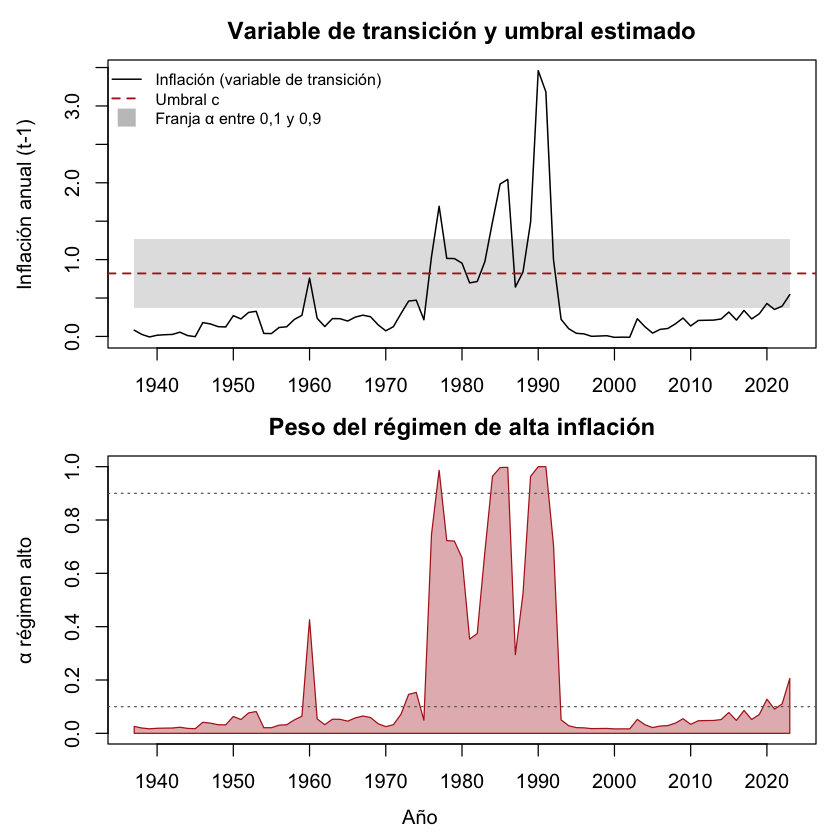

In [120]:
graficar_transicion(res, data = df_anual_comb, endog = c("impp_usa", "E", "ipc", "PBIcf"),
                    archivo = paste0(carpeta, "transicion_impp_usa_vlstar_3f_p1_anual_comb"))

### Comparación con el TVAR principal y el VLSTAR en dos etapas

In [124]:
nms <- c("ic_tvar_p1", "ic_vlstar_p1", "ic_vlstar_3f_p1")
do.call(rbind, mget(nms[sapply(nms, exists)]))

,modelo,regimenes,parametros,loglik,AIC,HQ,BIC
,<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
ic_tvar_p1,TVAR p=1,2,61,-233.71,589.4,650,739.8
ic_vlstar_3f_p1,VLSTAR 3 etapas p=1,2,62,-234.21,592.4,654,745.3


## VLSTAR gaussiano (dos etapas)

En la versión trimestral quedó descartado: las soluciones válidas ajustaban peor que el TVAR, y las de mayor verosimilitud tenían la covarianza del régimen de hiperinflación casi singular. Con datos anuales, revisar el diagnóstico (`explorar_optimos`) antes de usarlo.


Se cargó exitosamente modelos preguardados  vlstar_1_2_500_827bf0b1f3f7e97b528e8b2c99ed1601.rds  de la carpeta models

 >>> DIAGNOSTIC PLOTS


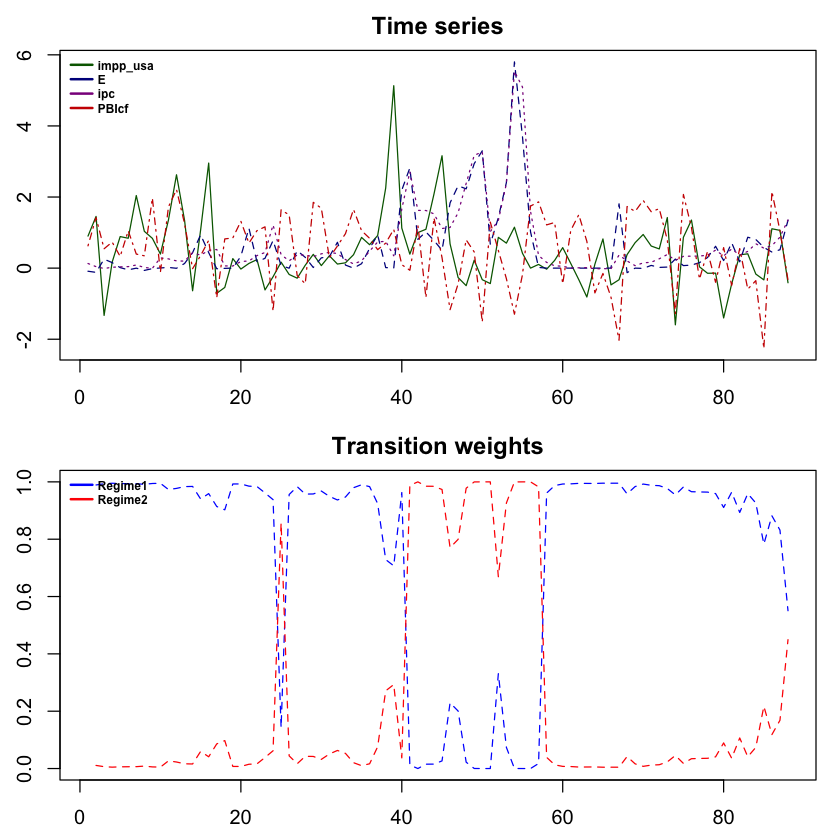

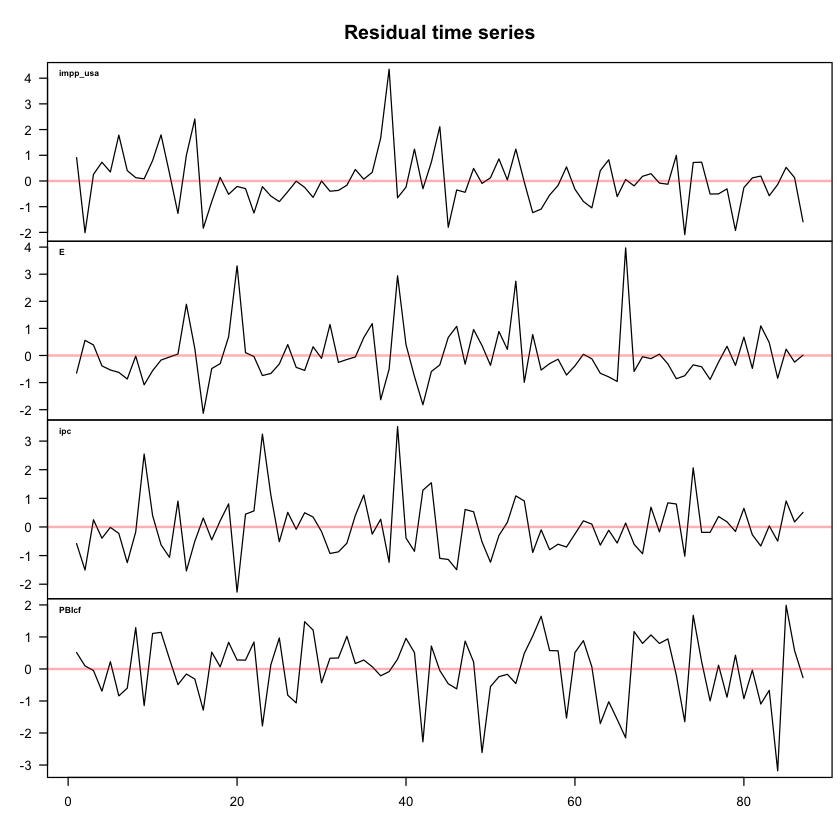

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



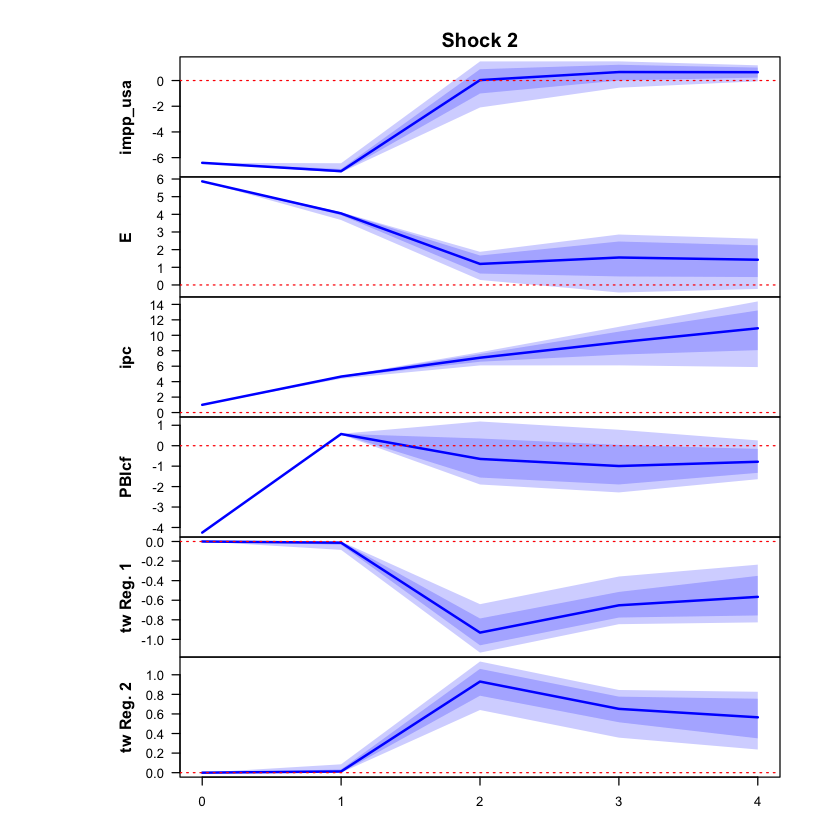

 >>> Linear IRF ( 1  shock units)


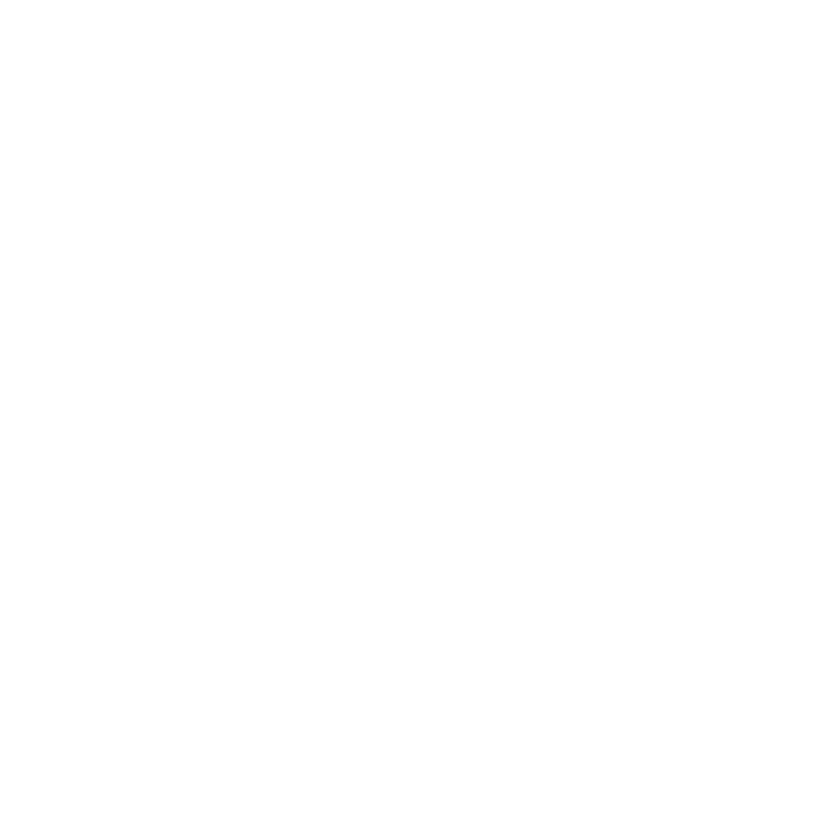

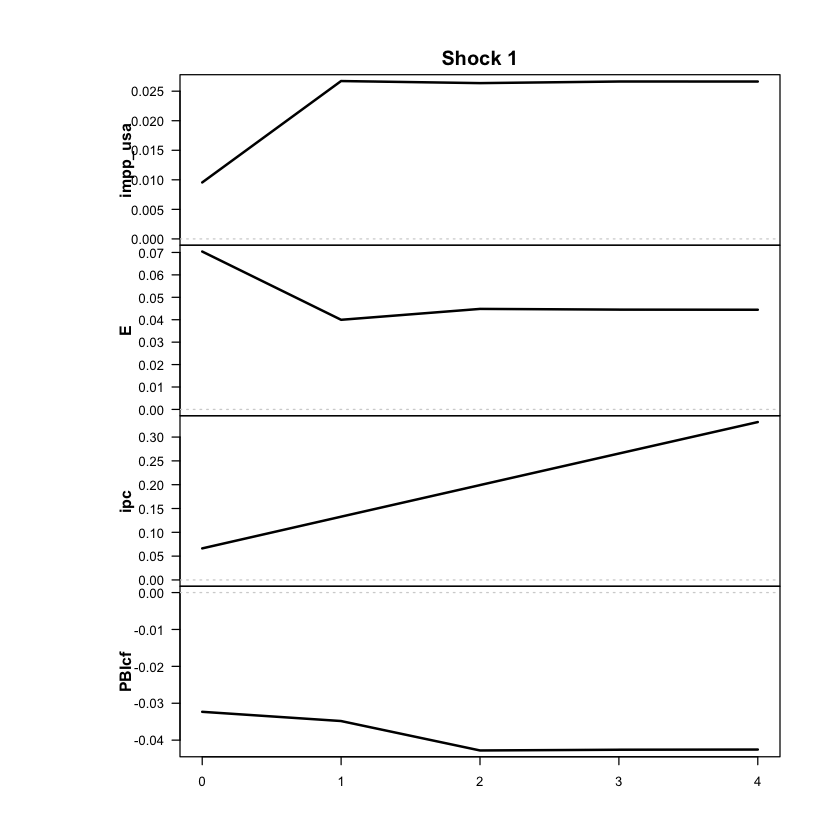

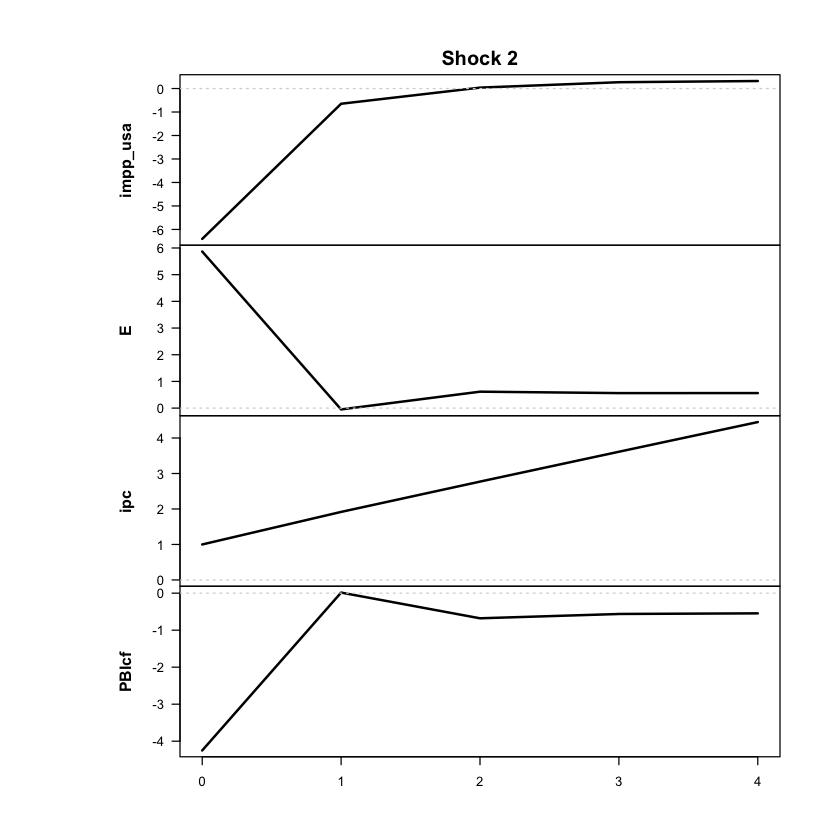

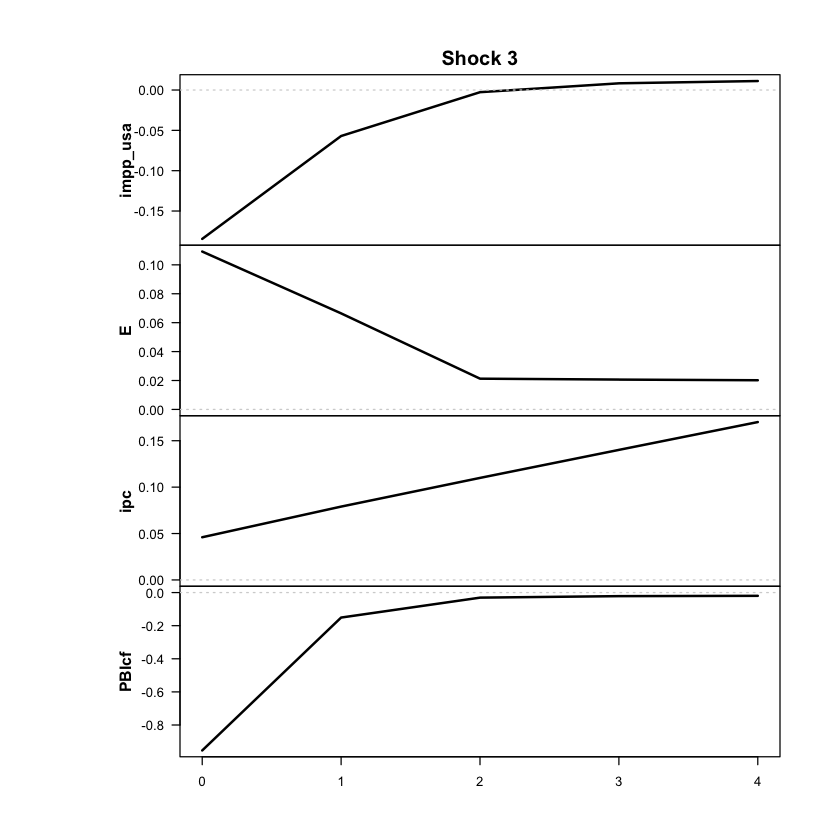

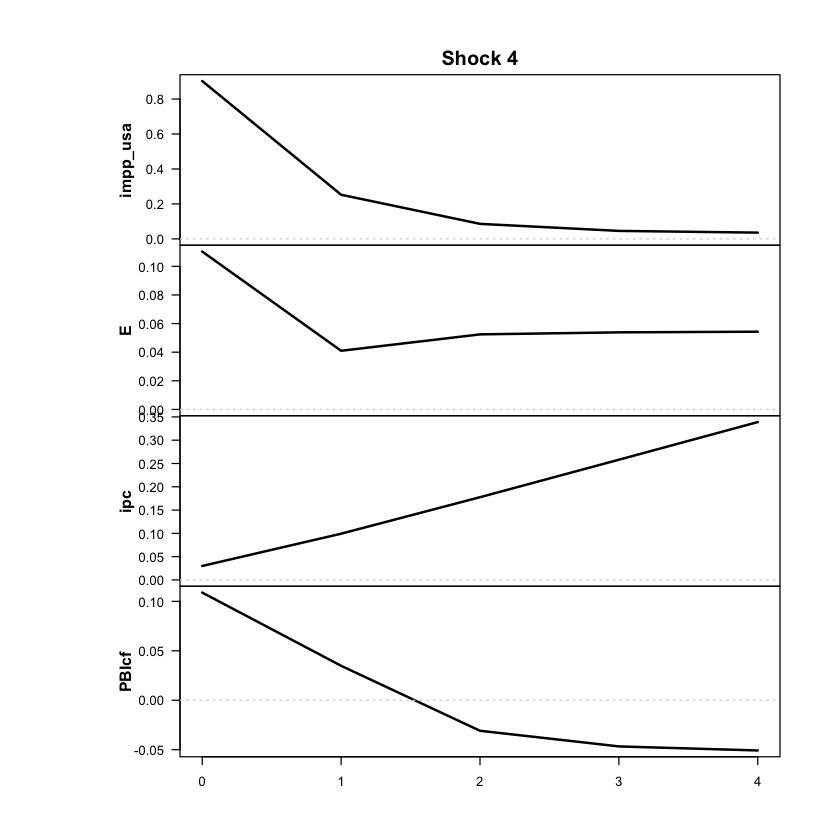

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



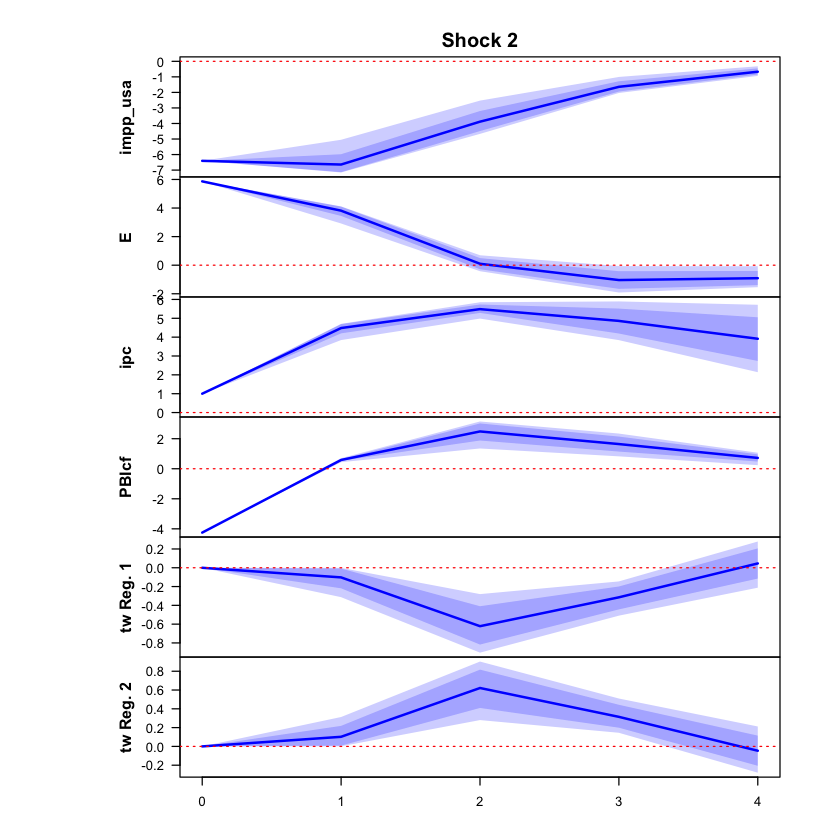

 >>> Linear IRF ( 1  shock units)


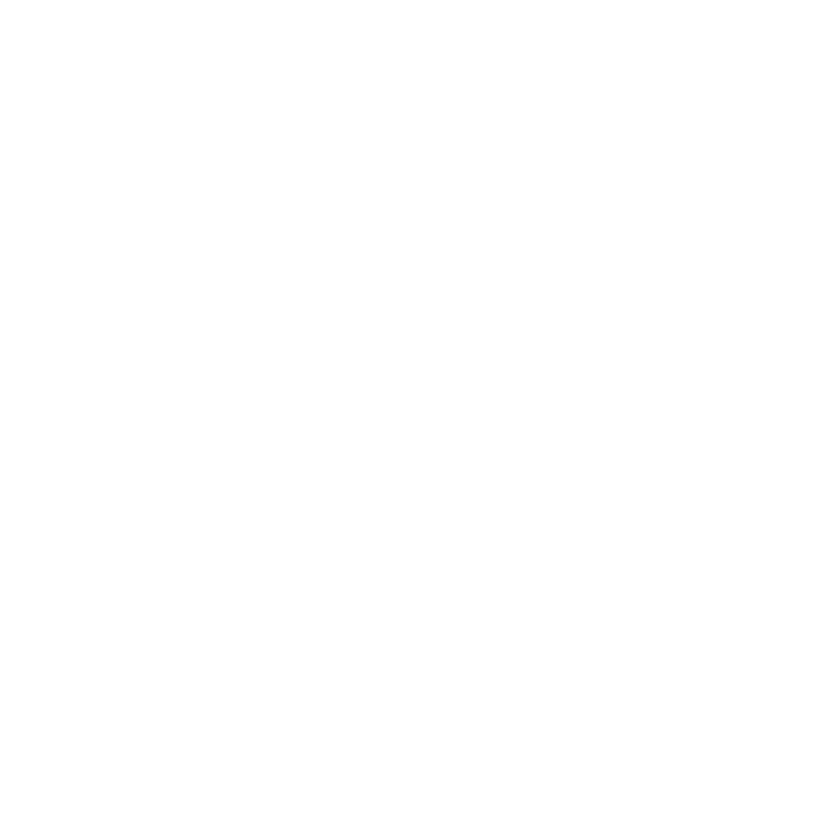

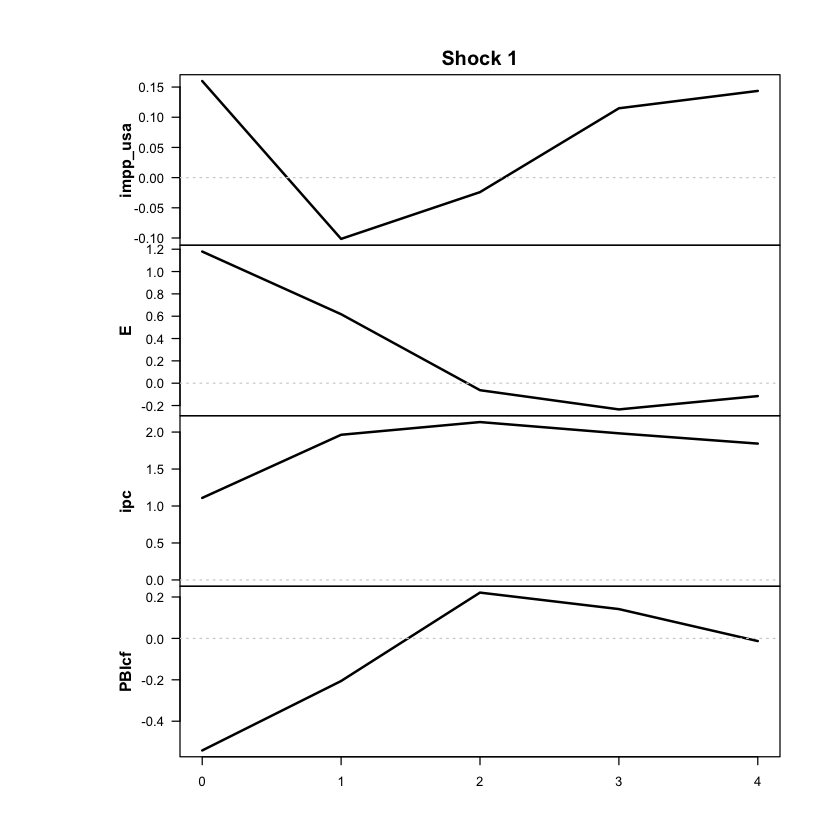

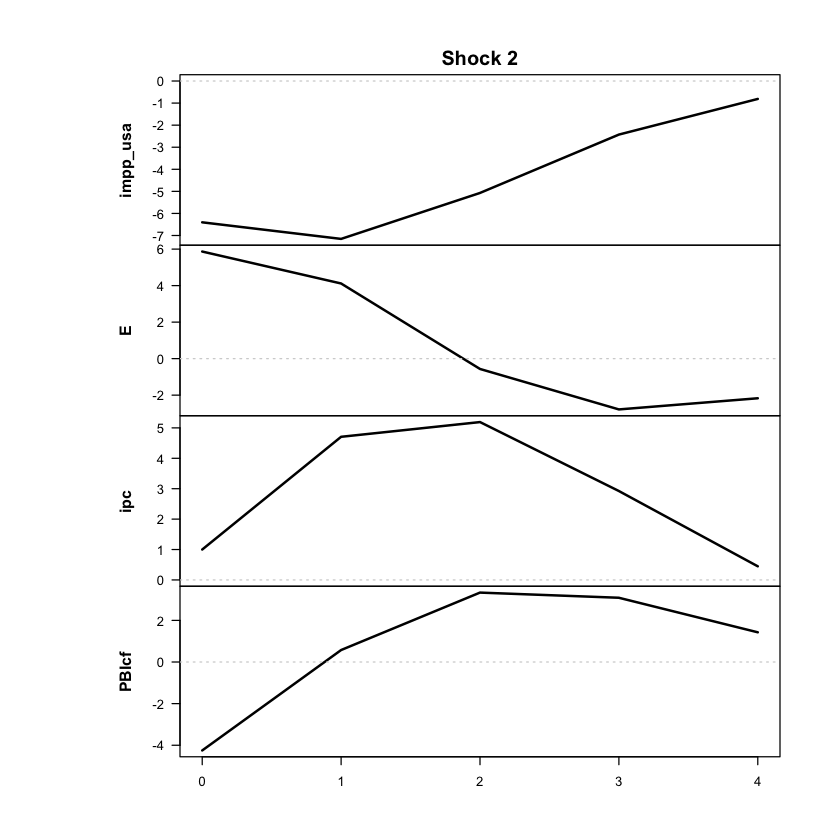

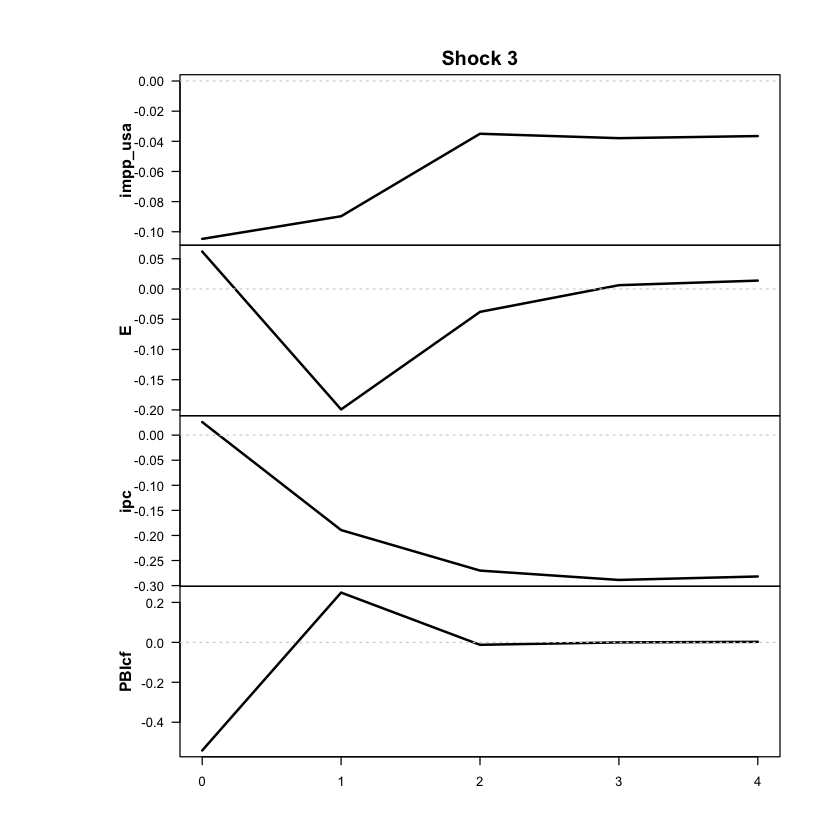

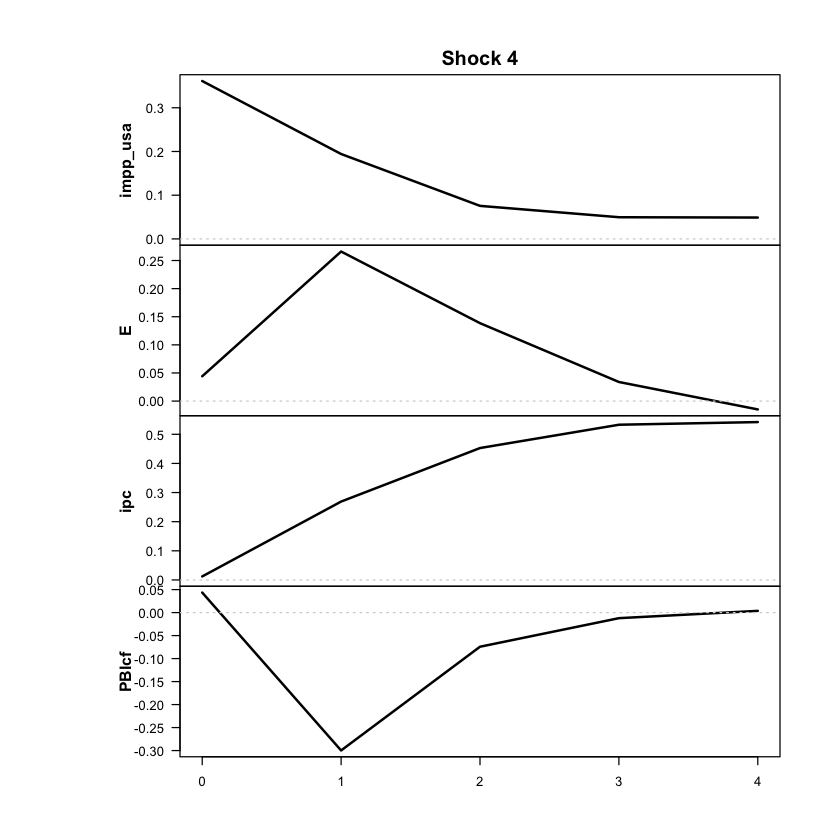

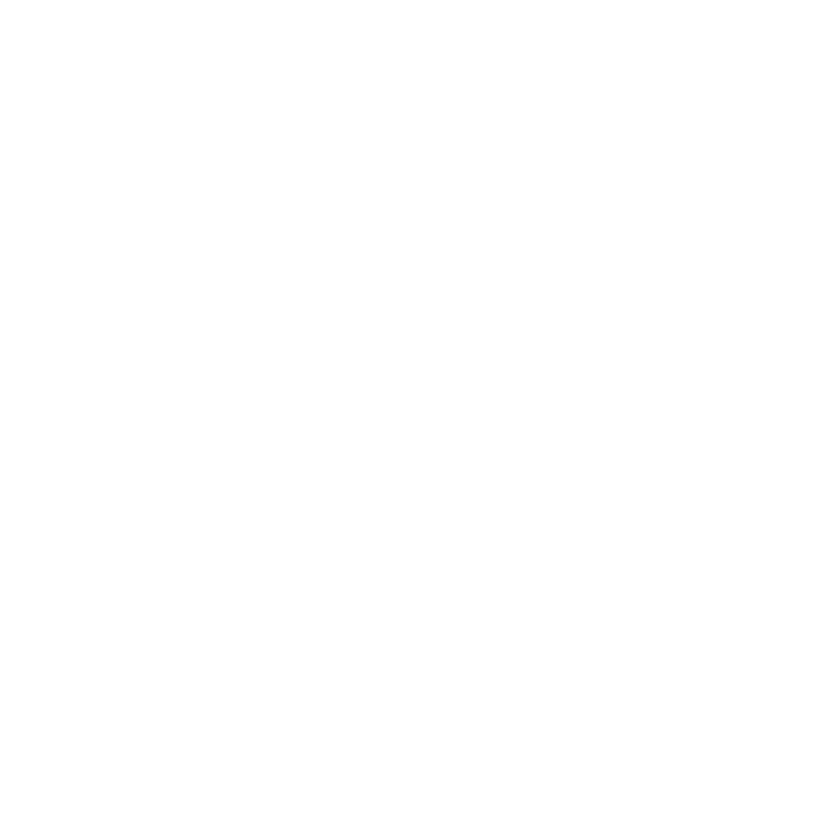

In [28]:
res <- run_vlstar (
  data = df_anual_comb,
  endog = c("impp_usa","E","ipc","PBIcf"),
  periodicity = 'anual', # 'trimestral' o 'anual'
  feature_lag = 1,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIcf")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = TRUE   # primera corrida: estimar. Después de guardado, cambiar a TRUE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [29]:
ic_vlstar_p1 <- criterios_info(res, "VLSTAR p=1")
print(ic_vlstar_p1)
saveRDS(ic_vlstar_p1, "ic_vlstar_p1_anual_comb.rds")
explorar_optimos(res, n = 20)

      modelo regimenes parametros  loglik   AIC  HQ   BIC
1 VLSTAR p=1         2         62 -231.23 586.5 648 739.3
umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -225.79           115.7  3.40         NA            73/14
             2 -226.25           112.1  3.32         NA            72/15
             3 -231.23            76.2  5.81         NA            69/18
             4 -232.36           147.3  3.47         NA            74/13
             5 -233.58             118  3.01         NA            73/14
             6 -234.34            76.8  5.50         NA            69/18
             7 -237.91           116.6  3.06     

In [ ]:
#Ver si es útil
print_passthrough(res, endog = c("impp_usa","E","ipc","PBIcf"))

+++++++++ RÉGIMEN  1 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0       0.1656
1         1       0.7709
2         2       1.1822
3         3       1.5259
4         4       1.8375

>>> IRF lineal normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
1         0       0.1656
2         1       0.3175
3         2       0.4589
4         3       0.5982
5         4       0.7367

+++++++++ RÉGIMEN  2 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0       0.1656
1         1       0.7393
2         2       0.9102
3         3       0.8230
4         4       0.6849

>>> IRF lineal normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
1         0       0.1656
2         1       0.7793
3         2       0.8595
4         3       0.4841
5         4       0.0742



Desvíos usados para escalar:
  impp_usa          E        ipc      PBIcf 
0.07653640 0.64353427 0.62510191 0.04611195 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -414.567

The largest loglik: -241.699

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -335.809

The largest loglik: -205.812

Filtering inappropriate estimates...

Filtered through 101 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Warning message in warn_eigens(ret, allow_unstab = allow_unstab):
“Regime 2 has near-unit-roots! Consider building a model from the next-largest local maximum with the function 'alt_stvar' by adjusting its argument 'which_largest' (or use the function 'filter_estimates').”
Finished!




========= Unstructured fitted model ==========


Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


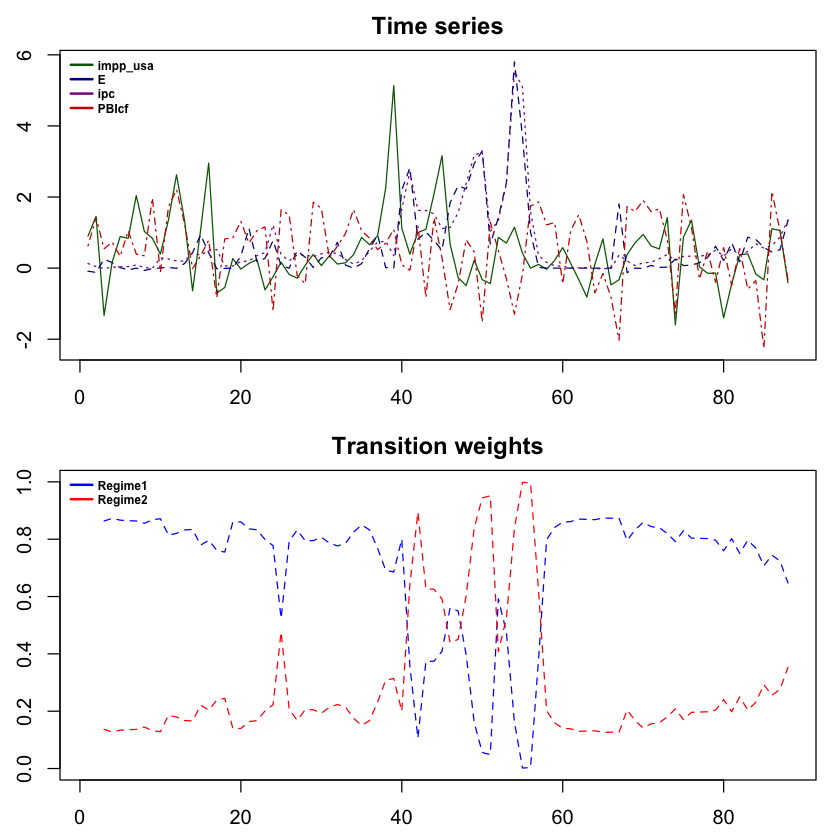

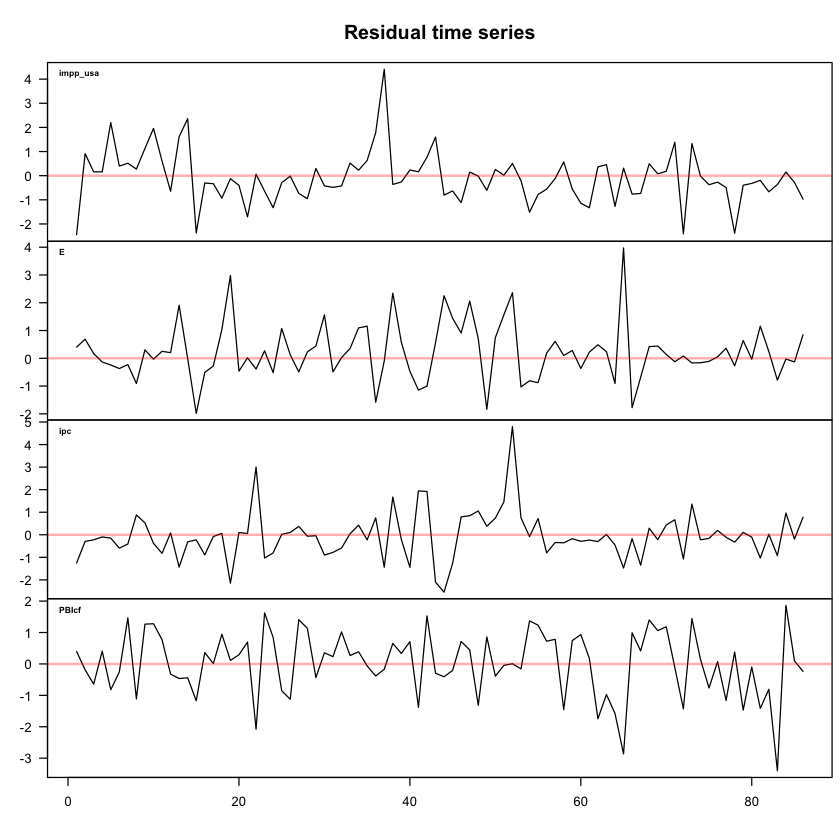

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



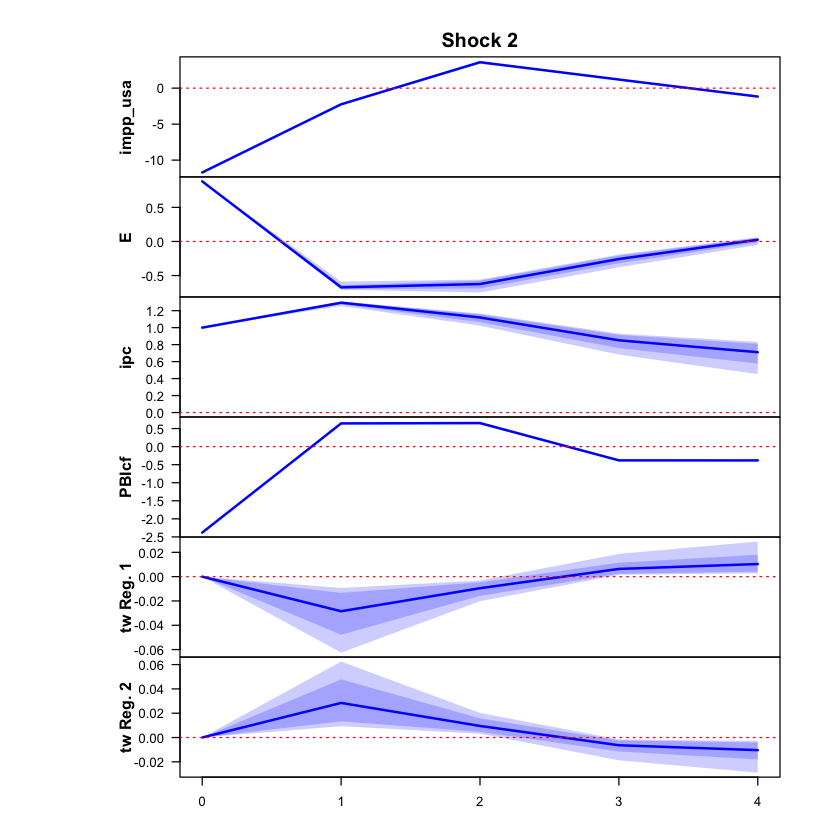

 >>> Linear IRF ( 1  shock units)


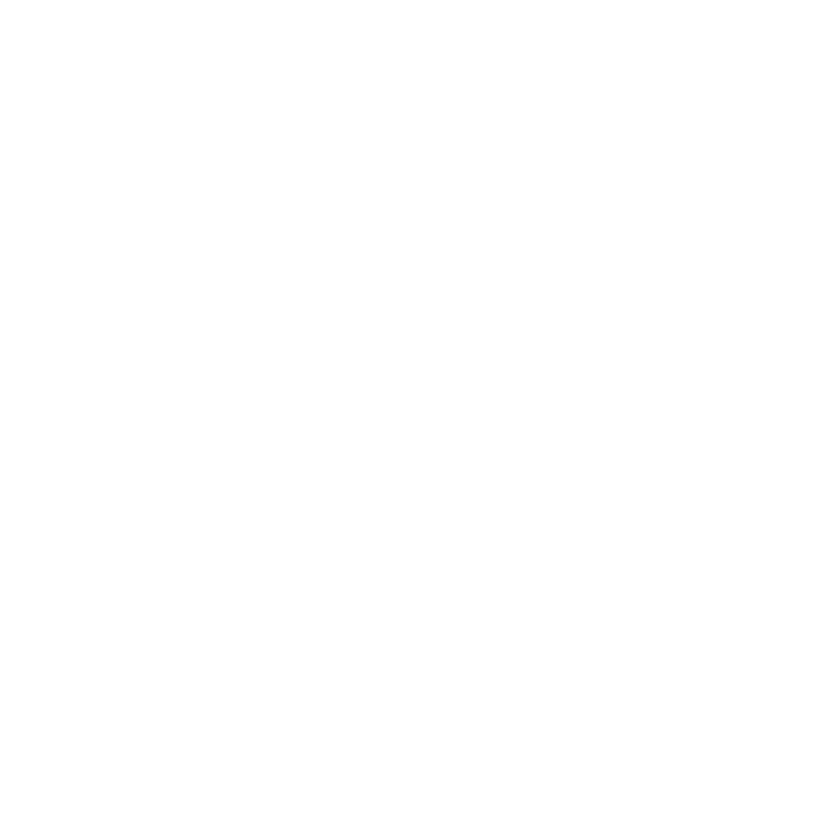

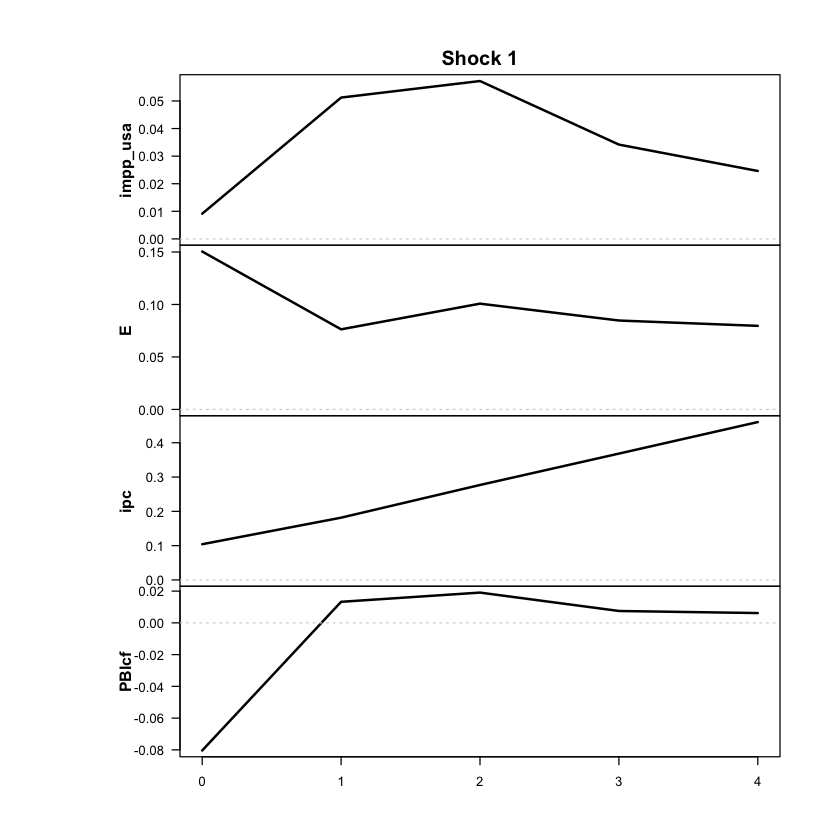

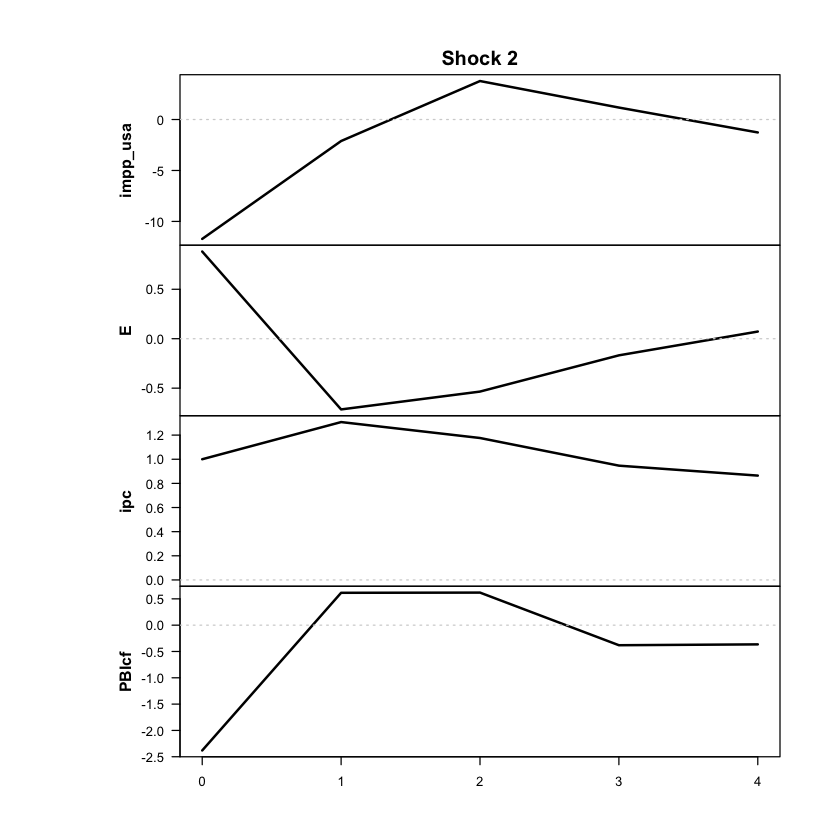

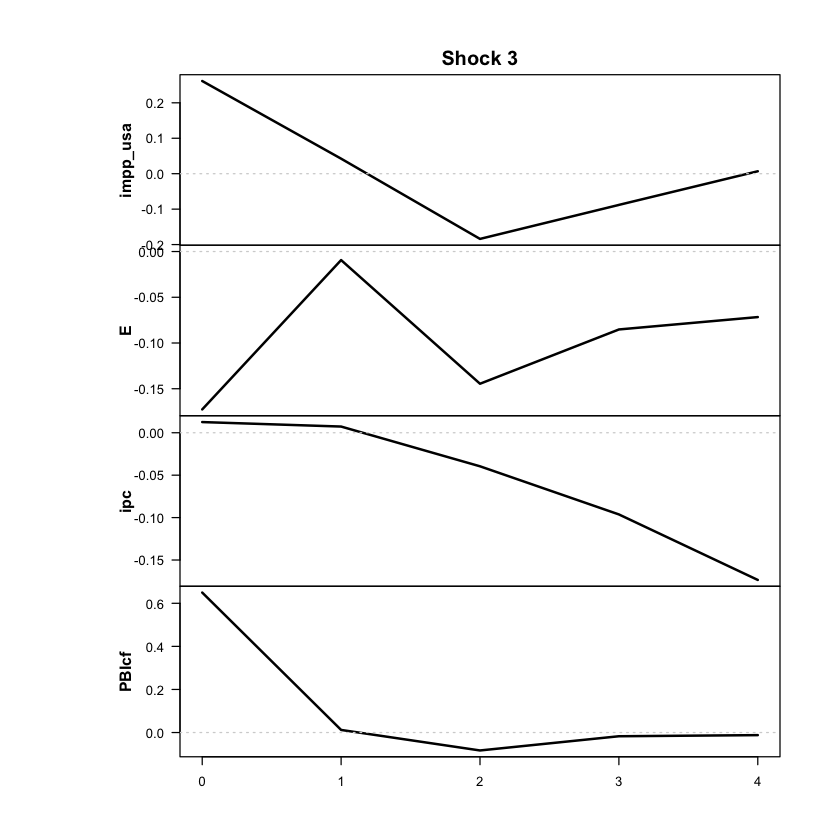

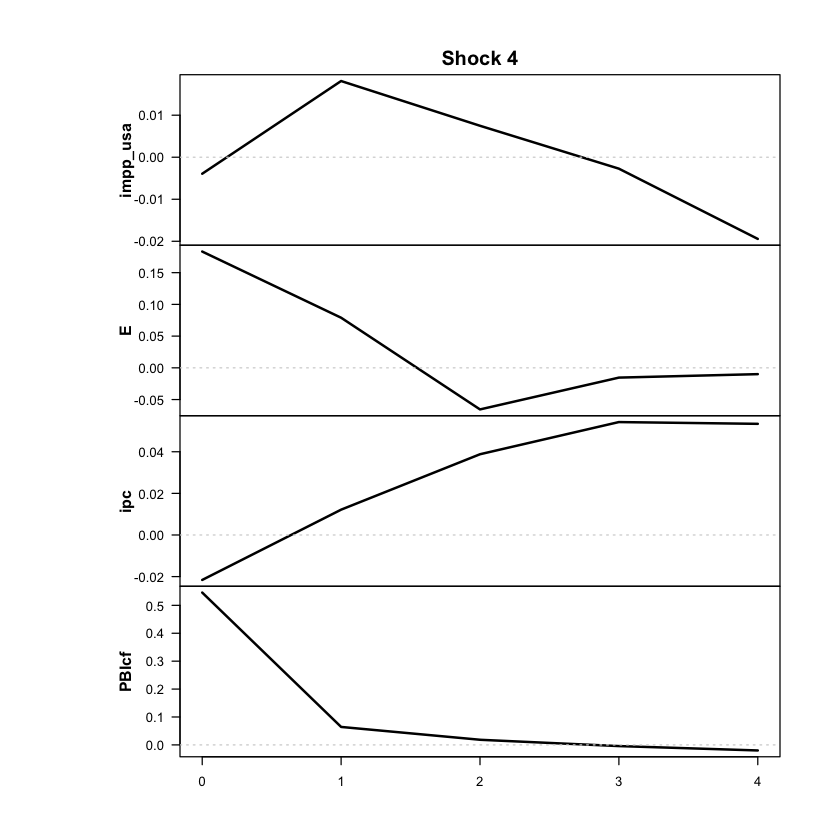

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



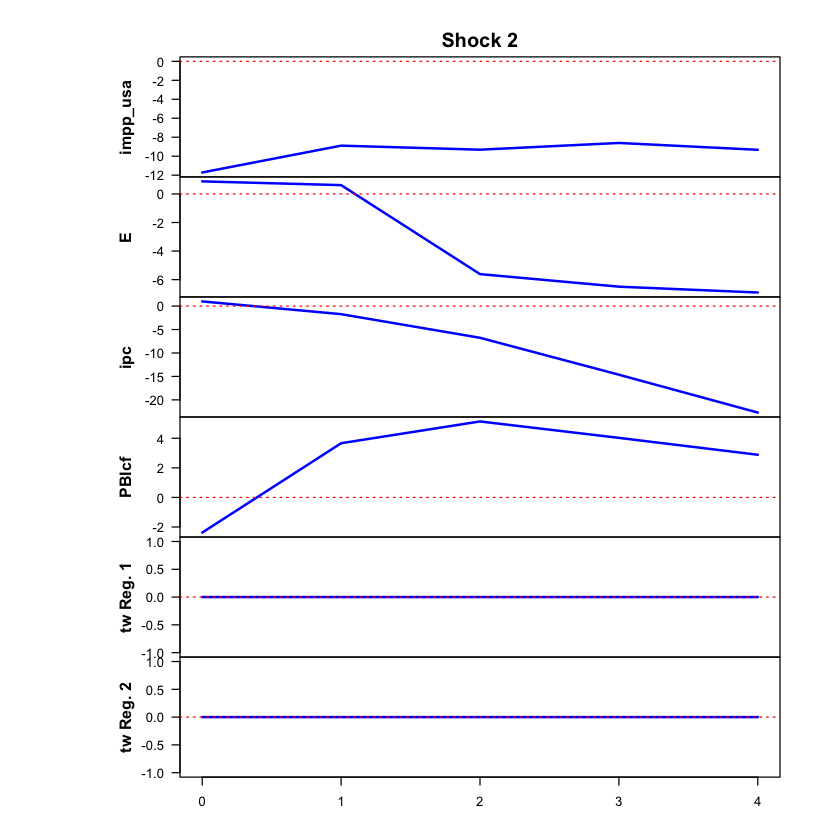

 >>> Linear IRF ( 1  shock units)


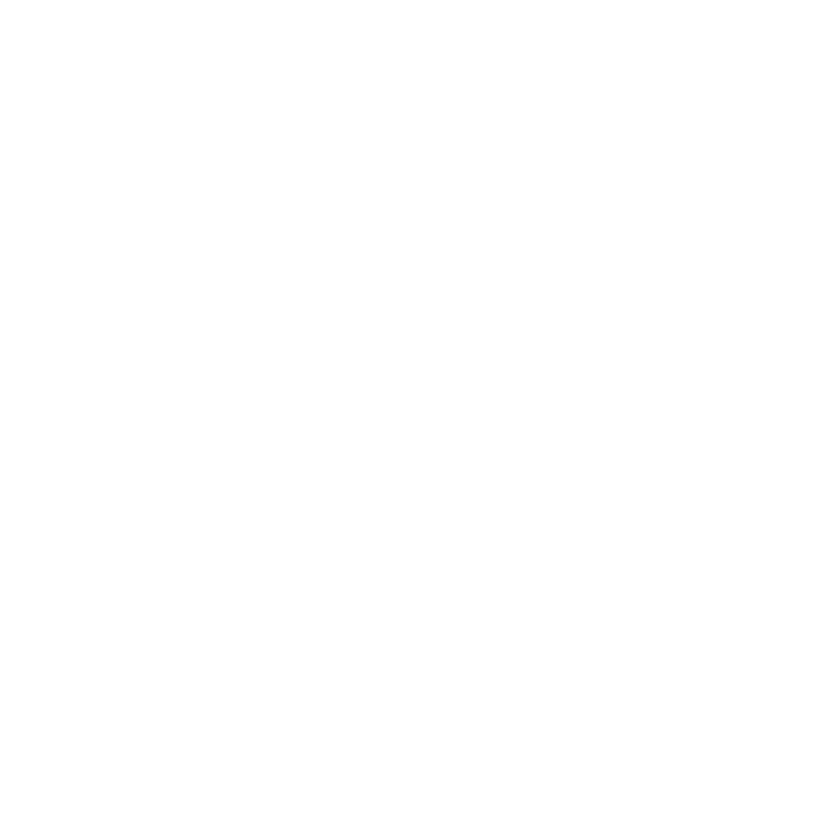

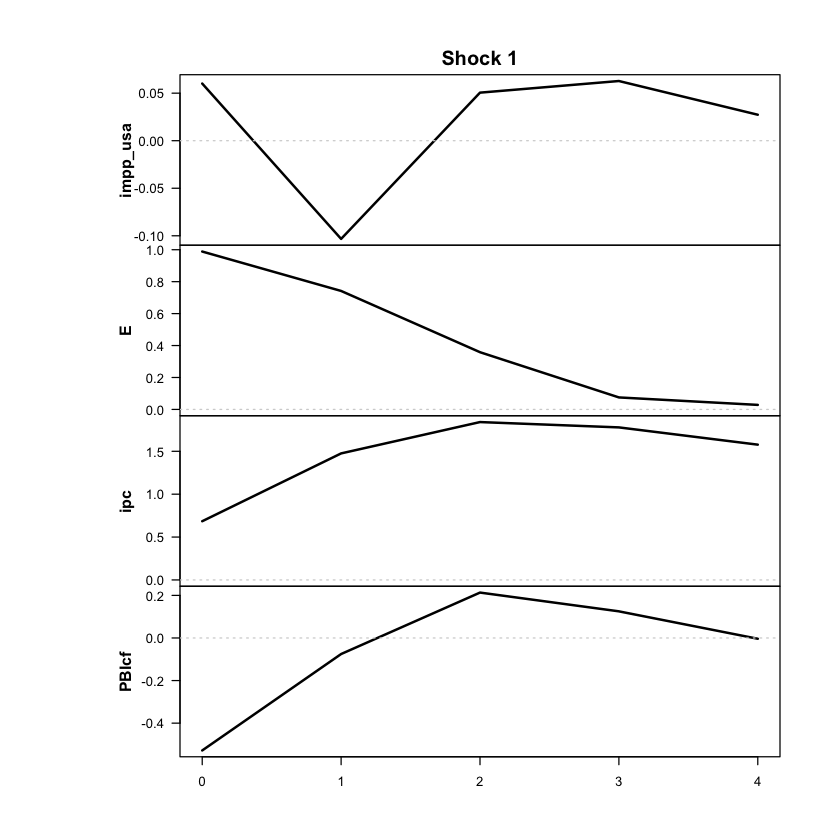

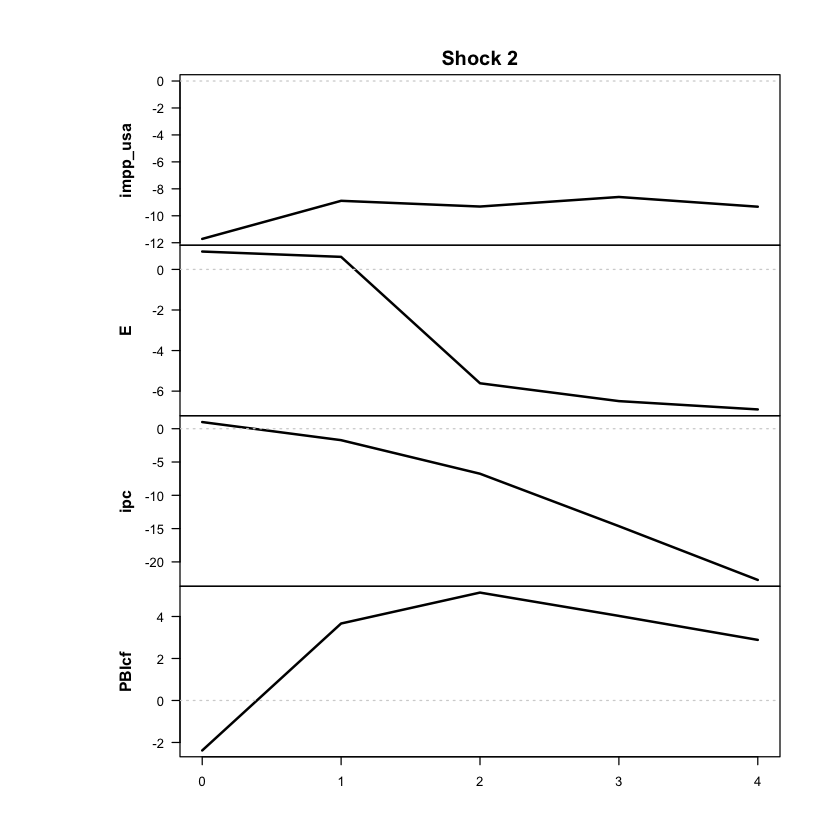

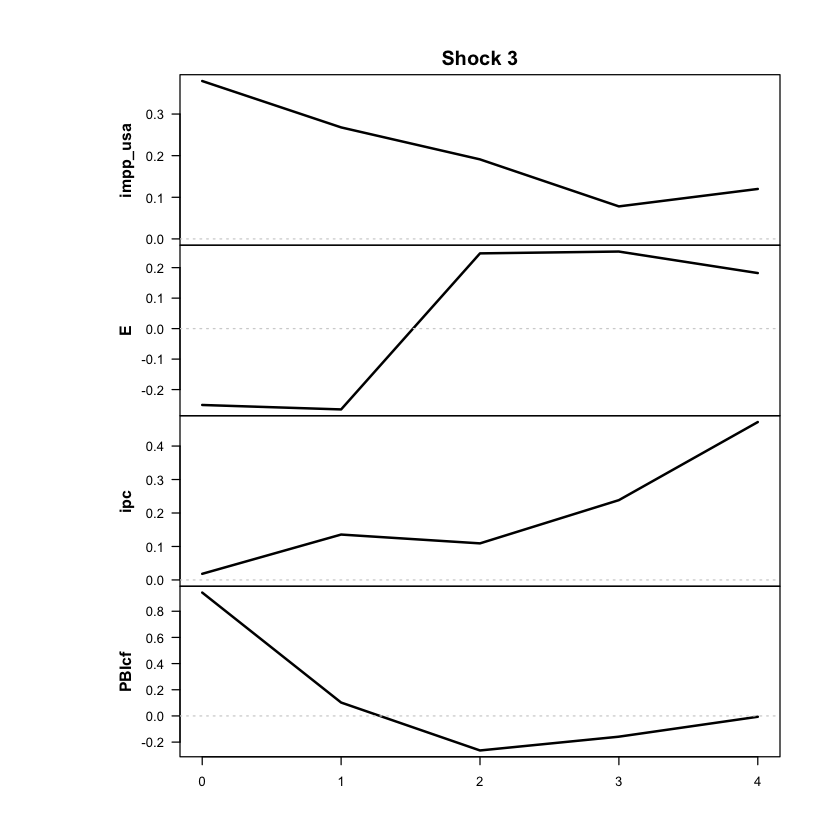

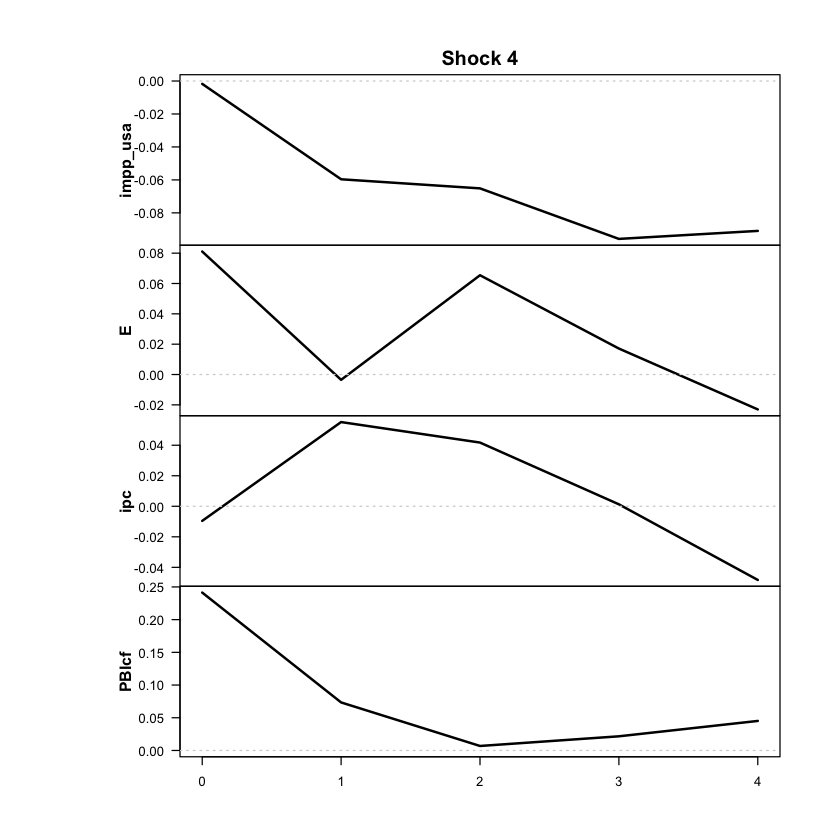

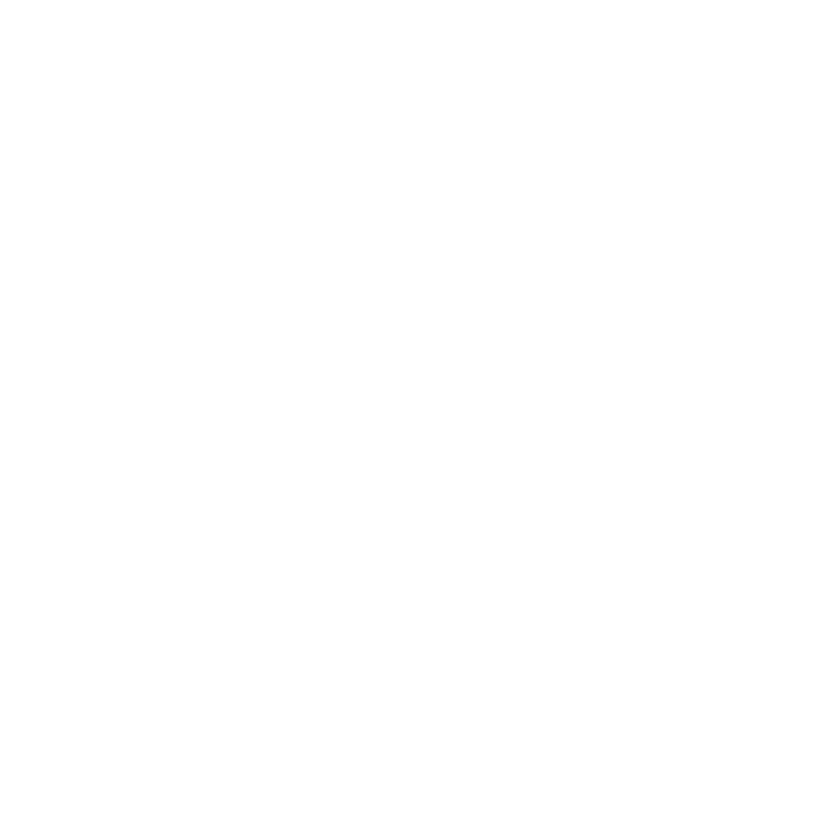

In [15]:
res <- run_vlstar (
  data = df_anual_comb,
  endog = c("impp_usa","E","ipc","PBIcf"),
  periodicity = 'anual', # 'trimestral' o 'anual'
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIcf")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE   # primera corrida: estimar. Después de guardado, cambiar a TRUE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

##### Celda para verificar qué modelo fue el último que se corrió

In [21]:
c(tipo = res$tvar_model$model$weight_function, p = res$tvar_model$model$p,
  errores = res$tvar_model$model$cond_dist)

tipo          p    errores 
"logistic"        "2" "Gaussian"

In [18]:
ic_vlstar_p2 <- criterios_info(res, "VLSTAR p=2")
print(ic_vlstar_p2)
saveRDS(ic_vlstar_p2, "ic_vlstar_p2_anual_comb.rds")
explorar_optimos(res, n = 20)

      modelo regimenes parametros  loglik   AIC    HQ   BIC
1 VLSTAR p=2         2         94 -272.31 732.6 825.5 963.3
umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -205.81           106.6  4.16         NA            71/15
             2 -226.61           127.4  3.49         NA            72/14
             3 -226.98           120.2  2.72         NA            72/14
             4 -232.82           115.5  2.06         NA            72/14
             5 -234.51           189.6  2.64         NA             79/7
             6 -235.25           144.8  2.33         NA            73/13
             7 -236.79           192.9  3.05 

In [33]:
rbind(ic_tvar_p1, ic_vlstar_p1, ic_vlstar_3f_p1)
# Si ic_tvar_p1 o ic_vlstar_p1 no están en memoria, correr antes sus celdas con load_presaved = TRUE y criterios_info().

modelo,regimenes,parametros,loglik,AIC,HQ,BIC
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
TVAR p=1,2,61,-233.71,589.4,650,739.8
VLSTAR p=1,2,62,-231.23,586.5,648,739.3
VLSTAR 3 etapas p=1,2,62,-234.21,592.4,654,745.3


# TEST de autocorrelación y de heterocedasticidad

Fuente: https://rdrr.io/cran/sstvars/man/Portmanteau_test.html

In [ ]:
portmanteau_guardados <- function(data, rezagos_test = c(8, 12), carpeta = "models") {
  archivos <- list.files(carpeta, pattern = "\\.rds$", full.names = TRUE)
  archivos <- archivos[!grepl("^structured_", basename(archivos))]
  pval <- function(t) {
    nm <- grep("p_val|pval|p.val", names(t), value = TRUE)
    if (length(nm)) as.numeric(t[[nm[1]]]) else NA
  }
  etiqueta <- function(m) {
    wf <- m$model$weight_function
    tipo <- switch(if (is.null(wf)) "" else wf,
                   threshold = "TVAR", logistic = "VLSTAR", mlogit = "MLOGIT", "?")
    cd <- m$model$cond_dist
    if (!is.null(cd) && cd != "Gaussian") tipo <- paste0(tipo, "-t")
    tipo
  }
  filas <- list()
  for (f in archivos) {
    m <- tryCatch(readRDS(f), error = function(e) NULL)
    if (is.null(m) || is.null(m$data) || is.null(m$model)) next
    Y <- as.matrix(m$data); vars <- colnames(Y)
    if (!all(vars %in% names(data)) || nrow(data) != nrow(Y)) next
    X <- as.matrix(data[, vars]); X <- sweep(X, 2, apply(X, 2, sd, na.rm = TRUE), "/")
    if (!isTRUE(all.equal(unname(X), unname(Y), tolerance = 1e-6))) next
    for (L in rezagos_test) {
      ac <- tryCatch(Portmanteau_test(m, nlags = L, which_test = "autocorr"), error = function(e) NULL)
      hs <- tryCatch(Portmanteau_test(m, nlags = L, which_test = "het.sked"), error = function(e) NULL)
      filas[[length(filas) + 1]] <- data.frame(
        commodity = vars[1],
        modelo    = etiqueta(m),
        archivo   = basename(f),
        regimenes = m$model$M, rezagos = m$model$p, rezagos_test = L,
        p_autocorr = round(if (is.null(ac)) NA else pval(ac), 3),
        p_heterosc = round(if (is.null(hs)) NA else pval(hs), 3))
    }
  }
  tab <- do.call(rbind, filas)
  tab <- tab[order(tab$commodity, tab$modelo, tab$regimenes, tab$rezagos, tab$rezagos_test), ]
  print(tab, row.names = FALSE)
  invisible(tab)
}

# Solo los modelos con impp_usa (los viejos de commodities quedan afuera)
port_sincap <- portmanteau_guardados(df_anual_comb, rezagos_test = c(4, 8))
port_impp <- port_sincap[port_sincap$commodity == "impp_usa", ]   # la función ya imprime la tabla